# REFIT: data cleaning and washing-machine disaggregation

## 1. Basic inspection and cleaning (House 1, raw data)

### Imports and config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAW_PART1 = "DATA/REFIT_RAW_081116/RAW_House1_Part1.csv"
RAW_PART2 = "DATA/REFIT_RAW_081116/RAW_House1_Part2.csv"
OUT_DIR = Path("outputs")
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "tables").mkdir(parents=True, exist_ok=True)

APPLIANCE_NAMES = {   # from README, House 1
    "Appliance1": "Fridge", "Appliance2": "Freezer(1)", "Appliance3": "Freezer(2)",
    "Appliance4": "Washer Dryer", "Appliance5": "Washing Machine", "Appliance6": "Dishwasher",
    "Appliance7": "Computer", "Appliance8": "Television Site", "Appliance9": "Electric Heater",
}
IAM_COLS = [f"Appliance{i}" for i in range(1, 10)]
cols = ["Aggregate"] + IAM_COLS
RESAMPLE = "1min"
MAX_FILL_GAP_MIN = 5        # gaps <= 5 min are interpolated (per channel)
OUTAGE_GAP_MIN = 5          # aggregate gaps > 5 min are flagged as outage, left NaN
SPIKE_W = 4000              # same threshold the official cleaning uses for IAMs
AGG_IMPOSSIBLE_W = 23000    # about 100 A x 230 V, the largest normal UK domestic supply: above this is a sensor error
AGG_EXTREME_W = 10000       # possible but rare: only removed if it is an isolated one-sample spike
ISSUE_TOL_W = 10            # sensors are not synchronised, so allow a small tolerance on sum(IAMs) > aggregate
pd.set_option("display.width", 200)

def savefig(name):
    plt.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")


### Load raw data

In [2]:
DTYPES = {c: "float32" for c in cols}
p1 = pd.read_csv(RAW_PART1, dtype=DTYPES)
p2 = pd.read_csv(RAW_PART2, dtype=DTYPES)
print("Part1:", p1.shape, "| Part2:", p2.shape)

# check if overlap of 2 file is same
def minute_mean(d):
    t = pd.to_datetime(d["Unix"], unit="s")
    return d.set_index(t)["Aggregate"].sort_index().resample("1min").mean()

a, b = minute_mean(p1), minute_mean(p2)
lo, hi = b.index.min(), a.index.max()
x, y = a[lo:hi], b[lo:hi]
both = x.notna() & y.notna()
print(f"\nOverlap: {lo} -> {hi}")
print(f"Minutes with aggregate data: Part1 {x.notna().sum():,}, Part2 {y.notna().sum():,}, both {both.sum():,}")
print(f"Mean aggregate where both have data: Part1 {x[both].mean():.1f} W, Part2 {y[both].mean():.1f} W")
print(f"Median absolute difference: {(x - y)[both].abs().median():.1f} W")

Part1: (4377877, 12) | Part2: (4140886, 12)

Overlap: 2014-06-27 21:57:00 -> 2014-10-01 01:27:00
Minutes with aggregate data: Part1 125,956, Part2 128,492, both 121,407
Mean aggregate where both have data: Part1 354.6 W, Part2 354.9 W
Median absolute difference: 1.3 W


### Join Part1 and Part2
They agree closely in the overlap (median difference 1.3 W). I used Part1 up to the first Part2 timestamp and Part2 after it, because Part2 marks missing sensors as NaN instead of 0.

In [3]:
# Join: Part1 up to the first Part2 timestamp, Part2 from there on
cut = p2["Unix"].min()
raw = pd.concat([p1[p1["Unix"] < cut], p2], ignore_index=True)
print(f"Part1 rows dropped (inside the overlap): {(p1['Unix'] >= cut).sum():,}")
print("Joined:", raw.shape)
del p1, p2, a, b, x, y, both
raw.head()

Part1 rows dropped (inside the overlap): 1,257,865
Joined: (7260898, 12)


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0


### Timestamps and ordering
Unix is the key

In [4]:
raw["Time_parsed"] = pd.to_datetime(raw["Time"], errors="coerce")
raw["Unix_parsed"] = pd.to_datetime(raw["Unix"], unit="s", errors="coerce")

print("Unparseable Time:", raw["Time_parsed"].isna().sum(), "| Unparseable Unix:", raw["Unix_parsed"].isna().sum())
for k in ["Time_parsed", "Unix_parsed"]:
    print(f"{k}: monotonic={raw[k].is_monotonic_increasing}, "
          f"out-of-order rows={(raw[k].diff() < pd.Timedelta(0)).sum()}, "
          f"range={raw[k].min()} -> {raw[k].max()}")

# Full-precision comparison (seconds, no rounding): is Time the same clock as Unix?
diff_s = (raw["Time_parsed"] - raw["Unix_parsed"]).dt.total_seconds()
print("\nTime minus Unix (seconds):")
print(diff_s.value_counts())
print("Rows where Time != Unix:", (diff_s != 0).sum())
print("Duplicate Time values:", raw["Time"].duplicated().sum(), "| Duplicate Unix values:", raw["Unix"].duplicated().sum())

Unparseable Time: 0 | Unparseable Unix: 0
Time_parsed: monotonic=False, out-of-order rows=1, range=2013-10-09 14:06:17 -> 2015-07-10 11:56:32
Unix_parsed: monotonic=False, out-of-order rows=1, range=2013-10-09 14:06:17 -> 2015-07-10 11:56:32

Time minus Unix (seconds):
0.0    3723398
1.0    3537500
Name: count, dtype: int64
Rows where Time != Unix: 3537500
Duplicate Time values: 348686 | Duplicate Unix values: 597182


### Is `Time` UTC or UK local?

In [5]:
# Test both hypotheses for the Time column against Unix (which is UTC)
unix_utc = raw["Unix_parsed"].dt.tz_localize("UTC")
as_utc = (raw["Time_parsed"].dt.tz_localize("UTC") - unix_utc).dt.total_seconds()
as_uk = (raw["Time_parsed"]
         .dt.tz_localize("Europe/London", ambiguous="NaT", nonexistent="NaT")
         .dt.tz_convert("UTC") - unix_utc).dt.total_seconds()

for name, d in [("Time as UTC", as_utc), ("Time as UK local", as_uk)]:
    print(f"{name}: within 0-1 s of Unix in {d.isin([0, 1]).mean():.1%} of rows "
          f"({d.isna().sum():,} DST-ambiguous rows undefined)")

Time as UTC: within 0-1 s of Unix in 100.0% of rows (0 DST-ambiguous rows undefined)
Time as UK local: within 0-1 s of Unix in 47.8% of rows (2,185 DST-ambiguous rows undefined)


`Time` matches `Unix` read as UTC in 100% of rows (47.8% as UK local), so the raw clock is UTC. 

### Duplicate timestamps
597,182 rows share a `Unix` second with another row: 508,829 are exact copies, 88,353 have different values (rule below).

In [6]:
vals = [c for c in raw.columns if c.startswith(("Aggregate", "Appliance"))]
for key in ["Unix", "Time"]:
    dup_ts = raw.duplicated(subset=[key]).sum()
    dup_full = raw.duplicated(subset=[key] + vals).sum()
    print(f"[{key}] duplicate rows: {dup_ts:,} | identical copies: {dup_full:,} | conflicting values: {dup_ts - dup_full:,}")

[Unix] duplicate rows: 597,182 | identical copies: 508,829 | conflicting values: 88,353
[Time] duplicate rows: 348,686 | identical copies: 321,692 | conflicting values: 26,994


### Irregular intervals and gaps
Readings come every ~7 s (median). 25 gaps last over 1 hour (1,905 h in total, the largest 998 h in Jan-Mar 2014).

In [7]:
dt = raw["Unix"].sort_values().drop_duplicates().diff().dropna()
print(dt.describe())
print("\nMost common intervals (s):")
print(dt.value_counts().head(10))

bins = [0, 5, 10, 20, 60, 300, 3600, 86400, np.inf]
print("\nInterval distribution:")
print(pd.cut(dt, bins).value_counts().sort_index())

big = dt[dt > 3600]
gaps = pd.DataFrame({
    "gap_start": pd.to_datetime(raw["Unix"].sort_values().drop_duplicates().shift(1).loc[big.index], unit="s"),
    "gap_hours": (big / 3600).round(1),
}).sort_values("gap_hours", ascending=False)
print(f"\nGaps > 1h: {len(gaps)}; total missing hours: {gaps['gap_hours'].sum():.0f}")
gaps.head(10)

count    6.663715e+06
mean     8.283940e+00
std      1.466678e+03
min      1.000000e+00
25%      6.000000e+00
50%      7.000000e+00
75%      8.000000e+00
max      3.594414e+06
Name: Unix, dtype: float64

Most common intervals (s):
Unix
7.0     1795168
6.0      966918
8.0      919388
2.0      787327
13.0     454462
9.0      410774
11.0     276459
15.0     234120
4.0      232228
5.0      231596
Name: count, dtype: int64

Interval distribution:
Unix
(0.0, 5.0]           1470159
(5.0, 10.0]          4133901
(10.0, 20.0]         1052043
(20.0, 60.0]            3466
(60.0, 300.0]           3747
(300.0, 3600.0]          374
(3600.0, 86400.0]         13
(86400.0, inf]            12
Name: count, dtype: int64

Gaps > 1h: 25; total missing hours: 1905


,gap_start,gap_hours
1496321,2014-01-24 01:56:25,998.4
6718326,2015-05-10 23:36:10,207.6
6973989,2015-06-10 13:19:01,180.3
3759056,2014-08-28 04:23:04,108.5
6287082,2015-04-03 01:43:17,104.6
6190846,2015-03-22 08:15:59,55.1
6779915,2015-05-24 10:09:41,50.0
4372871,2014-10-27 00:05:00,37.7
6274805,2015-03-31 04:22:36,36.1
6118353,2015-03-15 10:02:16,30.2


### Missing values and outliers
No negative values. Appliance spikes above 4,000 W exist (e.g. 799 readings on the fridge, 70 on the washing machine) and the aggregate reaches 29 kW.

In [8]:
IAM_COLS = [f"Appliance{i}" for i in range(1, 10)]
cols = ["Aggregate"] + IAM_COLS

print("NaN counts:\n", raw[cols].isna().sum(), "\n")
print("Negative values:\n", (raw[cols] < 0).sum(), "\n")
print("IAM spikes > %d W (README rule applies to IAMs only):\n" % SPIKE_W,
      (raw[IAM_COLS] > SPIKE_W).sum(), "\n")
print("Aggregate > %d W (informational, not removed): %d rows, max = %d W" %
      (SPIKE_W, (raw["Aggregate"] > SPIKE_W).sum(), raw["Aggregate"].max()), "\n")
complete = raw[cols].notna().all(axis=1)   # rows where all 10 channels reported
print("Sum(IAMs) > Aggregate (README 'Issues' rule, complete rows only):",
      ((raw[IAM_COLS].sum(axis=1) > raw["Aggregate"]) & complete).sum())
print("\nDescribe:")
raw[cols].describe().T

NaN counts:
 Aggregate      188973
Appliance1     437890
Appliance2     459468
Appliance3     311961
Appliance4     510963
Appliance5     497223
Appliance6     342337
Appliance7     232752
Appliance8     390705
Appliance9    1911811
dtype: int64 

Negative values:
 Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64 

IAM spikes > 4000 W (README rule applies to IAMs only):
 Appliance1     799
Appliance2      40
Appliance3     118
Appliance4    1226
Appliance5      70
Appliance6      36
Appliance7     374
Appliance8     176
Appliance9      50
dtype: int64 

Aggregate > 4000 W (informational, not removed): 36101 rows, max = 29159 W 

Sum(IAMs) > Aggregate (README 'Issues' rule, complete rows only): 55700

Describe:


,count,mean,std,min,25%,50%,75%,max
Aggregate,7071925.0,486.474731,816.667664,0.0,185.0,243.0,438.0,29159.0
Appliance1,6823008.0,18.828413,183.560059,0.0,0.0,0.0,0.0,76677.0
Appliance2,6801430.0,16.544474,100.527451,0.0,0.0,0.0,45.0,98301.0
Appliance3,6948937.0,29.185089,81.443375,0.0,0.0,0.0,70.0,73725.0
Appliance4,6749935.0,4.863257,418.920624,0.0,0.0,0.0,0.0,98301.0
Appliance5,6763675.0,11.160849,161.690872,0.0,0.0,0.0,0.0,73725.0
Appliance6,6918561.0,11.272004,159.498672,0.0,0.0,0.0,0.0,37610.0
Appliance7,7028146.0,3.013433,147.757812,0.0,0.0,0.0,0.0,98299.0
Appliance8,6870193.0,6.163994,137.299118,0.0,0.0,0.0,0.0,98301.0
Appliance9,5349087.0,95.271080,304.359711,0.0,1.0,1.0,1.0,65535.0


### Checks behind the cleaning choices
NaNs and zeros by file, how high the aggregate goes, how far duplicate values disagree, and how the sampling interval changes over time.

In [9]:
raw["part"] = np.where(raw["Unix"] < cut, 1, 2).astype("int8")   # which file each row came from

print("NaN cells by file:\n", raw[cols].isna().groupby(raw["part"]).sum().sum(axis=1).to_string(), "\n")
print("Aggregate == 0 rows by file:\n", (raw["Aggregate"] == 0).groupby(raw["part"]).sum().to_string(), "\n")
print("Rows where all 10 channels are exactly 0, by file:\n",
      (raw[cols] == 0).all(axis=1).groupby(raw["part"]).sum().to_string(), "\n")

print("Aggregate readings above a threshold:")
for t in [4000, 6000, 10000, 15000, AGG_IMPOSSIBLE_W]:
    print(f"  > {t:>6,} W: {(raw['Aggregate'] > t).sum():>9,} rows")

print("\nConflicting duplicate seconds: how big is the disagreement?")
for c in ["Aggregate", "Appliance5"]:
    g = raw.groupby("Unix")[c].agg(["min", "max"])
    spread = (g["max"] - g["min"]).dropna()
    spread = spread[spread > 0]
    print(f"  {c}: {len(spread):,} seconds disagree | median {spread.median():.0f} W, "
          f"95th pct {spread.quantile(.95):.0f} W, share > 20 W {(spread > 20).mean():.1%}")

print("\nSampling interval by month (gaps > 60 s excluded):")
u = raw["Unix"].drop_duplicates().sort_values()
step = pd.Series(u.diff().to_numpy(), index=pd.to_datetime(u.to_numpy(), unit="s")).dropna()
step = step[step <= 60]
print(step.groupby(step.index.to_period("M")).agg(median="median", share_over_10s=lambda s: (s > 10).mean()).round(2).to_string())


NaN cells by file:
 part
1          0
2    5284083 

Aggregate == 0 rows by file:
 part
1    12
2     0 

Rows where all 10 channels are exactly 0, by file:
 part
1    0
2    0 

Aggregate readings above a threshold:
  >  4,000 W:    36,101 rows
  >  6,000 W:    23,723 rows
  > 10,000 W:    18,019 rows
  > 15,000 W:       168 rows
  > 23,000 W:        69 rows

Conflicting duplicate seconds: how big is the disagreement?
  Aggregate: 49,271 seconds disagree | median 3 W, 95th pct 68 W, share > 20 W 10.7%
  Appliance5: 830 seconds disagree | median 38 W, 95th pct 213 W, share > 20 W 63.0%

Sampling interval by month (gaps > 60 s excluded):
         median  share_over_10s
2013-10     4.0            0.38
2013-11     9.0            0.47
2013-12     9.0            0.47
2014-01     4.0            0.41
2014-03     4.0            0.30
2014-04     7.0            0.42
2014-05     9.0            0.47
2014-06     7.0            0.31
2014-07     8.0            0.03
2014-08     8.0            0.01
201

### Cleaning rules
- Kept the last non-missing value per channel for duplicate `Unix` timestamps.
- Replaced 8 all-zero or zero-aggregate rows with `NaN`.
- Retained appliance zeros due to ambiguity between missing sensors and appliances being off.
- Set appliance spikes above 4,000 W to zero; removed or flagged extreme aggregate readings.
- Resampled to 1-minute means, interpolated gaps up to 5 minutes, and flagged longer outages.
- Recomputed `Issues` when appliance power exceeded aggregate power by more than 10 W.
- Used official cleaned data for Tasks 2–4 because raw appliance labels may change.

### Cleaning pipeline

In [10]:
df = raw[["Unix_parsed"] + cols].rename(columns={"Unix_parsed": "ts"})   # Unix = authoritative clock
df = df.dropna(subset=["ts"]).sort_values("ts", kind="stable")
n0 = len(df)
# one row per second; if a second repeats keep the last non-missing value per channel
# (Part2 rows are partial, so "keep last row" would throw away readings)
df = df.groupby("ts")[cols].last()
clean_log = {"dup_rows_removed": n0 - len(df), "unique_seconds": len(df)}
print(f"Removed {clean_log['dup_rows_removed']:,} duplicate-timestamp rows")

df_clean = df.copy()

# 1. Rows where every channel is exactly 0 are Part1's "sensors unavailable" fill -> NaN
all_zero = (df_clean[cols] == 0).all(axis=1)
df_clean.loc[all_zero, cols] = np.nan
clean_log["all_zero_rows"] = int(all_zero.sum())

# 2. Aggregate: exact zero, impossible values and isolated extreme spikes -> NaN
agg = df_clean["Aggregate"].copy()
zero_agg = agg == 0
impossible = agg > AGG_IMPOSSIBLE_W
isolated = (agg > AGG_EXTREME_W) & ~impossible & (agg.shift(1) < 0.3 * agg) & (agg.shift(-1) < 0.3 * agg)
extreme_kept = (agg > AGG_EXTREME_W) & ~impossible & ~isolated
df_clean.loc[zero_agg | impossible | isolated, "Aggregate"] = np.nan
clean_log.update(agg_zero=int(zero_agg.sum()), agg_impossible=int(impossible.sum()),
                 agg_isolated_spike=int(isolated.sum()), agg_extreme_kept=int(extreme_kept.sum()))

# 3. IAM spikes above 4000 W -> 0 (official REFIT rule)
iam_spikes = df_clean[IAM_COLS] > SPIKE_W
df_clean[IAM_COLS] = df_clean[IAM_COLS].mask(iam_spikes, 0)
clean_log["iam_spikes"] = int(iam_spikes.sum().sum())
assert not (df_clean[cols] < 0).any().any(), "negative power found"

print(f"Rows with all 10 channels = 0 set to NaN: {clean_log['all_zero_rows']:,}")
print(f"Aggregate exactly 0 -> NaN: {clean_log['agg_zero']:,} | above {AGG_IMPOSSIBLE_W:,} W -> NaN: {clean_log['agg_impossible']:,} "
      f"| isolated spike above {AGG_EXTREME_W:,} W -> NaN: {clean_log['agg_isolated_spike']:,}")
print(f"Aggregate above {AGG_EXTREME_W:,} W kept and flagged: {clean_log['agg_extreme_kept']:,}")
print("IAM spikes >4000W set to 0:\n", iam_spikes.sum().to_string())


Removed 597,182 duplicate-timestamp rows
Rows with all 10 channels = 0 set to NaN: 0
Aggregate exactly 0 -> NaN: 8 | above 23,000 W -> NaN: 62 | isolated spike above 10,000 W -> NaN: 8
Aggregate above 10,000 W kept and flagged: 16,513
IAM spikes >4000W set to 0:
 Appliance1     761
Appliance2      35
Appliance3     116
Appliance4    1011
Appliance5      70
Appliance6      33
Appliance7     373
Appliance8     149
Appliance9      43


### Resample, flag outages, fill short gaps

In [11]:
# 1-minute mean of the readings that fall inside each minute (keeps average power)
res = df_clean[cols].resample(RESAMPLE).mean().astype("float64")
res["n_readings"] = df_clean["Aggregate"].resample(RESAMPLE).count()

def long_run_mask(s_na, max_gap):
    """True for NaN minutes that belong to a run longer than max_gap minutes."""
    run_len = s_na.groupby((s_na != s_na.shift()).cumsum()).transform("sum")
    return s_na & (run_len > max_gap)

# Whole-house outage = aggregate missing for longer than OUTAGE_GAP_MIN minutes
agg_na = res["Aggregate"].isna()
outage = long_run_mask(agg_na, OUTAGE_GAP_MIN)

# Per channel: interpolate only runs of <= MAX_FILL_GAP_MIN minutes, leave longer runs empty.
# (pandas interpolate(limit=5) alone would fill the FIRST 5 minutes of every long gap, so the long runs are masked back to NaN)
res_clean = pd.DataFrame(index=res.index)
chan_rows = []
for c in cols:
    s = res[c]
    na = s.isna()
    long_gap = long_run_mask(na, MAX_FILL_GAP_MIN)
    res_clean[c] = s.interpolate(method="time", limit_area="inside").mask(long_gap)
    chan_rows.append({"channel": c, "name": APPLIANCE_NAMES.get(c, "Aggregate"),
                      "empty_minutes": int(na.sum()),
                      "filled_minutes": int((na & ~long_gap & res_clean[c].notna()).sum()),
                      "long_gap_minutes": int(long_gap.sum()),
                      "long_gap_pct": round(100 * long_gap.mean(), 1),
                      "zero_pct_of_present": round(100 * (res_clean[c] == 0).sum() / res_clean[c].notna().sum(), 1)})
chan_summary = pd.DataFrame(chan_rows).set_index("channel")

res_clean["n_readings"] = res["n_readings"]
res_clean["outage"] = outage.astype("int8")
res_clean["short_gap_filled"] = (agg_na & ~outage & res_clean["Aggregate"].notna()).astype("int8")

# Issues flag at 1-minute level: sum of IAMs above the aggregate by more than the tolerance, only where all 10 channels exist
complete = res_clean[cols].notna().all(axis=1)
res_clean["issues"] = ((res_clean[IAM_COLS].sum(axis=1) > res_clean["Aggregate"] + ISSUE_TOL_W) & complete).astype("int8")
res_clean["agg_extreme"] = (res_clean["Aggregate"] > AGG_EXTREME_W).astype("int8")

print("Total minutes:", len(res_clean))
print("Aggregate short-gap minutes filled:", int(res_clean["short_gap_filled"].sum()))
print("Aggregate outage minutes flagged (left NaN):", int(res_clean["outage"].sum()))
print("Remaining NaN in Aggregate:", int(res_clean["Aggregate"].isna().sum()))
print("Minutes with Issues flag:", int(res_clean["issues"].sum()), f"({100 * res_clean['issues'].sum() / complete.sum():.1f}% of minutes where all channels exist)")
print("Minutes with aggregate above 10 kW (kept, flagged):", int(res_clean["agg_extreme"].sum()))


Total minutes: 920031
Aggregate short-gap minutes filled: 888
Aggregate outage minutes flagged (left NaN): 118793
Remaining NaN in Aggregate: 118793
Minutes with Issues flag: 5893 (1.0% of minutes where all channels exist)
Minutes with aggregate above 10 kW (kept, flagged): 1689


### Gaps per channel
Each channel has its own gaps. Long gaps stay NaN.

In [12]:
print(chan_summary.to_string())
print("\nIssues-flag rate by quarter (of minutes where all 10 channels exist):")
q = res_clean.loc[complete, "issues"]
print(q.groupby(q.index.to_period("Q")).mean().round(3).to_string())


                       name  empty_minutes  filled_minutes  long_gap_minutes  long_gap_pct  zero_pct_of_present
channel                                                                                                        
Aggregate         Aggregate         119681             888            118793          12.9                  0.0
Appliance1           Fridge         123730            2789            120941          13.1                 75.4
Appliance2       Freezer(1)         123473            2371            121102          13.2                 63.9
Appliance3       Freezer(2)         121143             930            120213          13.1                 58.3
Appliance4     Washer Dryer         132757            3212            129545          14.1                 99.6
Appliance5  Washing Machine         129681            3570            126111          13.7                 97.6
Appliance6       Dishwasher         120560             839            119721          13.0              

### Outages
382 outages (1,980 h, 12.9% of minutes). Three of them (Jan-Mar 2014, May 2015, Jun 2015) make up 1,386 h.

In [13]:
r = res_clean["outage"]
grp = (r != r.shift()).cumsum()
out = (res_clean[r == 1].reset_index().groupby(grp[r == 1].values)
       .agg(start=("ts", "min"), end=("ts", "max"), minutes=("ts", "count")))
out["hours"] = (out["minutes"] / 60).round(1)
print(f"{len(out)} outages, {out['hours'].sum():.0f} hours total")
out.sort_values("minutes", ascending=False).head(10)

382 outages, 1980 hours total


,start,end,minutes,hours
542,2014-01-24 01:57:00,2014-03-06 16:22:00,59906,998.4
718,2015-05-10 23:37:00,2015-05-19 15:09:00,12453,207.6
736,2015-06-10 13:20:00,2015-06-18 01:38:00,10819,180.3
658,2014-08-28 04:24:00,2014-09-01 16:54:00,6511,108.5
704,2015-04-03 01:44:00,2015-04-07 10:17:00,6274,104.6
696,2015-03-22 08:16:00,2015-03-24 15:22:00,3307,55.1
722,2015-05-24 10:10:00,2015-05-26 12:08:00,2999,50.0
668,2014-10-27 00:06:00,2014-10-28 13:45:00,2260,37.7
702,2015-03-31 04:23:00,2015-04-01 16:25:00,2163,36.0
690,2015-03-15 10:03:00,2015-03-16 16:15:00,1813,30.2


### Raw series for the 'before' plots

In [14]:
# Sorted-but-otherwise-untouched raw series, for the "before" plots
# (raw timestamps are not monotonic, so date-string slicing needs a sorted index)
raw_ts = raw.set_index("Unix_parsed")[cols].sort_index(kind="stable")
print("Raw rows:", len(raw_ts), "| index monotonic:", raw_ts.index.is_monotonic_increasing)

Raw rows: 7260898 | index monotonic: True


### Before / after: one day (aggregate, fridge, washing machine)

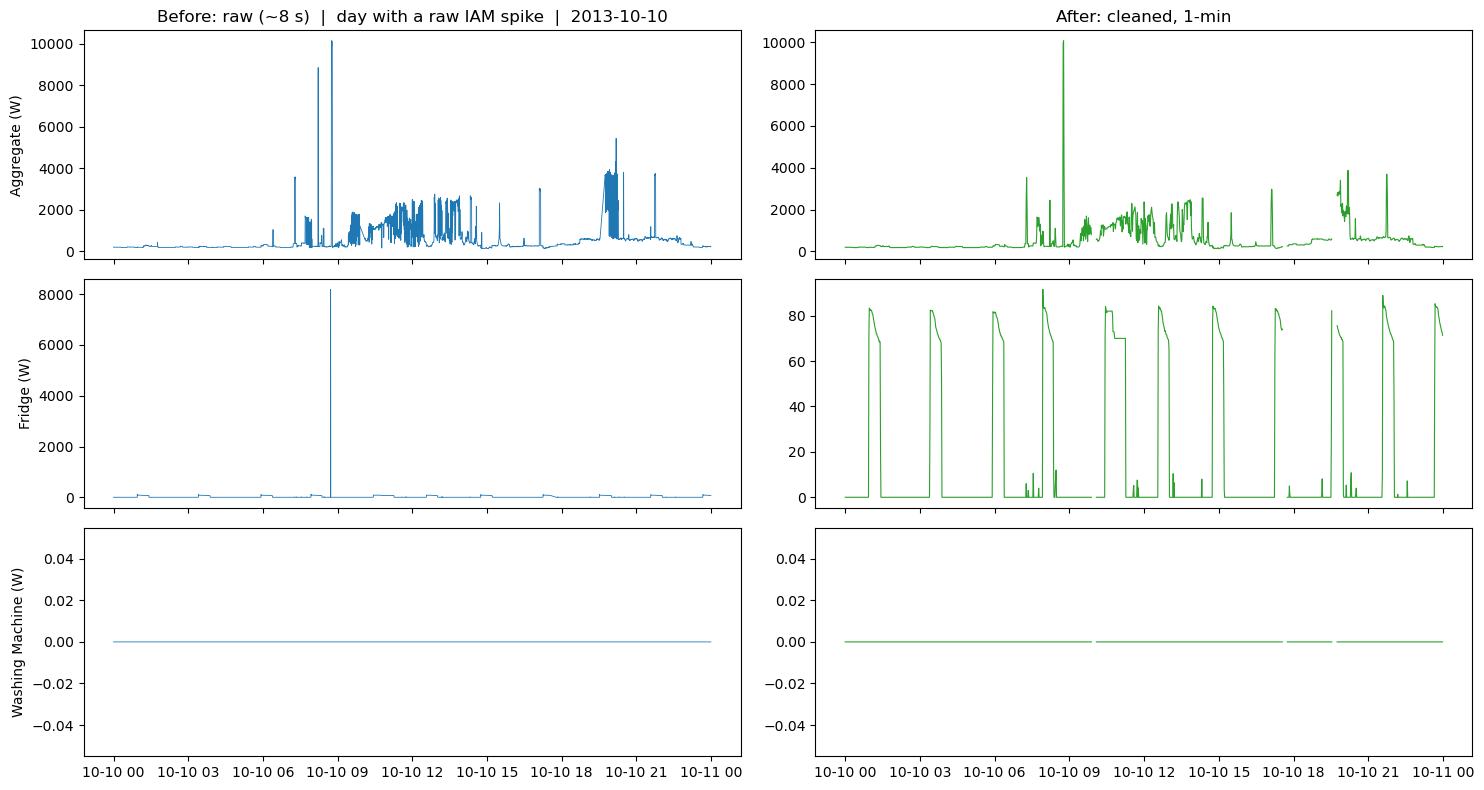

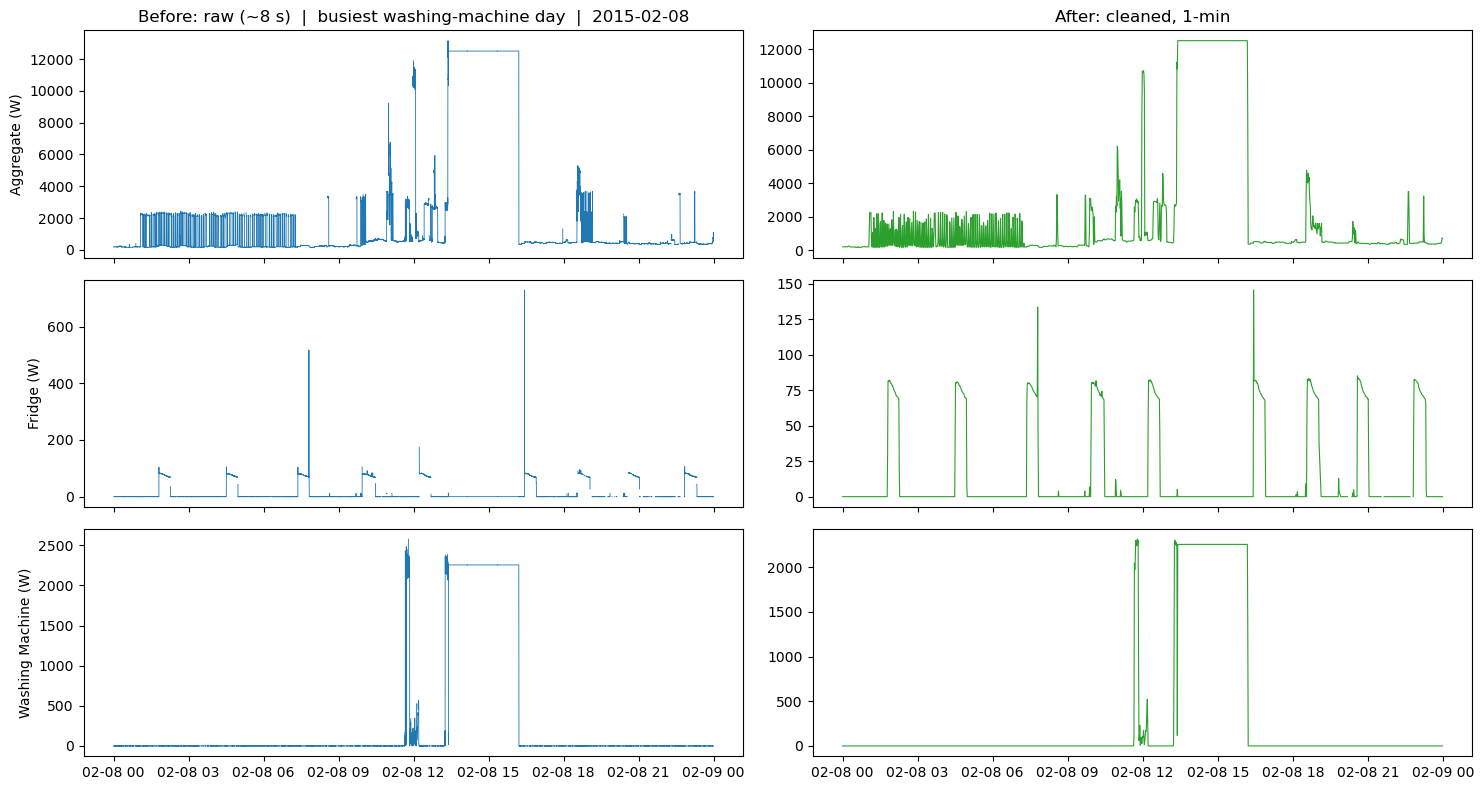

In [15]:
# Window 1 is a day that really contains a raw IAM spike, window 2 is the busiest washing-machine day,
# so the "before/after" plots show something happening in the washing-machine channel.
spike_ts = raw_ts.index[raw_ts["Appliance1"] > SPIKE_W]
spike_day = pd.Timestamp(spike_ts[0]).normalize() if len(spike_ts) else pd.Timestamp("2013-12-02")
wm_day = res_clean["Appliance5"].resample("D").sum().idxmax().normalize()
chans = ["Aggregate", "Appliance1", "Appliance5"]   # Aggregate, Fridge, Washing Machine

def before_after(day, title, fname):
    s, e = day, day + pd.Timedelta(hours=23, minutes=59, seconds=59)
    fig, axes = plt.subplots(len(chans), 2, figsize=(15, 8), sharex="col")
    for i, c in enumerate(chans):
        name = APPLIANCE_NAMES.get(c, "Aggregate")
        axes[i, 0].plot(raw_ts[c].loc[s:e], lw=0.6)
        axes[i, 0].set_ylabel(f"{name} (W)")
        axes[i, 1].plot(res_clean[c].loc[s:e], lw=0.8, color="tab:green")
    axes[0, 0].set_title(f"Before: raw (~8 s)  |  {title}  |  {day.date()}")
    axes[0, 1].set_title("After: cleaned, 1-min")
    plt.tight_layout(); savefig(fname); plt.show()

before_after(spike_day, "day with a raw IAM spike", "task1_before_after_spike_day")
before_after(wm_day, "busiest washing-machine day", "task1_before_after_wm_day")


### Before / after: full period

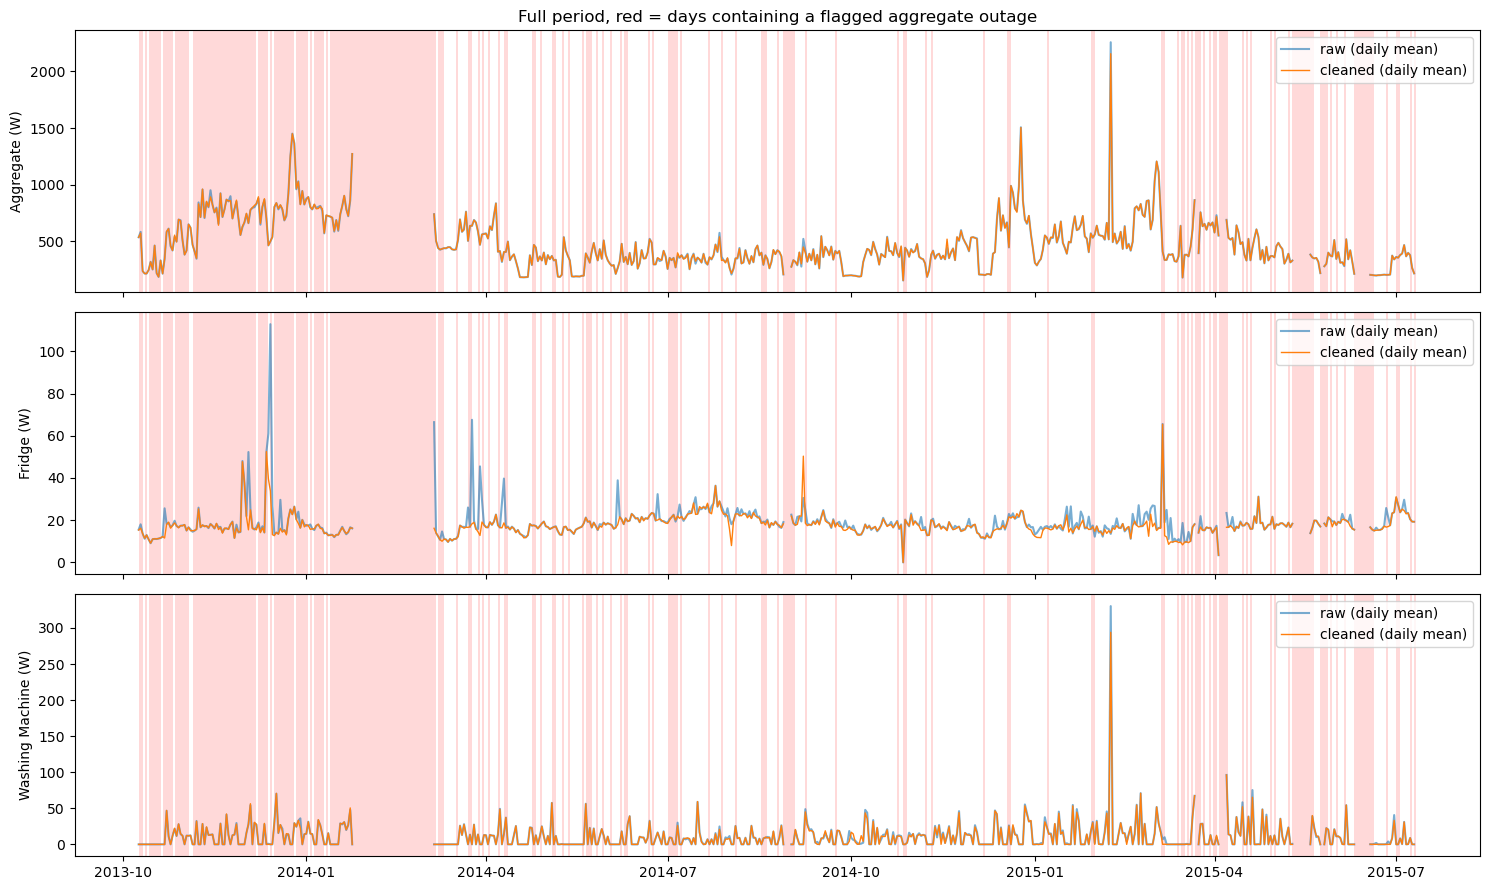

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, c in zip(axes, chans):
    name = APPLIANCE_NAMES.get(c, "Aggregate")
    ax.plot(raw_ts[c].resample("D").mean(), label="raw (daily mean)", alpha=0.6)
    ax.plot(res_clean[c].resample("D").mean(), label="cleaned (daily mean)", lw=1)
    ax.set_ylabel(f"{name} (W)"); ax.legend(loc="upper right")

o = res_clean["outage"].resample("D").max()
for ax in axes:
    for d in o[o == 1].index:
        ax.axvspan(d, d + pd.Timedelta(days=1), color="red", alpha=0.15, lw=0)
axes[0].set_title("Full period, red = days containing a flagged aggregate outage")
plt.tight_layout(); savefig("task1_before_after_full_period"); plt.show()


1. **Spike day:** the raw spikes are gone after cleaning (the 4,000 W rule removes them, 1-minute averaging alone wouldn't). 
2. **Washing-machine day:** the 1-minute line follows the raw one and keeps the heating and spin phases. 
3. **Full period:** raw and cleaned daily means agree except on spike days. Red = outage days, left empty on purpose.

In [17]:
res_clean.to_parquet(OUT_DIR / "house1_raw_cleaned_1min.parquet")
out.to_csv(OUT_DIR / "tables" / "house1_outages.csv")
chan_summary.to_csv(OUT_DIR / "tables" / "house1_channel_gap_summary.csv")
print("saved cleaned 1-minute House 1 data and tables to", OUT_DIR)


saved cleaned 1-minute House 1 data and tables to outputs


### Task 1 summary

In [18]:
from IPython.display import display
import pandas as pd

summary = pd.DataFrame({
    "Metric": [
        "Rows after joining",
        "Duplicate rows removed",
        "Unique seconds kept",
        "All-channel zero rows set to NaN",
        "Aggregate == 0 rows set to NaN",
        "Aggregate > 23,000 W set to NaN",
        "Isolated aggregate spikes set to NaN",
        "Aggregate > 10,000 W retained and flagged",
        "IAM spikes set to 0",
        "Total minutes",
        "Short aggregate gaps filled (≤5 min)",
        "Long aggregate outages (>5 min)",
        "Outage minutes",
        "Outage percentage",
        "Total outage hours",
        "Issues-flagged minutes",
        "Channel with most long-gap minutes"
    ],
    "Value": [
        f"{len(raw):,}",
        f"{clean_log['dup_rows_removed']:,}",
        f"{clean_log['unique_seconds']:,}",
        f"{clean_log['all_zero_rows']:,}",
        f"{clean_log['agg_zero']:,}",
        f"{clean_log['agg_impossible']:,}",
        f"{clean_log['agg_isolated_spike']:,}",
        f"{clean_log['agg_extreme_kept']:,} rows "
        f"({int(res_clean['agg_extreme'].sum()):,} minutes)",
        f"{clean_log['iam_spikes']:,}",
        f"{len(res_clean):,}",
        f"{int(res_clean['short_gap_filled'].sum()):,}",
        f"{len(out):,}",
        f"{int(res_clean['outage'].sum()):,}",
        f"{100 * res_clean['outage'].mean():.1f}%",
        f"{out['hours'].sum():,.0f}",
        f"{int(res_clean['issues'].sum()):,}",
        f"{chan_summary['long_gap_minutes'].idxmax()} "
        f"({chan_summary['long_gap_pct'].max():.1f}%)"
    ]
})

display(summary)

,Metric,Value
0,Rows after joining,"7,260,898"
1,Duplicate rows removed,"597,182"
2,Unique seconds kept,"6,663,716"
3,All-channel zero rows set to NaN,0
4,Aggregate == 0 rows set to NaN,8
5,"Aggregate > 23,000 W set to NaN",62
6,Isolated aggregate spikes set to NaN,8
7,"Aggregate > 10,000 W retained and flagged","16,513 rows (1,689 minutes)"
8,IAM spikes set to 0,"2,591"
9,Total minutes,"920,031"


### Task 1 limitations
- Zeroing spikes may hide real events, and Part1 appliance zeros can still mean "offline".
- The 5-minute fill limit and the aggregate ceilings are my choices, backed by the numbers above.
- The sampling interval is less regular before July 2014, so readings per minute vary.

## 2. Washing-machine EDA (official cleaned data)

### Config

In [19]:
import warnings
CLEAN_DIR = Path("DATA/CLEAN_REFIT_081116")
CACHE_DIR = OUT_DIR / "cache"; CACHE_DIR.mkdir(parents=True, exist_ok=True)
TZ = "Europe/London"

# Washing-machine channel(s) per house, taken from the README appliance list.
WM_CHANNELS = {
    1: ["Appliance5"], 2: ["Appliance2"], 3: ["Appliance6"], 4: ["Appliance4", "Appliance5"],
    5: ["Appliance3"], 6: ["Appliance2"], 7: ["Appliance5"], 8: ["Appliance4"], 9: ["Appliance3"],
    10: ["Appliance5"], 11: ["Appliance3"], 13: ["Appliance3"], 15: ["Appliance3"],
    16: ["Appliance5"], 17: ["Appliance4"], 18: ["Appliance5"], 19: ["Appliance2"],
    20: ["Appliance4"], 21: ["Appliance3"],
}
OCCUPANTS = {1: 2, 2: 4, 3: 2, 4: 2, 5: 4, 6: 2, 7: 4, 8: 2, 9: 2, 10: 4, 11: 1, 12: 3, 13: 4,
             15: 1, 16: 6, 17: 3, 18: 2, 19: 4, 20: 2, 21: 4}          # README household table
WM_END = {13: "2015-03-25"}      # README: House 13 washing machine channel "changes 25 Mar 2015"
HOUSES = sorted(WM_CHANNELS)

# --- cycle rule (explained in plain language below) ---
ACTIVE_W = 20          # a minute is "active" above this power
MERGE_GAP_MIN = 10     # pauses up to this long (fully observed) stay inside one cycle
MIN_CYCLE_MIN = 10     # a cycle lasts at least this long ...
MIN_PEAK_W = 100       # ... reaches at least this power ...
MIN_CYCLE_WH = 50      # ... and uses at least this much energy
MAX_CYCLE_MIN = 240    # longer than this is flagged as suspect
HEAT_W = 1000          # "heating" minute = 1-min power at or above this (water heater is about 2 kW)
HEAT_MIN = 5           # "heated" cycle = at least this many heating minutes (a one-minute spike is not a heating phase)

# --- data quality rules ---
STALE_MIN = 30         # aggregate identical for this many minutes in a row = stuck / forward-filled
MISSING_FLAG_MIN = 5   # same threshold as Task 1: no-data runs longer than this are reported as missing intervals
VALID_DAY_FRAC = 0.9   # a day is "usable" if at least 90% of its minutes are valid

# --- which houses get the deep dive ---
MIN_USABLE_DAYS = 180
MIN_CYCLES = 50

# --- clock handling: decided by clock_test (after the houses are loaded), not assumed ---
CLOCK = {"mode": "utc_to_london"}   # overwritten by clock_test(); the other mode is "already_local"
CLOCK_OVERRIDE = None               # set to "utc_to_london" or "already_local" to force a choice

# --- per-house quality flags (houses are flagged, not dropped) ---
FLAG_STALE_PCT = 10        # aggregate stuck on one value more than this share of minutes
FLAG_NODATA_PCT = 20       # more than this share of minutes with no reading at all
FLAG_TRUNC_SHARE = 0.25    # more than this share of cycles touch a gap or the data edge
FLAG_LONG_SHARE = 0.05     # more than this share of cycles exceed MAX_CYCLE_MIN
ISSUE_MINUTE_FRAC = 0.5    # a minute counts as Issues-flagged if more than this share of its 8 s rows are flagged
ISSUE_CYCLE_FRAC = 0.25    # a cycle is Issues-affected if more than this share of its minutes are flagged
FLAG_ISSUES_SHARE = 0.10   # more than this share of cycles overlap an Issues minute
assert CLEAN_DIR.exists(), f"{CLEAN_DIR} not found: unpack CLEAN_REFIT_081116.7z into DATA/"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.4.6


### Helpers

In [20]:
def _col_positions(path):
    """Find the columns by header name, falling back to the README column order."""
    raw_hdr = list(pd.read_csv(path, nrows=0).columns)
    low = {str(c).strip().lower(): i for i, c in enumerate(raw_hdr)}
    pos = {"Unix": low.get("unix", 1), "Aggregate": low.get("aggregate", 2)}
    for k in range(1, 10):
        pos[f"Appliance{k}"] = low.get(f"appliance{k}", 2 + k)
    pos["Issues"] = low.get("issues", 12 if len(raw_hdr) > 12 else None)
    return raw_hdr, pos


def load_house_1min(h, use_cache=True):
    """CLEAN_House{h}.csv -> 1-minute frame: agg, wm, issues, n (readings in minute), stale, valid. Index = UTC."""
    tag = f"s{STALE_MIN}_f{ISSUE_MINUTE_FRAC}_{'-'.join(c.replace('Appliance', 'A') for c in WM_CHANNELS[h])}_{WM_END.get(h, 'none')}"
    cache = CACHE_DIR / f"house{h}_wm_1min_{tag}.parquet"
    if use_cache and cache.exists():
        return pd.read_parquet(cache)
    path = CLEAN_DIR / f"CLEAN_House{h}.csv"
    raw_hdr, pos = _col_positions(path)
    chans = WM_CHANNELS[h]
    want = {"Unix": pos["Unix"], "Aggregate": pos["Aggregate"], **{c: pos[c] for c in chans}}
    if pos["Issues"] is not None:
        want["Issues"] = pos["Issues"]
    dtypes = {raw_hdr[i]: "float32" for k, i in want.items() if k != "Unix"}
    d = pd.read_csv(path, usecols=sorted(want.values()), dtype=dtypes)
    d.columns = sorted(want, key=want.get)                       # read_csv returns columns in file order
    d.index = pd.to_datetime(d.pop("Unix"), unit="s")            # UTC clock
    d = d.sort_index()

    wm = d[chans].sum(axis=1, min_count=1)
    iss = d["Issues"] if "Issues" in d else pd.Series(0.0, index=d.index)
    m = pd.DataFrame({"agg": d["Aggregate"], "wm": wm, "issues_frac": iss}).resample("1min").agg(
        {"agg": "mean", "wm": "mean", "issues_frac": "mean"})
    m["n"] = d["Aggregate"].resample("1min").count()
    m["issues_frac"] = m["issues_frac"].fillna(0).astype("float32")
    m["issues"] = (m["issues_frac"] > ISSUE_MINUTE_FRAC).astype("int8")   # majority of the minute's rows flagged
    if h in WM_END:
        m = m[m.index < pd.Timestamp(WM_END[h])]

    # forward-filled flat lines: aggregate unchanged for STALE_MIN+ minutes in a row
    same = m["agg"].diff().abs() < 1e-6
    run = m["agg"].groupby((~same).cumsum()).transform("size")
    m["stale"] = (run >= STALE_MIN) & m["agg"].notna()
    m["valid"] = (m["n"] > 0) & m["wm"].notna() & m["agg"].notna() & ~m["stale"]

    ok = np.flatnonzero(m["valid"].to_numpy())
    if len(ok) == 0:
        raise ValueError(f"House {h}: no valid minutes")
    m = m.iloc[ok[0]: ok[-1] + 1].copy()                         # study span = first to last valid minute
    m.to_parquet(cache)
    return m


def to_local_clock(idx):
    """Stored (Unix-based) index -> the wall clock used for hour-of-day. The mode is set by clock_test()."""
    if CLOCK["mode"] == "utc_to_london":
        return idx.tz_localize("UTC").tz_convert(TZ).tz_localize(None)
    return idx    # stamps already follow the UK wall clock


def add_local(m):
    """Add wall-clock UK time columns (t_local, date, hour, dow) to a 1-minute frame indexed by UTC."""
    out = m.copy()
    t = pd.Series(to_local_clock(m.index), index=m.index)
    out["t_local"] = t
    out["date"] = t.dt.normalize()
    out["hour"] = t.dt.hour
    out["dow"] = t.dt.dayofweek
    return out


def day_table(m):
    """Per local day: rows, valid minutes, valid fraction, issues minutes, usable flag."""
    t = add_local(m)
    g = t.groupby("date")
    d = pd.DataFrame({"rows": g.size(), "valid": g["valid"].sum(), "issues": g["issues"].sum()})
    d["frac"] = (d["valid"] / 1440).clip(upper=1.0)
    d["usable"] = d["frac"] >= VALID_DAY_FRAC
    return d


def to_md(df, nd=1):
    """Small markdown-table helper (no extra dependency)."""
    def f(v):
        if isinstance(v, float):
            return "" if np.isnan(v) else f"{v:.{nd}f}"
        return str(v)
    head = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    for i, r in df.iterrows():
        lines.append("| " + " | ".join([str(i)] + [f(v) for v in r]) + " |")
    return "\n".join(lines)


### Load all houses
19 houses have a washing-machine channel. The first run reads the CSVs and caches a parquet per house.

In [21]:
M = {}
for h in HOUSES:
    try:
        M[h] = load_house_1min(h)
        print(f"House {h:>2}: {len(M[h]):>8,} min | {M[h].index[0]:%Y-%m-%d} -> {M[h].index[-1]:%Y-%m-%d}")
    except FileNotFoundError:
        print(f"House {h:>2}: file not found, skipped")
print(f"\n{len(M)} houses loaded")


House  1:  920,091 min | 2013-10-09 -> 2015-07-10
House  2:  889,078 min | 2013-09-17 -> 2015-05-28
House  3:  885,095 min | 2013-09-25 -> 2015-06-02
House  4:  912,939 min | 2013-10-11 -> 2015-07-07
House  5:  933,593 min | 2013-09-26 -> 2015-07-06
House  6:  831,480 min | 2013-11-28 -> 2015-06-28
House  7:  882,970 min | 2013-11-01 -> 2015-07-08
House  8:  799,284 min | 2013-11-01 -> 2015-05-10
House  9:  818,007 min | 2013-12-17 -> 2015-07-08
House 10:  845,105 min | 2013-11-20 -> 2015-06-30
House 11:  564,697 min | 2014-06-03 -> 2015-06-30
House 13:  620,734 min | 2014-01-17 -> 2015-03-24
House 15:  817,007 min | 2013-12-17 -> 2015-07-08
House 16:  782,833 min | 2014-01-10 -> 2015-07-08
House 17:  676,710 min | 2014-03-06 -> 2015-06-19
House 18:  635,328 min | 2014-03-07 -> 2015-05-22
House 19:  677,470 min | 2014-03-06 -> 2015-06-20
House 20:  662,864 min | 2014-03-20 -> 2015-06-23
House 21:  700,748 min | 2014-03-07 -> 2015-07-07

19 houses loaded


### Clock check 1: UK clock changes
- Compared daily profiles 14 days before and after UK clock changes.
- Spring 2014 suggested UTC; autumn 2014 suggested local time. March 2015 had insufficient data.
- Results remain inconclusive, and Clock checks 1 and 2 disagree for autumn 2014.
- Repeated hour-of-day and peak-window analyses using November–March data as a robustness check.

Shift needed to line up the profiles across a clock change (+1 h = true UTC, 0 h = already local):
                   houses  median_shift_h  share_of_houses_utc
event                                                         
2014-03-30 spring      14             1.0                  1.0
2014-10-26 autumn      16             0.0                  0.0

Median shift over 30 house-events: +0.0 h  ->  mode 'already_local'


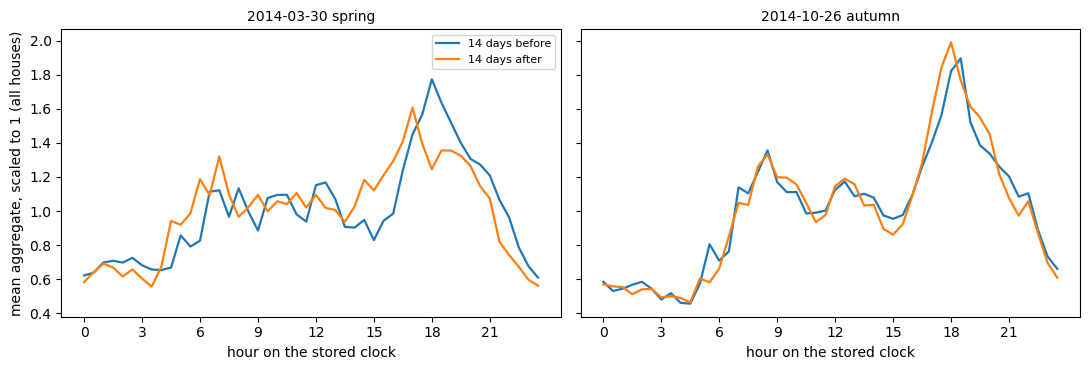

Clock mode used for all hour-of-day results: already_local


In [22]:
DST_EVENTS = [("2014-03-30", "spring"), ("2014-10-26", "autumn"), ("2015-03-29", "spring")]   # last Sundays of March / October, 01:00 UTC
SLOT_MIN, WIN_DAYS, MIN_COVER = 30, 14, 0.6

def _profile(m, start, end):
    """Mean aggregate per half-hour slot of the stored clock, scaled to mean 1. None if too little valid data."""
    v = m.loc[start:end]
    v = v.loc[v["valid"], "agg"]
    if len(v) < MIN_COVER * (end - start).total_seconds() / 60:
        return None
    slot = (v.index.hour * 60 + v.index.minute) // SLOT_MIN
    p = v.groupby(slot).mean().reindex(range(1440 // SLOT_MIN))
    return None if p.isna().any() else (p / p.mean()).to_numpy()

def _best_shift(before, after, max_slots=4):
    """Slots k such that np.roll(after, k) matches `before` best."""
    sc = {k: np.corrcoef(before, np.roll(after, k))[0, 1] for k in range(-max_slots, max_slots + 1)}
    return max(sc, key=sc.get)

rows, pooled = [], {}
for date, kind in DST_EVENTS:
    d = pd.Timestamp(date)
    b_rng = (d - pd.Timedelta(days=WIN_DAYS), d - pd.Timedelta(minutes=1))
    a_rng = (d + pd.Timedelta(days=1), d + pd.Timedelta(days=WIN_DAYS + 1) - pd.Timedelta(minutes=1))
    pb, pa = [], []
    for h, m in M.items():
        b, a = _profile(m, *b_rng), _profile(m, *a_rng)
        if b is None or a is None:
            continue
        k = _best_shift(b, a)
        rows.append({"event": f"{date} {kind}", "house": h, "shift_h": (k if kind == "spring" else -k) * SLOT_MIN / 60})
        pb.append(b); pa.append(a)
    if pb:
        pooled[f"{date} {kind}"] = (np.mean(pb, axis=0), np.mean(pa, axis=0))

ct = pd.DataFrame(rows)
if ct.empty:
    print("WARNING: no house has enough data around a clock change; keeping the default mode:", CLOCK["mode"])
else:
    tab = ct.groupby("event")["shift_h"].agg(houses="size", median_shift_h="median", share_of_houses_utc=lambda s: (s >= 0.5).mean())
    print("Shift needed to line up the profiles across a clock change (+1 h = true UTC, 0 h = already local):")
    print(tab.round(2).to_string())
    overall = float(ct["shift_h"].median())
    decided = "utc_to_london" if overall >= 0.5 else "already_local"
    CLOCK["mode"] = CLOCK_OVERRIDE or decided
    print(f"\nMedian shift over {len(ct)} house-events: {overall:+.1f} h  ->  mode '{decided}'"
          + (f", overridden to '{CLOCK_OVERRIDE}'" if CLOCK_OVERRIDE else ""))

    fig, axes = plt.subplots(1, len(pooled), figsize=(5.5 * len(pooled), 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    x = np.arange(1440 // SLOT_MIN) * SLOT_MIN / 60
    for ax, (ev_name, (pb_, pa_)) in zip(axes, pooled.items()):
        ax.plot(x, pb_, color="tab:blue", lw=1.6, label="14 days before")
        ax.plot(x, pa_, color="tab:orange", lw=1.6, label="14 days after")
        ax.set_title(ev_name, fontsize=10); ax.set_xlabel("hour on the stored clock")
        ax.set_xticks(range(0, 24, 3))
    axes[0].set_ylabel("mean aggregate, scaled to 1 (all houses)"); axes[0].legend(fontsize=8)
    plt.tight_layout(); savefig("task2_clock_test"); plt.show()
print("Clock mode used for all hour-of-day results:", CLOCK["mode"])

### Clock check 2: Cleaned vs raw (House 1)
- Cleaned timestamps match raw in Nov–Mar and from Oct 2014, but are 60 minutes earlier in Oct 2013 and Apr–Sep 2014.
- Clock inconsistencies may shift hour-of-day results by 1–2 hours in summer 2014.
- Timestamps were used without conversion; Nov–Mar results provide a more reliable robustness check.

In [23]:
if "res_clean" in globals() and 1 in M:
    a, b = res_clean["Aggregate"], M[1]["agg"]
    print(f"Task 1 (raw):     {len(a):,} min, {a.index[0]} -> {a.index[-1]}")
    print(f"Task 2 (cleaned): {len(b):,} min, {b.index[0]} -> {b.index[-1]}   (difference {len(b) - len(a):+,} min)")

    def _err(x, y, k):
        """median |raw(t) - cleaned(t - k min)| on minutes where both exist"""
        ys = y.copy(); ys.index = ys.index + pd.Timedelta(minutes=k)
        j = pd.concat([x, ys], axis=1, join="inner").dropna()
        return (j.iloc[:, 0] - j.iloc[:, 1]).abs().median() if len(j) > 1000 else np.nan

    rows_t = []
    for per, x in a.groupby(a.index.to_period("M")):
        e0, e60 = _err(x, b, 0), _err(x, b, 60)
        rows_t.append({"month": str(per), "err_shift0_W": round(e0, 1), "err_shift60_W": round(e60, 1),
                       "best_shift_min": (np.nan if np.isnan(e0) or np.isnan(e60) else (0 if e0 <= e60 else 60))})
    tl = pd.DataFrame(rows_t).set_index("month")
    print(tl.to_string())
    print("Months where cleaned = raw minus 60 min:", tl.index[tl["best_shift_min"] == 60].tolist())
else:
    print("Run Task 1 in the same kernel (needs `res_clean`) for this check.")

Task 1 (raw):     920,031 min, 2013-10-09 14:06:00 -> 2015-07-10 11:56:00
Task 2 (cleaned): 920,091 min, 2013-10-09 13:06:00 -> 2015-07-10 11:56:00   (difference +60 min)
         err_shift0_W  err_shift60_W  best_shift_min
month                                               
2013-10          19.4            0.1            60.0
2013-11           0.0           90.4             0.0
2013-12           0.0          122.0             0.0
2014-01           0.2          130.4             0.0
2014-02           NaN            NaN             NaN
2014-03           0.0           39.9             0.0
2014-04          50.5            0.0            60.0
2014-05          44.1            0.0            60.0
2014-06          57.6            0.0            60.0
2014-07          69.0            1.6            60.0
2014-08          55.4            1.7            60.0
2014-09          45.2            0.9            60.0
2014-10           0.0           50.3             0.0
2014-11           0.0           59

### Threshold check
There is no clean gap in the power distribution, so the 20 W threshold rests on the sensitivity table below.

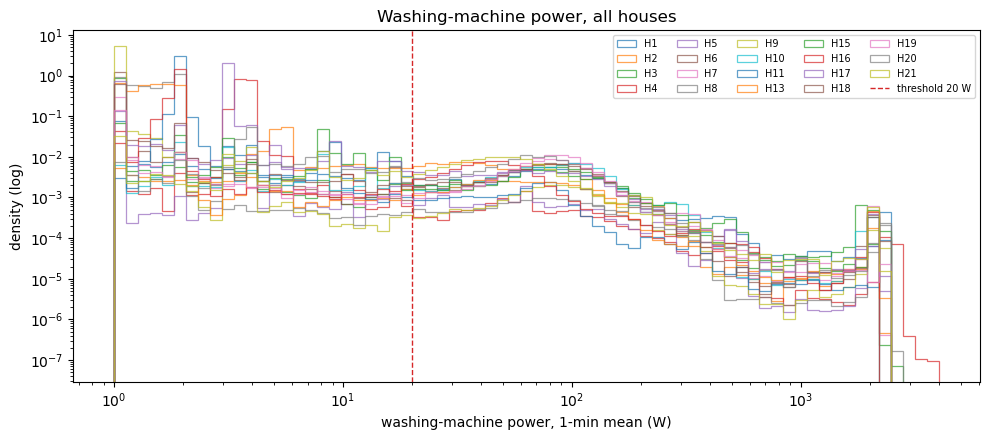

Pooled valid minutes: exactly 0 W 89.1% | 0 < P <= 20 W 6.9% | above 20 W 4.0%


In [24]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.logspace(0, np.log10(4000), 70)
for h, m in M.items():
    v = m.loc[m["valid"], "wm"]
    v = v[v >= 1]
    if len(v) > 100:
        ax.hist(v, bins=bins, histtype="step", density=True, lw=0.9, alpha=0.7, label=f"H{h}")
ax.axvline(ACTIVE_W, color="tab:red", ls="--", lw=1, label=f"threshold {ACTIVE_W} W")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("washing-machine power, 1-min mean (W)"); ax.set_ylabel("density (log)")
ax.set_title("Washing-machine power, all houses")
ax.legend(ncol=5, fontsize=7)
plt.tight_layout(); savefig("task2_wm_power_distribution"); plt.show()

allv = pd.concat([m.loc[m["valid"], "wm"] for m in M.values()])
print(f"Pooled valid minutes: exactly 0 W {(allv == 0).mean():.1%} | 0 < P <= {ACTIVE_W} W {((allv > 0) & (allv <= ACTIVE_W)).mean():.1%} | above {ACTIVE_W} W {(allv > ACTIVE_W).mean():.1%}")


### Cycle rule
- Active minute: washing-machine power >20 W.
- Merge active stretches separated by pauses of up to 10 minutes.
- Count as a cycle if duration ≥10 min, peak power ≥100 W, and energy ≥50 Wh.
- Flag cycles >240 min or touching data gaps; exclude them from duration and energy statistics.
- Classify a cycle as heated if power exceeds 1,000 W for at least 5 minutes.

In [25]:
def detect_cycles(m, active_w=ACTIVE_W, merge_gap=MERGE_GAP_MIN, min_dur=MIN_CYCLE_MIN,
                  min_peak=MIN_PEAK_W, min_wh=MIN_CYCLE_WH, max_dur=MAX_CYCLE_MIN):
    """Return every candidate event with flags. `passes` = counts as a cycle, `usable` = also clean enough for statistics."""
    cols_out = ["start", "end", "start_i", "end_i", "dur_min", "energy_wh", "peak_w", "mean_w",
                "heat_min", "issues_any", "truncated", "issues_frac", "passes", "too_long", "usable", "energy_kwh", "heated"]
    p = np.nan_to_num(m["wm"].to_numpy("float64"), nan=0.0)
    ok = m["valid"].to_numpy(bool)
    iss = m["issues"].to_numpy()
    n = len(p)
    act = (p > active_w) & ok
    edges = np.diff(np.r_[0, act.astype(np.int8), 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)     # active runs are [start, end)
    if len(starts) == 0:
        return pd.DataFrame(columns=cols_out)

    bad = np.r_[0, np.cumsum(~ok)]                       # bad[i] = number of invalid minutes before index i
    gap_len = starts[1:] - ends[:-1]
    gap_bad = bad[starts[1:]] - bad[ends[:-1]]
    merge = (gap_len <= merge_gap) & (gap_bad == 0)     # bridge only short, fully observed pauses
    s_idx = starts[np.r_[True, ~merge]]
    e_idx = ends[np.r_[~merge, True]]

    cs = np.r_[0.0, np.cumsum(p)]
    rows = []
    for s, e in zip(s_idx, e_idx):
        seg = p[s:e]
        dur = e - s
        wh = (cs[e] - cs[s]) / 60.0
        lo, hi = max(s - 1, 0), min(e + 1, n)
        rows.append((m.index[s], m.index[e - 1], s, e, dur, wh, seg.max(), wh * 60.0 / dur,
                     int((seg >= HEAT_W).sum()), bool(iss[s:e].any()),
                     bool((bad[hi] - bad[lo]) > 0 or s == 0 or e == n), float(iss[s:e].mean())))
    ev = pd.DataFrame(rows, columns=cols_out[:12])
    ev["passes"] = (ev["dur_min"] >= min_dur) & (ev["peak_w"] >= min_peak) & (ev["energy_wh"] >= min_wh)
    ev["too_long"] = ev["dur_min"] > max_dur
    ev["usable"] = ev["passes"] & ~ev["too_long"] & ~ev["truncated"]
    ev["energy_kwh"] = ev["energy_wh"] / 1000.0
    ev["heated"] = ev["heat_min"] >= HEAT_MIN
    return ev


EV = {}
for h, m in M.items():
    ev = detect_cycles(m)
    ev.insert(0, "house", h)
    EV[h] = ev
print("candidate events / cycles / usable cycles per house:")
print(pd.DataFrame({h: [len(e), int(e["passes"].sum()), int(e["usable"].sum())] for h, e in EV.items()},
                   index=["events", "cycles", "usable"]).T.to_string())


candidate events / cycles / usable cycles per house:
    events  cycles  usable
1      471     396     376
2      391     336     303
3      804     580     499
4      493     256     253
5     1256     747     655
6      336     124     106
7      985     865     826
8      456     366     355
9      281     247     238
10     923     600     559
11     173      76      71
13     663     419     277
15     410     261     247
16     391     317     300
17     506     284     275
18     177     137     128
19     342     258     244
20     256     194     189
21     339     234     222


### Sensitivity of the rule
Changing the threshold (10-50 W) or the merge gap (5-20 min) moves the total cycle count by under 5%.

In [26]:
rows = []
for aw in [10, 20, 50]:
    for mg in [5, 10, 20]:
        tot = sum(int(detect_cycles(m, active_w=aw, merge_gap=mg)["passes"].sum()) for m in M.values())
        rows.append({"active_W": aw, "merge_gap_min": mg, "cycles": tot})
sens = pd.DataFrame(rows).pivot(index="active_W", columns="merge_gap_min", values="cycles")
base = sens.loc[ACTIVE_W, MERGE_GAP_MIN]
print("Total detected cycles (all houses):"); print(sens.to_string())
print("\nChange vs baseline (%):"); print(((sens / base - 1) * 100).round(1).to_string())


Total detected cycles (all houses):
merge_gap_min    5     10    20
active_W                       
10             6844  6680  6434
20             6853  6697  6445
50             7015  6759  6465

Change vs baseline (%):
merge_gap_min   5    10   20
active_W                    
10             2.2 -0.3 -3.9
20             2.3  0.0 -3.8
50             4.7  0.9 -3.5


### Availability and quality per house
`no_data_pct` = minutes without a reading, `stale_pct` = aggregate stuck for 30+ min, `issues_pct` = minutes flagged by the readme `Issues` column, `wm_off_pct` = minutes at or below 20 W, `flags` = houses with a data problem.

In [27]:
def house_row(h, m, ev):
    nodata = ~(m["n"] > 0)
    rl = nodata.groupby((nodata != nodata.shift()).cumsum()).transform("sum")
    long_gap = nodata & (rl > MISSING_FLAG_MIN)
    starts = long_gap & ~long_gap.shift(fill_value=False)
    dt = day_table(m)
    v = m[m["valid"]]
    local = add_local(m)
    n_cyc = int(ev["passes"].sum())
    row = {
        "house": h, "channel": "+".join(c.replace("Appliance", "A") for c in WM_CHANNELS[h]), "occupants": OCCUPANTS[h],
        "first_day": local["date"].iloc[0].date(), "last_day": local["date"].iloc[-1].date(),
        "span_days": round((m.index[-1] - m.index[0]).total_seconds() / 86400),
        "usable_days": int(dt["usable"].sum()),
        "no_data_pct": round(100 * nodata.mean(), 1), "gaps_gt5": int(starts.sum()),
        "gap_hours": round(float(long_gap.sum()) / 60, 0),
        "stale_pct": round(100 * m["stale"].mean(), 1),
        "issues_pct": round(100 * v["issues"].mean(), 1),
        "wm_zero_pct": round(100 * (v["wm"] == 0).mean(), 1),
        "wm_off_pct": round(100 * (v["wm"] <= ACTIVE_W).mean(), 1),
        "events": len(ev), "cycles": n_cyc, "usable": int(ev["usable"].sum()),
        "truncated": int((ev["passes"] & ev["truncated"]).sum()), "too_long": int((ev["passes"] & ev["too_long"]).sum()),
        "issues_cycles": int((ev["passes"] & (ev["issues_frac"] > ISSUE_CYCLE_FRAC)).sum()),
        "cycles_per_week": round(n_cyc / (len(v) / 10080), 1) if len(v) else np.nan,
    }
    fl = []
    if row["stale_pct"] > FLAG_STALE_PCT: fl.append("stale")
    if row["no_data_pct"] > FLAG_NODATA_PCT: fl.append("gappy")
    if n_cyc and row["truncated"] / n_cyc > FLAG_TRUNC_SHARE: fl.append("truncated")
    if n_cyc and row["too_long"] / n_cyc > FLAG_LONG_SHARE: fl.append("long")
    if n_cyc and row["issues_cycles"] / n_cyc > FLAG_ISSUES_SHARE: fl.append("issues")
    row["flags"] = ",".join(fl) if fl else "-"
    return row

avail = pd.DataFrame([house_row(h, M[h], EV[h]) for h in M]).set_index("house")
print(avail.to_string())

      channel  occupants   first_day    last_day  span_days  usable_days  no_data_pct  gaps_gt5  gap_hours  stale_pct  issues_pct  wm_zero_pct  wm_off_pct  events  cycles  usable  truncated  too_long  issues_cycles  cycles_per_week            flags
house                                                                                                                                                                                                                                                   
1          A5          2  2013-10-09  2015-07-10        639          548         12.6       406     1923.0        0.1         0.6         97.6        98.1     471     396     376         18         2             25              5.0                -
2          A2          4  2013-09-17  2015-05-28        617          441         24.6       463     3639.0        0.6         0.1         94.3        95.3     391     336     303         32         1              1              5.1            gappy
3   

In [28]:
def _rng(col, f="{:.1f}"):
    return f"{f.format(avail[col].min())} (H{avail[col].idxmin()}) to {f.format(avail[col].max())} (H{avail[col].idxmax()})"

print("Range over houses (min to max):")
for label, col, f in [("span, days", "span_days", "{:.0f}"), ("usable days", "usable_days", "{:.0f}"), ("no-data %", "no_data_pct", "{:.1f}"),
                      ("stale %", "stale_pct", "{:.1f}"), ("washing machine off/standby %", "wm_off_pct", "{:.1f}"),
                      ("Issues %", "issues_pct", "{:.1f}"), ("cycles", "cycles", "{:.0f}"), ("cycles per week", "cycles_per_week", "{:.1f}")]:
    print(f"  {label:<30} {_rng(col, f)}")
fl = avail[avail["flags"] != "-"]
print(f"Flagged houses ({len(fl)} of {len(avail)}):")
for h, r in fl.iterrows():
    print(f"  H{h}: {r['flags']} | no data {r['no_data_pct']}%, stale {r['stale_pct']}%, truncated {r['truncated']}/{r['cycles']}, too long {r['too_long']}/{r['cycles']}, Issues-affected {r['issues_cycles']}/{r['cycles']}")

Range over houses (min to max):
  span, days                     392 (H11) to 648 (H5)
  usable days                    288 (H13) to 573 (H5)
  no-data %                      5.9 (H18) to 24.6 (H2)
  stale %                        0.1 (H1) to 13.3 (H3)
  washing machine off/standby %  90.4 (H10) to 98.8 (H18)
  Issues %                       0.1 (H2) to 5.0 (H5)
  cycles                         76 (H11) to 865 (H7)
  cycles per week                1.5 (H11) to 11.3 (H7)
Flagged houses (6 of 19):
  H2: gappy | no data 24.6%, stale 0.6%, truncated 32/336, too long 1/336, Issues-affected 1/336
  H3: stale | no data 11.4%, stale 13.3%, truncated 81/580, too long 0/580, Issues-affected 44/580
  H5: long,issues | no data 9.3%, stale 0.3%, truncated 60/747, too long 38/747, Issues-affected 136/747
  H11: issues | no data 11.0%, stale 0.7%, truncated 5/76, too long 0/76, Issues-affected 19/76
  H13: gappy,truncated | no data 21.7%, stale 2.6%, truncated 142/419, too long 0/419, Issues-affected

### Houses used
All 19 houses meet the minimum (180 usable days, 50 usable cycles). Weaker ones are flagged, not dropped. Periods are in the table below.

In [29]:
selected = avail.index[(avail["usable_days"] >= MIN_USABLE_DAYS) & (avail["usable"] >= MIN_CYCLES)].tolist()
if len(selected) < 4:
    print("WARNING: fewer than 4 houses pass the rule, falling back to the 4 with most usable cycles")
    selected = avail.sort_values("usable", ascending=False).index[:4].tolist()
excluded = [h for h in avail.index if h not in selected]
print(f"Houses used ({len(selected)}): {selected}")
print(f"Loaded but below the minimum-data gate: {excluded if excluded else 'none'}")
print("\nHomes and periods used:")
used = avail.loc[selected, ["channel", "occupants", "first_day", "last_day", "usable_days", "usable", "flags"]].rename(columns={"usable": "usable_cycles"})
print(used.to_string())
print("\nMarkdown for RESULTS.md:\n")
print(to_md(used))
(OUT_DIR / "tables").mkdir(exist_ok=True)
avail.to_csv(OUT_DIR / "tables" / "task2_availability.csv")
sens.to_csv(OUT_DIR / "tables" / "task2_rule_sensitivity.csv")

Houses used (19): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16, 17, 18, 19, 20, 21]
Loaded but below the minimum-data gate: none

Homes and periods used:
      channel  occupants   first_day    last_day  usable_days  usable_cycles            flags
house                                                                                        
1          A5          2  2013-10-09  2015-07-10          548            376                -
2          A2          4  2013-09-17  2015-05-28          441            303            gappy
3          A6          2  2013-09-25  2015-06-02          401            499            stale
4       A4+A5          2  2013-10-11  2015-07-07          510            253                -
5          A3          4  2013-09-26  2015-07-06          573            655      long,issues
6          A2          2  2013-11-28  2015-06-28          468            106                -
7          A5          4  2013-11-01  2015-07-08          522            826                

### Cycle table (UK local times)

In [30]:
# One row per detected cycle, with UK wall-clock times (clock mode chosen by clock_test)
DAYS = {h: day_table(M[h]) for h in M}
CYC = pd.concat([EV[h] for h in M if len(EV[h])], ignore_index=True)
CYC = CYC[CYC["passes"]].copy()
for c in ["start", "end"]:
    CYC[c + "_local"] = to_local_clock(pd.DatetimeIndex(CYC[c]))     # follows CLOCK["mode"] chosen by clock_test
CYC["date"] = CYC["start_local"].dt.normalize()
CYC["hour"] = CYC["start_local"].dt.hour
CYC["dow"] = CYC["start_local"].dt.dayofweek
ok_days = {(h, d) for h, dt in DAYS.items() for d in dt.index[dt["usable"]]}
CYC["day_ok"] = [(h, d) in ok_days for h, d in zip(CYC["house"], CYC["date"])]

# cycles used for statistics: clean (not truncated / too long), in the deep-dive houses
CS = CYC[CYC["usable"] & CYC["house"].isin(selected)].copy()
# cycles used for timing patterns: additionally only on usable days, so every hour/weekday has comparable exposure
CT = CS[CS["day_ok"]].copy()
print(f"Detected cycles (all houses): {len(CYC):,} | usable in deep-dive houses: {len(CS):,} | on usable days (timing): {len(CT):,}")
CYC.to_csv(OUT_DIR / "tables" / "task2_all_cycles.csv", index=False)


Detected cycles (all houses): 6,697 | usable in deep-dive houses: 6,123 | on usable days (timing): 5,902


### Effect of the `Issues` flag
Dropping cycles with many flagged minutes changes a house's median cycle energy by at most 1.7%, so I keep them.

In [31]:
aff = CS["issues_frac"] > ISSUE_CYCLE_FRAC
q = CS["issues_frac"].quantile([.1, .25, .5, .75, .9]).round(2)
print("Flagged share of a cycle's minutes, quantiles:", q.to_dict())
print(f"Cycles with at least one flagged minute: {CS['issues_any'].mean():.1%} | Issues-affected (over {ISSUE_CYCLE_FRAC:.0%}): {aff.mean():.1%}")
rho = CS[["energy_kwh", "issues_frac"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation between cycle energy and flagged share: {rho:.2f}")

def edge_share(h):
    """Share of flagged cycle minutes that fall in the first or last 3 minutes of a cycle (sensor-sync zone)."""
    c = CS[CS["house"] == h]; arr = M[h]["issues"].to_numpy(); tot = edge = 0
    for s, e in zip(c["start_i"].astype(int), c["end_i"].astype(int)):
        f = arr[s:e]; tot += f.sum()
        edge += (f[:3].sum() + f[-3:].sum()) if e - s > 6 else f.sum()
    return edge / tot if tot else np.nan

g = CS.groupby("house")
rob = pd.DataFrame({
    "cycles": g.size(),
    "pct_any_flag": (100 * g["issues_any"].mean()).round(1),
    "pct_affected": (100 * aff.groupby(CS["house"]).mean()).round(1),
    "median_flag_share": g["issues_frac"].median().round(2),
    "flag_edge_share": [round(edge_share(h), 2) for h in g.size().index],
    "median_kwh_all": g["energy_kwh"].median().round(3),
    "median_kwh_unaffected": CS[~aff].groupby("house")["energy_kwh"].median().round(3),
    "n_unaffected": CS[~aff].groupby("house").size(),
    "median_min_all": g["dur_min"].median(),
    "median_min_unaffected": CS[~aff].groupby("house")["dur_min"].median(),
})
rob["n_unaffected"] = rob["n_unaffected"].fillna(0).astype(int)
rob["energy_change_pct"] = (100 * (rob["median_kwh_unaffected"] / rob["median_kwh_all"] - 1)).round(1)
print(rob.to_string())
ch = rob["energy_change_pct"].abs().dropna()
if len(ch):
    print(f"\nLargest change in a house's median cycle energy when affected cycles are excluded: {ch.max():.1f}% (H{ch.idxmax()}).")
if 1 in rob.index:
    r1 = rob.loc[1]
    print(f"House 1: affected {r1['pct_affected']}% | flagged minutes at cycle edges {r1['flag_edge_share']} | median energy {r1['median_kwh_all']} -> {r1['median_kwh_unaffected']} kWh ({r1['n_unaffected']} cycles left)")
rob.to_csv(OUT_DIR / "tables" / "task2_issues_robustness.csv")

Flagged share of a cycle's minutes, quantiles: {0.1: 0.0, 0.25: 0.0, 0.5: 0.0, 0.75: 0.02, 0.9: 0.15}
Cycles with at least one flagged minute: 36.6% | Issues-affected (over 25%): 5.7%
Spearman correlation between cycle energy and flagged share: -0.09
       cycles  pct_any_flag  pct_affected  median_flag_share  flag_edge_share  median_kwh_all  median_kwh_unaffected  n_unaffected  median_min_all  median_min_unaffected  energy_change_pct
house                                                                                                                                                                                       
1         376          30.3           5.3               0.00             0.19           0.315                  0.315           356            33.0                   33.0                0.0
2         303          18.2           0.3               0.00             0.04           0.627                  0.630           302            97.0                   97.0             

### Usage by hour of day and day of week

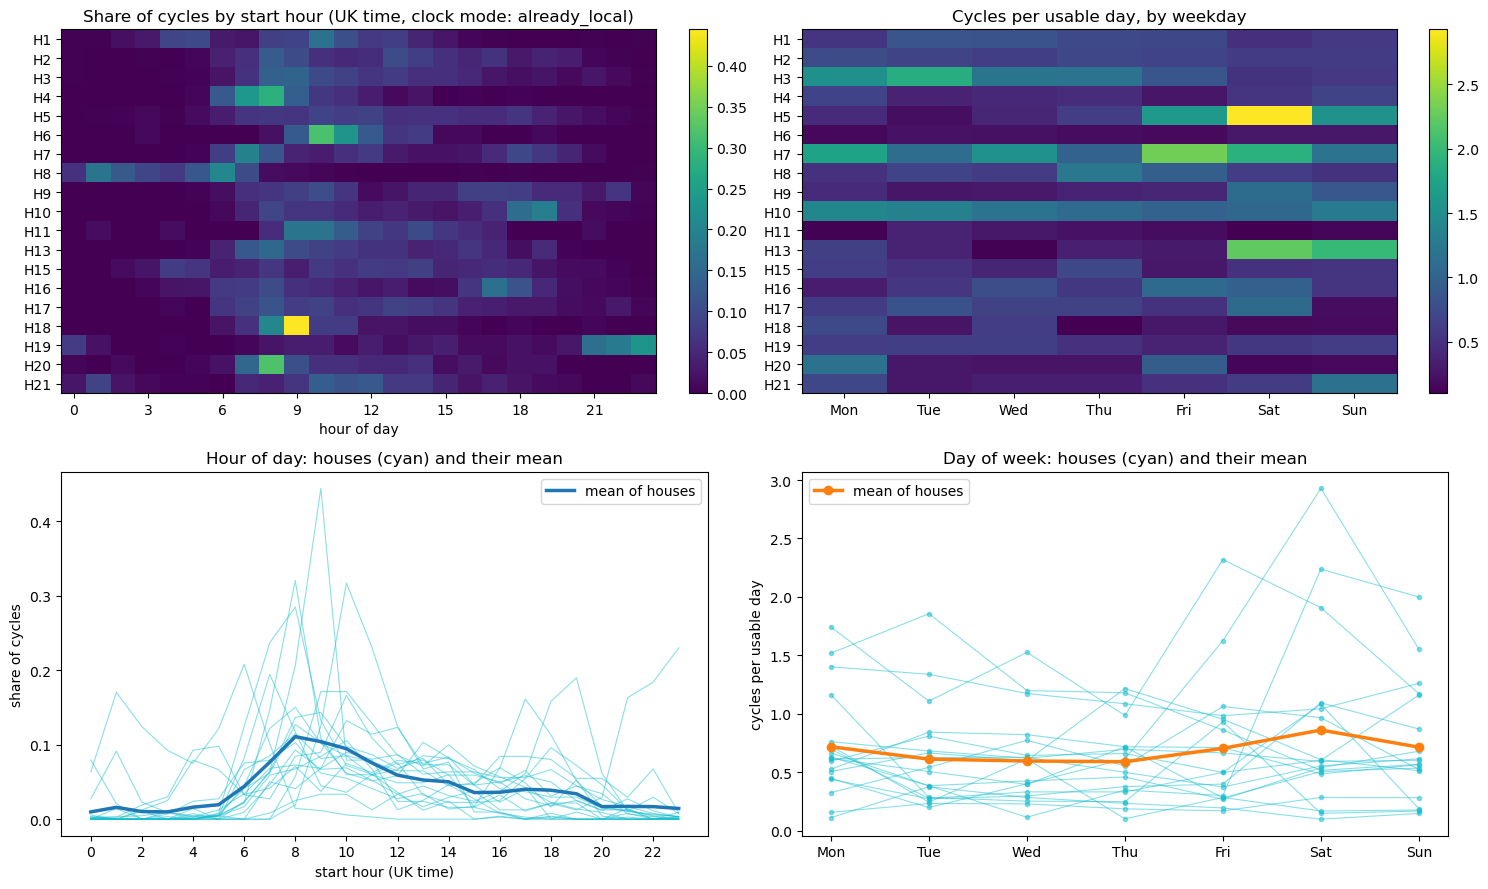

Busiest start hour (mean over houses): 08:00 (11.1% of cycles)
Share of cycles by block: {'00-06': '8%', '06-12': '51%', '12-18': '27%', '18-24': '14%'}
Cycles per day, weekday vs weekend (mean over houses): 0.65 vs 0.79; weekend busier in 10 of 19 houses
Busiest weekday (mean over houses): Sat

Reading:
- Busiest block 06-12 h (51% of cycles), peak start hour 08:00, 8% start 00:00-06:00.
- Houses with over 25% of cycles in one start hour: H4 (hour 08, 29%), H6 (hour 10, 32%), H18 (hour 09, 44%), H20 (hour 08, 32%)
- Houses with over 25% of cycles between 22:00 and 06:00: H8 (65%), H19 (52%)
- Cycles per day, weekday vs weekend: 0.65 vs 0.79; weekend higher in 10 of 19 houses.


In [32]:
hour_share = (pd.crosstab(CT["house"], CT["hour"], normalize="index")
              .reindex(index=selected, columns=range(24), fill_value=0))
dow_rate = pd.DataFrame(index=selected, columns=range(7), dtype=float)
for h in selected:
    d = DAYS[h][DAYS[h]["usable"]]
    expo = d.groupby(d.index.dayofweek).size().reindex(range(7))
    cnt = CT[CT["house"] == h].groupby("dow").size().reindex(range(7), fill_value=0)
    dow_rate.loc[h] = cnt / expo
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
im = axes[0, 0].imshow(hour_share.values, aspect="auto", cmap="viridis")
axes[0, 0].set_yticks(range(len(selected))); axes[0, 0].set_yticklabels([f"H{h}" for h in selected])
axes[0, 0].set_xticks(range(0, 24, 3)); axes[0, 0].set_title(f"Share of cycles by start hour (UK time, clock mode: {CLOCK['mode']})")
axes[0, 0].set_xlabel("hour of day"); plt.colorbar(im, ax=axes[0, 0], fraction=0.03)
im2 = axes[0, 1].imshow(dow_rate.values.astype(float), aspect="auto", cmap="viridis")
axes[0, 1].set_yticks(range(len(selected))); axes[0, 1].set_yticklabels([f"H{h}" for h in selected])
axes[0, 1].set_xticks(range(7)); axes[0, 1].set_xticklabels(dow_names); axes[0, 1].set_title("Cycles per usable day, by weekday")
plt.colorbar(im2, ax=axes[0, 1], fraction=0.03)
for h in selected:
    axes[1, 0].plot(range(24), hour_share.loc[h], color="tab:cyan", alpha=0.5, lw=0.8)
axes[1, 0].plot(range(24), hour_share.mean(), color="tab:blue", lw=2.5, label="mean of houses")
axes[1, 0].set_xticks(range(0, 24, 2)); axes[1, 0].set_xlabel("start hour (UK time)"); axes[1, 0].set_ylabel("share of cycles")
axes[1, 0].set_title("Hour of day: houses (cyan) and their mean"); axes[1, 0].legend()
for h in selected:
    axes[1, 1].plot(range(7), dow_rate.loc[h].astype(float), color="tab:cyan", alpha=0.5, lw=0.8, marker="o", ms=3)
axes[1, 1].plot(range(7), dow_rate.astype(float).mean(), color="tab:orange", lw=2.5, marker="o", label="mean of houses")
axes[1, 1].set_xticks(range(7)); axes[1, 1].set_xticklabels(dow_names); axes[1, 1].set_ylabel("cycles per usable day")
axes[1, 1].set_title("Day of week: houses (cyan) and their mean"); axes[1, 1].legend()
plt.tight_layout(); savefig("task2_hour_and_weekday_patterns"); plt.show()

# facts for the write-up
mean_hour = hour_share.mean()
pk = int(mean_hour.idxmax())
blocks = {"00-06": range(0, 6), "06-12": range(6, 12), "12-18": range(12, 18), "18-24": range(18, 24)}
print(f"Busiest start hour (mean over houses): {pk:02d}:00 ({mean_hour.max():.1%} of cycles)")
print("Share of cycles by block:", {k: f"{mean_hour[list(v)].sum():.0%}" for k, v in blocks.items()})
wk = dow_rate.astype(float)
wd, we = wk[[0, 1, 2, 3, 4]].mean(axis=1), wk[[5, 6]].mean(axis=1)
print(f"Cycles per day, weekday vs weekend (mean over houses): {wd.mean():.2f} vs {we.mean():.2f}; "
      f"weekend busier in {(we > wd).sum()} of {len(selected)} houses")
print("Busiest weekday (mean over houses):", dow_names[int(wk.mean().values.argmax())])

top = max(blocks, key=lambda k: mean_hour[list(blocks[k])].sum())
conc, conc_h = hour_share.max(axis=1), hour_share.idxmax(axis=1)
night = hour_share[[22, 23, 0, 1, 2, 3, 4, 5]].sum(axis=1)
n_we = int((we > wd).sum())
print("\nReading:")
print(f"- Busiest block {top} h ({mean_hour[list(blocks[top])].sum():.0%} of cycles), peak start hour {pk:02d}:00, {mean_hour[list(blocks['00-06'])].sum():.0%} start 00:00-06:00.")
print("- Houses with over 25% of cycles in one start hour:", ", ".join(f"H{h} (hour {int(conc_h[h]):02d}, {conc[h]:.0%})" for h in conc[conc > 0.25].index) or "none")
print("- Houses with over 25% of cycles between 22:00 and 06:00:", ", ".join(f"H{h} ({night[h]:.0%})" for h in night[night > 0.25].index) or "none")
print(f"- Cycles per day, weekday vs weekend: {wd.mean():.2f} vs {we.mean():.2f}; weekend higher in {n_we} of {len(selected)} houses.")


Most washes start in the morning (06-12 h holds 51%, peak at 08:00). Weekends are slightly busier (0.79 vs 0.65 cycles a day, Saturday most), but only in 10 of 19 houses. H8 and H19 mostly wash at night (22-06 h).

### Robustness: clock (hour-of-day)
- Compared start-hour patterns using stored timestamps, UTC-to-UK conversion, and November–March data only.
- November–March results are independent of the unresolved clock issue because the UK uses GMT (UTC).
- All three analyses use the same households, each with at least 10 cycles in November–March.
- Similar patterns support the all-year findings; differences between the two all-year readings indicate potential clock-related error.

Houses with at least 10 Nov-Mar cycles: 19 of 19; Nov-Mar cycles used: 2,446
                                    cycles  busiest_hour  share_06_12_pct  share_16_19_pct  share_22_06_pct
version                                                                                                    
all year, stamps read as UK local     5902             8             50.6             11.5             11.3
all year, stamps read as UTC -> UK    5902             9             47.6             11.1             11.1
Nov-Mar only (clock-proof)            2446             8             47.1             11.9             13.1
Largest hourly gap in share, Nov-Mar vs [all year, stamps read as UK local]: 2.3 pp
Largest hourly gap in share, Nov-Mar vs [all year, stamps read as UTC -> UK]: 1.5 pp


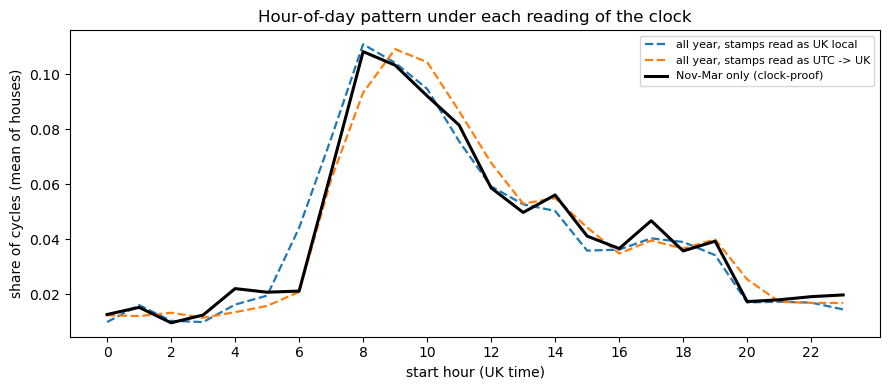

In [33]:
# Three versions of the start-hour pattern (same houses, same cycles except the Nov-Mar filter)
WIN_MIN_CYCLES = 10
_st = pd.DatetimeIndex(CT["start"])                      # stored stamps (UTC-based index)
hour_stored = pd.Series(_st.hour, index=CT.index)        # reading 1: stamps are already UK local
hour_london = pd.Series(_st.tz_localize("UTC").tz_convert(TZ).hour, index=CT.index)   # reading 2: stamps are UTC
def is_winter(idx):
    """Nov-Mar up to the 24th: GMT = UTC, so stored stamp = UK wall clock under both readings (UK clocks go forward on the last Sunday of March, always 25th or later)."""
    idx = pd.DatetimeIndex(idx)
    return np.asarray((idx.month >= 11) | (idx.month <= 2) | ((idx.month == 3) & (idx.day <= 24)))
CT_winter = pd.Series(is_winter(_st), index=CT.index)

n_win = CT[CT_winter].groupby("house").size().reindex(selected, fill_value=0)
clock_houses = n_win.index[n_win >= WIN_MIN_CYCLES].tolist()
print(f"Houses with at least {WIN_MIN_CYCLES} Nov-Mar cycles: {len(clock_houses)} of {len(selected)}; Nov-Mar cycles used: {int(n_win[clock_houses].sum()):,}")

def hour_curve(hours, mask):
    sel = mask & CT["house"].isin(clock_houses)
    hs = (pd.crosstab(CT.loc[sel, "house"], hours[sel], normalize="index")
          .reindex(index=clock_houses, columns=range(24), fill_value=0))
    return hs.mean(), int(sel.sum())

all_rows = pd.Series(True, index=CT.index)
versions = {"all year, stamps read as UK local": (hour_stored, all_rows),
            "all year, stamps read as UTC -> UK": (hour_london, all_rows),
            "Nov-Mar only (clock-proof)": (hour_stored, CT_winter)}
curves, rows = {}, []
for name, (hrs, mk) in versions.items():
    cv, n = hour_curve(hrs, mk); curves[name] = cv
    rows.append({"version": name, "cycles": n, "busiest_hour": int(cv.idxmax()),
                 "share_06_12_pct": 100 * cv[6:12].sum(), "share_16_19_pct": 100 * cv[16:19].sum(),
                 "share_22_06_pct": 100 * (cv[22:].sum() + cv[:6].sum())})
clock_tab = pd.DataFrame(rows).set_index("version")
print(clock_tab.round(1).to_string())
win = curves["Nov-Mar only (clock-proof)"]
for k in ["all year, stamps read as UK local", "all year, stamps read as UTC -> UK"]:
    print(f"Largest hourly gap in share, Nov-Mar vs [{k}]: {100 * (curves[k] - win).abs().max():.1f} pp")
clock_tab.to_csv(OUT_DIR / "tables" / "task2_hour_clock_robustness.csv")

fig, ax = plt.subplots(figsize=(9, 4))
for (name, cv), c in zip(curves.items(), ["tab:blue", "tab:orange", "black"]):
    ax.plot(range(24), cv, lw=2.2 if "Nov" in name else 1.6, ls="-" if "Nov" in name else "--", color=c, label=name)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("start hour (UK time)"); ax.set_ylabel("share of cycles (mean of houses)")
ax.set_title("Hour-of-day pattern under each reading of the clock"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("task2_hour_clock_robustness"); plt.show()

### (i) Representative 24 h: aggregate and washing machine

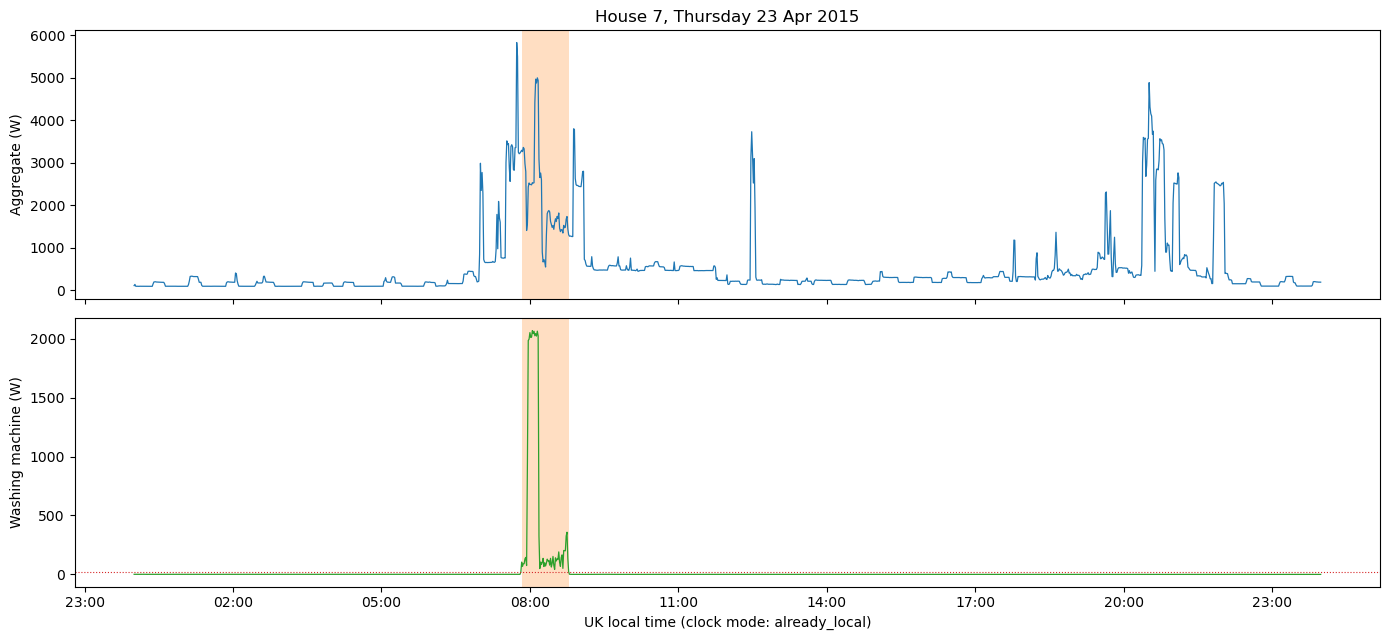

House 7, Thursday 23 Apr 2015: aggregate 13.1 kWh for the day (house median day 13.1 kWh), peaking at 5833 W at 07:44.
  Washing machine: 07:50 to 08:47, 58 min (house median 60), 0.55 kWh (house median 0.54), 4% of the day, peak 2068 W
Minutes above 1000 W with the washing machine off: 112


In [34]:
import matplotlib.dates as mdates
rep_house = int(avail.loc[selected, "usable"].idxmax())
mrep = add_local(M[rep_house])
dtab = DAYS[rep_house]
ccy = CT[CT["house"] == rep_house]
med_dur, med_e = ccy["dur_min"].median(), ccy["energy_kwh"].median()
day_kwh_all = mrep.groupby("date")["agg"].sum() / 60 / 1000
med_day = day_kwh_all.reindex(dtab.index[dtab["usable"]]).median()
per_day = ccy.groupby("date").agg(n_cycles=("dur_min", "size"), dur=("dur_min", "first"), e=("energy_kwh", "first"))

cand = dtab[(dtab["rows"] == 1440) & (dtab["frac"] >= 0.98) & (dtab["issues"] == 0)].join(per_day, how="inner")
cand = cand[cand["n_cycles"] == 1]
if cand.empty:   # relax if the house has no perfect single-cycle day
    cand = dtab[(dtab["rows"] == 1440) & (dtab["frac"] >= VALID_DAY_FRAC)].join(per_day, how="inner")
    cand = cand[cand["n_cycles"].between(1, 2)]
cand["agg_kwh"] = day_kwh_all.reindex(cand.index)
cand["score"] = (np.log(cand["dur"] / med_dur).abs() + np.log(cand["e"] / med_e).abs() + np.log(cand["agg_kwh"] / med_day).abs())
rep_day = cand["score"].idxmin()

day = mrep[mrep["date"] == rep_day]
cy = CT[(CT["house"] == rep_house) & (CT["date"] == rep_day)]
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
ax[0].plot(day["t_local"], day["agg"], lw=0.9); ax[0].set_ylabel("Aggregate (W)")
ax[1].plot(day["t_local"], day["wm"], lw=0.9, color="tab:green"); ax[1].set_ylabel("Washing machine (W)")
ax[1].axhline(ACTIVE_W, color="tab:red", ls=":", lw=0.8)
for a in ax:
    for _, r in cy.iterrows():
        a.axvspan(r["start_local"], r["end_local"], color="tab:orange", alpha=0.25, lw=0)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax[1].xaxis.set_major_locator(mdates.HourLocator(interval=3))
ax[1].set_xlabel(f"UK local time (clock mode: {CLOCK['mode']})")
ax[0].set_title(f"House {rep_house}, {rep_day:%A %d %b %Y}")
plt.tight_layout(); savefig("task2_representative_day"); plt.show()

day_kwh = day["agg"].sum() / 60 / 1000
peak_t = day.loc[day["agg"].idxmax(), "t_local"]
print(f"House {rep_house}, {rep_day:%A %d %b %Y}: aggregate {day_kwh:.1f} kWh for the day (house median day {med_day:.1f} kWh), "
      f"peaking at {day['agg'].max():.0f} W at {peak_t:%H:%M}.")
for _, r in cy.iterrows():
    print(f"  Washing machine: {r['start_local']:%H:%M} to {r['end_local']:%H:%M}, {r['dur_min']:.0f} min (house median {med_dur:.0f}), "
          f"{r['energy_kwh']:.2f} kWh (house median {med_e:.2f}), {100 * r['energy_kwh'] / day_kwh:.0f}% of the day, peak {r['peak_w']:.0f} W")
print(f"Minutes above 1000 W with the washing machine off: {int(((day['agg'] > 1000) & ~(day['wm'] > ACTIVE_W)).sum())}")


House 7, Thu 23 Apr 2015: one 58-min wash (0.55 kWh, 4% of the day's 13.1 kWh). It is hard to spot in the aggregate: the day peaks at 5.8 kW from other loads, with 112 minutes above 1 kW while the machine is off.

### (ii) Detected cycles

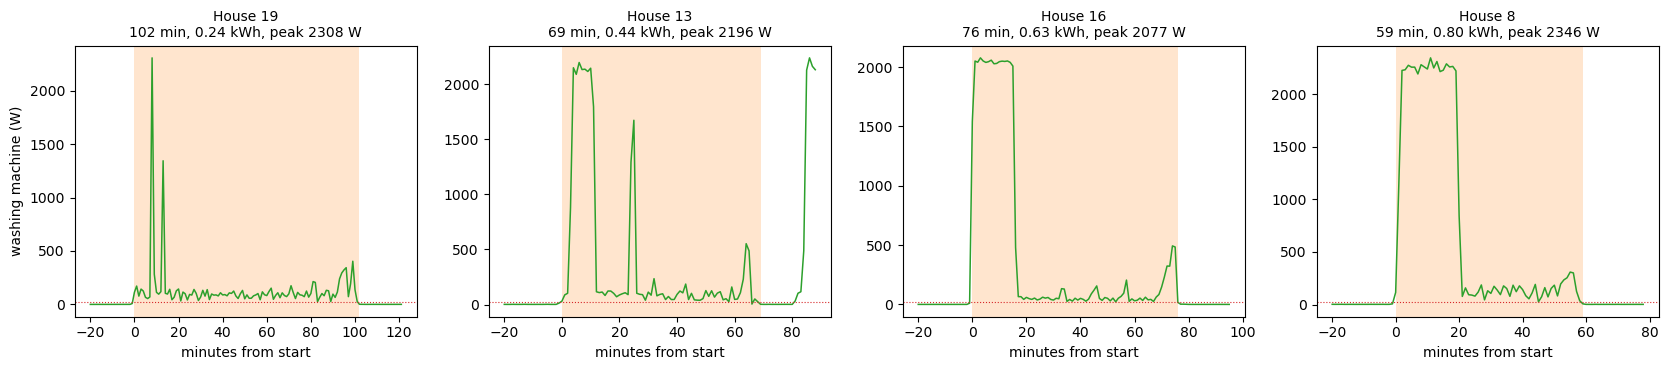

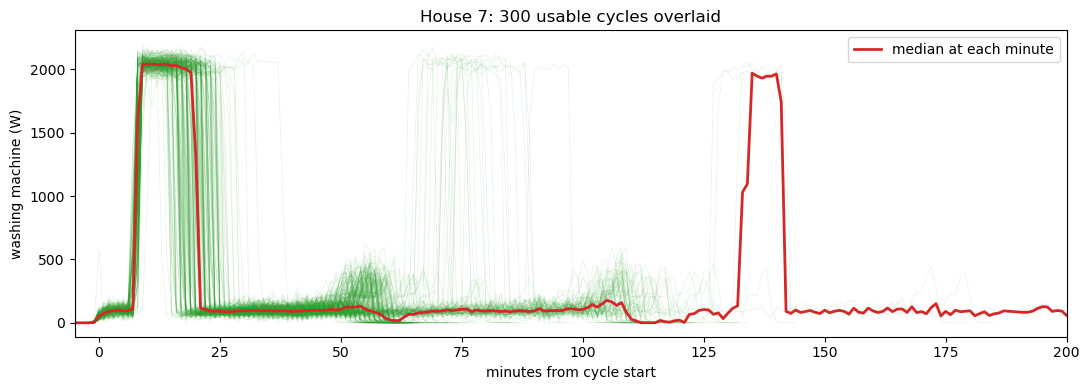

Plotted cycles:
  House 19: 14 May 2014 21:26, 102 min, 0.24 kWh, peak 2308 W, 2% of the cycle at or above 1000 W
  House 13: 11 Oct 2014 12:06, 69 min, 0.44 kWh, peak 2196 W, 14% of the cycle at or above 1000 W
  House 16: 24 Jan 2015 08:01, 76 min, 0.63 kWh, peak 2077 W, 21% of the cycle at or above 1000 W
  House 8: 22 Nov 2014 01:50, 59 min, 0.80 kWh, peak 2346 W, 32% of the cycle at or above 1000 W
House 7 overlay: median duration 60 min, 10th to 90th percentile 55 to 113 min; 100% of cycles have at least 5 minutes at or above 1000 W
Reading: Spearman correlation of cycle energy with minutes at heating power 0.96, with peak power 0.20.


In [35]:
med_e = CS.groupby("house")["energy_kwh"].median().sort_values()
pick = [med_e.index[i] for i in np.unique(np.linspace(0, len(med_e) - 1, 4).round().astype(int))]

fig, axes = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 3.8), sharey=False)
axes = np.atleast_1d(axes)
shown = []
for ax, h in zip(axes, pick):
    c = CS[CS["house"] == h]
    r = c.iloc[(c["energy_kwh"] - c["energy_kwh"].median()).abs().argmin()]
    s, e = int(r["start_i"]), int(r["end_i"])
    lo, hi = max(s - 20, 0), min(e + 20, len(M[h]))
    w = M[h]["wm"].iloc[lo:hi].to_numpy()
    x = np.arange(lo, hi) - s
    ax.plot(x, w, lw=1.1, color="tab:green")
    ax.axvspan(0, e - s, color="tab:orange", alpha=0.2, lw=0)
    ax.axhline(ACTIVE_W, color="tab:red", ls=":", lw=0.8)
    ax.set_title(f"House {h}\n{r['dur_min']:.0f} min, {r['energy_kwh']:.2f} kWh, peak {r['peak_w']:.0f} W", fontsize=10)
    ax.set_xlabel("minutes from start")
    shown.append((h, r))
axes[0].set_ylabel("washing machine (W)")
plt.tight_layout(); savefig("task2_detected_cycles"); plt.show()

focus = int(avail.loc[selected, "usable"].idxmax())
cf = CS[CS["house"] == focus]
cf = cf.sample(min(len(cf), 300), random_state=0)
pw = M[focus]["wm"].to_numpy("float64")
L = 200
stack = np.full((len(cf), L + 10), np.nan)
fig, ax = plt.subplots(figsize=(11, 4))
for k, (_, r) in enumerate(cf.iterrows()):
    s, e = int(r["start_i"]), int(r["end_i"])
    seg = pw[max(s - 5, 0): min(e + 5, len(pw))][: L + 10]
    stack[k, : len(seg)] = seg
    ax.plot(np.arange(len(seg)) - 5, seg, lw=0.5, alpha=0.12, color="tab:green")
with np.errstate(all="ignore"), warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    med_shape = np.nanmedian(stack, axis=0)
ax.plot(np.arange(L + 10) - 5, med_shape, color="tab:red", lw=2, label="median at each minute")
ax.set_xlim(-5, L); ax.set_xlabel("minutes from cycle start"); ax.set_ylabel("washing machine (W)")
ax.set_title(f"House {focus}: {len(cf)} usable cycles overlaid"); ax.legend()
plt.tight_layout(); savefig("task2_cycle_overlay"); plt.show()

print("Plotted cycles:")
for h, r in shown:
    heat_share = M[h]["wm"].iloc[int(r["start_i"]): int(r["end_i"])].ge(HEAT_W).mean()
    print(f"  House {h}: {r['start_local']:%d %b %Y %H:%M}, {r['dur_min']:.0f} min, {r['energy_kwh']:.2f} kWh, "
          f"peak {r['peak_w']:.0f} W, {100 * heat_share:.0f}% of the cycle at or above {HEAT_W} W")
print(f"House {focus} overlay: median duration {cf['dur_min'].median():.0f} min, "
      f"10th to 90th percentile {cf['dur_min'].quantile(.1):.0f} to {cf['dur_min'].quantile(.9):.0f} min; "
      f"{cf['heated'].mean():.0%} of cycles have at least {HEAT_MIN} minutes at or above {HEAT_W} W")

rho_heat = CS[["energy_kwh", "heat_min"]].corr(method="spearman").iloc[0, 1]
rho_peak = CS[["energy_kwh", "peak_w"]].corr(method="spearman").iloc[0, 1]
print(f"Reading: Spearman correlation of cycle energy with minutes at heating power {rho_heat:.2f}, with peak power {rho_peak:.2f}.")

The rule finds whole washes: a heating burst, then a long low-power tumble and spin. Cycle energy follows the time spent heating (Spearman 0.96), not peak power (0.20). In House 7 the median cycle is 60 min (10th-90th percentile 55-113).

### (iii) Cross-house comparison

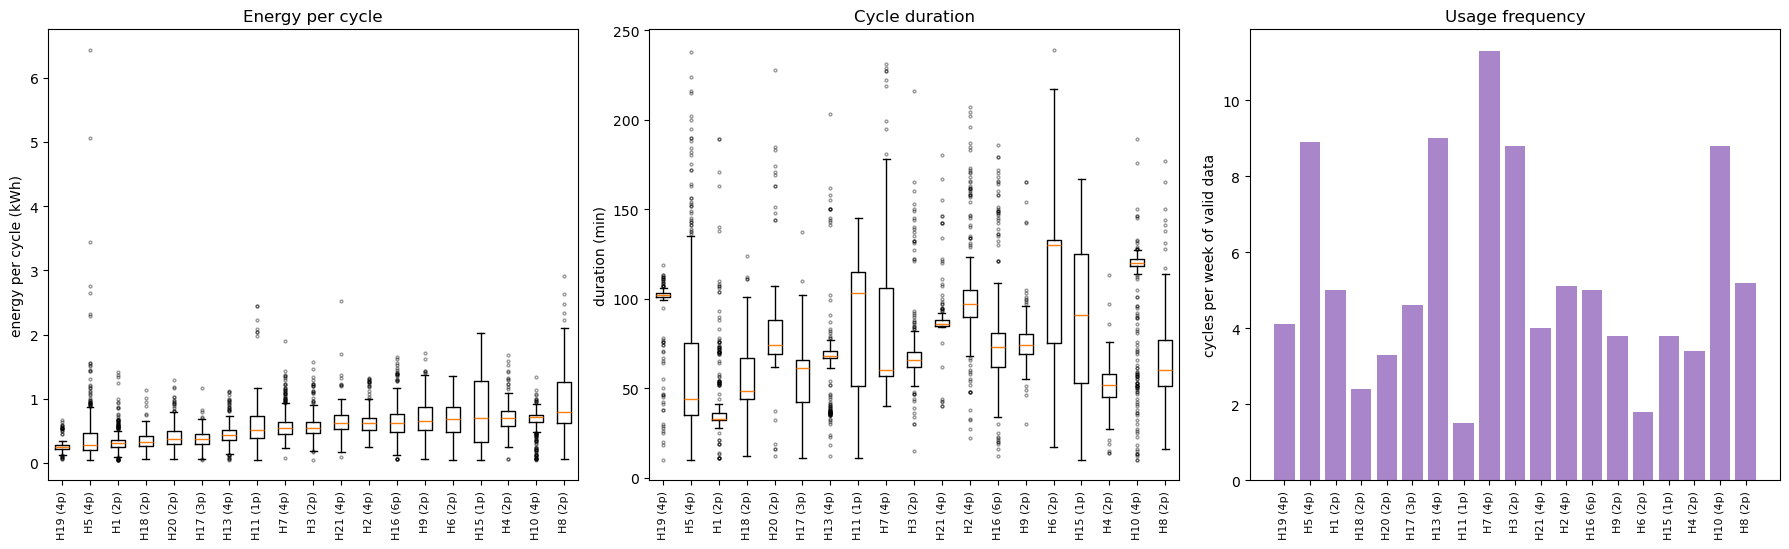

       cycles  dur_med  energy_med  peak_med  heated_share  cycles_per_week  occupants
house                                                                                 
19        244    102.0        0.24   1753.31          0.09              4.1          4
5         655     44.0        0.29   2069.00          0.72              8.9          4
1         376     33.0        0.32   2325.70          0.85              5.0          2
18        128     48.5        0.32   2190.83          0.84              2.4          2
20        189     74.0        0.38   2271.88          0.86              3.3          2
17        275     61.0        0.38   2046.12          0.85              4.6          3
13        277     68.0        0.44   2128.88          0.90              9.0          4
11         71    103.0        0.52   2311.50          0.93              1.5          1
7         826     60.0        0.54   2082.56          1.00             11.3          4
3         499     66.0        0.55   1922.4

In [36]:
order = CS.groupby("house")["energy_kwh"].median().sort_values().index.tolist()
labels = [f"H{h} ({OCCUPANTS[h]}p)" for h in order]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
axes[0].boxplot([CS.loc[CS["house"] == h, "energy_kwh"] for h in order], showfliers=True,
                flierprops=dict(markersize=2, alpha=0.4))
axes[0].set_xticks(range(1, len(order) + 1)); axes[0].set_xticklabels(labels, rotation=90, fontsize=8)
axes[0].set_ylabel("energy per cycle (kWh)"); axes[0].set_title("Energy per cycle")
axes[1].boxplot([CS.loc[CS["house"] == h, "dur_min"] for h in order], showfliers=True,
                flierprops=dict(markersize=2, alpha=0.4))
axes[1].set_xticks(range(1, len(order) + 1)); axes[1].set_xticklabels(labels, rotation=90, fontsize=8)
axes[1].set_ylabel("duration (min)"); axes[1].set_title("Cycle duration")
axes[2].bar(range(len(order)), avail.loc[order, "cycles_per_week"].astype(float), color="tab:purple", alpha=0.8)
axes[2].set_xticks(range(len(order))); axes[2].set_xticklabels(labels, rotation=90, fontsize=8)
axes[2].set_ylabel("cycles per week of valid data"); axes[2].set_title("Usage frequency")
plt.tight_layout(); savefig("task2_cross_house_comparison"); plt.show()

summ = CS.groupby("house").agg(cycles=("energy_kwh", "size"),
                               dur_med=("dur_min", "median"), energy_med=("energy_kwh", "median"),
                               peak_med=("peak_w", "median"), heated_share=("heated", "mean")).loc[order]
summ["cycles_per_week"] = avail.loc[order, "cycles_per_week"].astype(float)
summ["occupants"] = [OCCUPANTS[h] for h in order]
print(summ.round(2).to_string())
summ.round(3).to_csv(OUT_DIR / "tables" / "task2_cycle_summary_by_house.csv")

lo_h, hi_h = order[0], order[-1]
print(f"\nMedian energy per cycle ranges from {summ['energy_med'].min():.2f} kWh (H{lo_h}) to {summ['energy_med'].max():.2f} kWh (H{hi_h}), "
      f"a factor of {summ['energy_med'].max() / summ['energy_med'].min():.1f}.")
print(f"Median duration ranges from {summ['dur_med'].min():.0f} to {summ['dur_med'].max():.0f} min; "
      f"cycles per week from {summ['cycles_per_week'].min():.1f} to {summ['cycles_per_week'].max():.1f}.")
rho = summ[["cycles_per_week", "occupants"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation, cycles per week vs occupants: {rho:.2f} (only {len(summ)} houses, so read it as a hint, not a result)")

big = CS[CS["energy_kwh"] > 2].groupby("house").size()
print(f"- Heated share of cycles (5+ minutes at or above {HEAT_W} W) by house: {summ['heated_share'].min():.0%} (H{summ['heated_share'].idxmin()}) to {summ['heated_share'].max():.0%} (H{summ['heated_share'].idxmax()}).")
print(f"- Usable cycles above 2 kWh, unusual for one wash: {dict(big) if len(big) else 'none'}. Large values can mean a washer-dryer or a mixed channel, so treat those houses with care.")

Median energy per cycle ranges from 0.24 kWh (H19) to 0.80 kWh (H8), and frequency from 1.5 (H11) to 11.3 (H7) washes a week. H19 rarely heats the water (9% of its washes vs 72-100% elsewhere), which explains its low energy.

### Task 2 limits
- Cycles are detected events, not verified washes. A wash with a long pause counts as two.
- Energy is estimated from 1-minute means.
- The cleaned clock is inconsistent (see clock checks), so hour-of-day may be 1 h off in some summer months.
- House 4 sums two machines. Cycles above 2 kWh may be a mixed channel (e.g. a washer-dryer).

## 3. Appliance disaggregation model

**Goal:** Predict washing-machine power from household aggregate data using official cleaned REFIT data at 1-minute resolution. Excluded House 4 (two machines in one channel) and used only minutes with `Issues = 0`.

- **Model:** Gradient boosting with aggregate data from −60 to +60 minutes. Uses future readings, so suitable for retrospective analysis, not real-time control.
- **Baselines:** Always-off, hour-of-week usage profile, and a simple aggregate-power rule.
- **Validation:** Split by household into train, validation, and test sets to prevent leakage and evaluate performance on unseen homes. Validation households determine model settings and the on/off threshold.
- **Limitation:** All households cover 2013–2015, so training and test sets share seasons.

### References
- Zhang et al. (2018), *Sequence-to-point learning with neural networks for non-intrusive load monitoring*, AAAI.
- Kelly & Knottenbelt (2015), *Neural NILM: Deep neural networks applied to energy disaggregation*, BuildSys.
- Batra et al. (2014), *NILMTK: An open source toolkit for non-intrusive load monitoring*, e-Energy.
- Pereira & Nunes (2018), *Performance evaluation in non-intrusive load monitoring: Datasets, metrics, and tools—a review*, WIREs Data Mining and Knowledge Discovery.
- Klemenjak et al. (2019), *On metrics to assess the transferability of machine learning models in non-intrusive load monitoring*, arXiv:1912.06200.
- Ke et al. (2017), *LightGBM: A highly efficient gradient boosting decision tree*, NeurIPS.
- Murray et al. (2017), *An electrical load measurements dataset of United Kingdom households from a two-year longitudinal study*, Scientific Data (REFIT).

The references informed the modelling approach, validation design, and evaluation metrics. The implementation is original.

In [37]:
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy import stats

RNG = 0
# --- features: all computed from the AGGREGATE only, inside one house ---
FEAT_OFFSETS_MIN = [-60, -45, -30, -20, -15, -10, -7, -5, -4, -3, -2, -1, 1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 45, 60]
ROLL_MIN = [5, 15, 30, 60]     # centred rolling windows
BASE_MIN = 61                  # "base load" = lowest aggregate in this centred window (fridge, standby, router)
STEP_W = 500                   # a jump of this many W between neighbouring samples counts as a "step"
HOT_W = 1000                   # a heating-type load is at least this many W above base

# --- training sample (all positives and the minutes near them, a thinned share of far-away off minutes) ---
NEAR_MIN = 15
FAR_KEEP = 0.10                # kept far-off minutes get weight 1/FAR_KEEP so the average stays unbiased

# --- model search (chosen on the validation houses only) ---
GRID = [dict(max_leaf_nodes=15), dict(max_leaf_nodes=63)]
LR, MAX_ITER, MIN_LEAF = 0.1, 300, 200
TAU_GRID = [0, 10, 20, 30, 40, 60, 80, 100, 150, 200]   # predictions below tau are set to 0

MODEL_EXCLUDE = {4: "two washing machines summed in one channel"}
SPLIT_OVERRIDE = None          # e.g. {"train": [...], "val": [...], "test": [...]} to force a split
EVAL_DAY_FRAC = 0.9            # a day counts for daily-energy scores if 90% of it is usable
MODELS = ["always_off", "profile", "gbm"]
MODEL_LABEL = {"always_off": "always off", "profile": "hour-of-week profile", "gbm": "gradient boosting"}

# Appliance names per house, from the README (used only to NAME the other loads in the failure analysis)
APPLIANCE_LISTS = {
 1: ["Fridge","Freezer(1)","Freezer(2)","Washer Dryer","Washing Machine","Dishwasher","Computer","Television Site","Electric Heater"],
 2: ["Fridge-Freezer","Washing Machine","Dishwasher","Television Site","Microwave","Toaster","Hi-Fi","Kettle","Overhead Fan"],
 3: ["Toaster","Fridge-Freezer","Freezer","Tumble Dryer","Dishwasher","Washing Machine","Television Site","Microwave","Kettle"],
 4: ["Fridge","Freezer","Fridge-Freezer","Washing Machine(1)","Washing Machine(2)","Desktop Computer","Television Site","Microwave","Kettle"],
 5: ["Fridge-Freezer","Tumble Dryer","Washing Machine","Dishwasher","Desktop Computer","Television Site","Microwave","Kettle","Toaster"],
 6: ["Freezer","Washing Machine","Dishwasher","MJY Computer","TV/Satellite","Microwave","Kettle","Toaster","PGM Computer"],
 7: ["Fridge","Freezer(1)","Freezer(2)","Tumble Dryer","Washing Machine","Dishwasher","Television Site","Toaster","Kettle"],
 8: ["Fridge","Freezer","Washer Dryer","Washing Machine","Toaster","Computer","Television Site","Microwave","Kettle"],
 9: ["Fridge-Freezer","Washer Dryer","Washing Machine","Dishwasher","Television Site","Microwave","Kettle","Hi-Fi","Electric Heater"],
 10: ["Magimix (Blender)","Toaster","Chest Freezer","Fridge-Freezer","Washing Machine","Dishwasher","Television Site","Microwave","K Mix"],
 11: ["Fridge","Fridge-Freezer","Washing Machine","Dishwasher","Computer Site","Microwave","Kettle","Router","Hi-Fi"],
 12: ["Fridge-Freezer","Unknown","Unknown","Computer Site","Microwave","Kettle","Toaster","Television","Unknown"],
 13: ["Television Site","Freezer","Washing Machine","Dishwasher","Unknown","Network Site","Microwave","Microwave","Kettle"],
 15: ["Fridge-Freezer","Tumble Dryer","Washing Machine","Dishwasher","Computer Site","Television Site","Microwave","Hi-Fi","Toaster"],
 16: ["Fridge-Freezer(1)","Fridge-Freezer(2)","Electric Heater(1)","Electric Heater(2)","Washing Machine","Dishwasher","Computer Site","Television Site","Dehumidifier"],
 17: ["Freezer","Fridge-Freezer","Tumble Dryer","Washing Machine","Computer Site","Television Site","Microwave","Kettle","TV Site (Bedroom)"],
 18: ["Fridge (garage)","Freezer (garage)","Fridge-Freezer","Washer Dryer (garage)","Washing Machine","Dishwasher","Desktop Computer","Television Site","Microwave"],
 19: ["Fridge-Freezer","Washing Machine","Television Site","Microwave","Kettle","Toaster","Bread-maker","Games Console","Hi-Fi"],
 20: ["Fridge","Freezer","Tumble Dryer","Washing Machine","Dishwasher","Computer Site","Television Site","Microwave","Kettle"],
 21: ["Fridge-Freezer","Tumble Dryer","Washing Machine","Dishwasher","Food Mixer","Television","Kettle","Vivarium","Pond Pump"],
}
print("sklearn model class ready | active threshold", ACTIVE_W, "W | rows used: valid minutes with Issues == 0")

sklearn model class ready | active threshold 20 W | rows used: valid minutes with Issues == 0


### Train / validation / test split
Houses are sorted by washes per week and every 5th goes to test (or validation). This is fixed before any model is fitted, so nobody picks an easy test set. Note that 3 of the 4 test houses (2, 13, 21) have data-quality flags, so this test set is on the harder side.

In [38]:
cand = [h for h in selected if h not in MODEL_EXCLUDE]
order_c = avail.loc[cand].sort_values("cycles_per_week").index.tolist()
if SPLIT_OVERRIDE:
    SPLIT = {k: list(v) for k, v in SPLIT_OVERRIDE.items()}
else:
    SPLIT = {"test": [h for i, h in enumerate(order_c) if i % 5 == 1],
             "val":  [h for i, h in enumerate(order_c) if i % 5 == 3]}
    SPLIT["train"] = [h for h in order_c if h not in SPLIT["test"] + SPLIT["val"]]
allh = SPLIT["train"] + SPLIT["val"] + SPLIT["test"]
assert len(allh) == len(set(allh)), "a house is in two splits"
assert all(h in M for h in allh)

rows = []
for sp in ["train", "val", "test"]:
    for h in SPLIT[sp]:
        m = M[h]; ok = (m["valid"] & (m["issues"] == 0)).to_numpy()
        rows.append({"split": sp, "house": h, "channel": avail.loc[h, "channel"], "occupants": OCCUPANTS[h],
                     "first_day": avail.loc[h, "first_day"], "last_day": avail.loc[h, "last_day"],
                     "model_minutes": int(ok.sum()), "cycles": int(avail.loc[h, "cycles"]),
                     "cycles_per_week": avail.loc[h, "cycles_per_week"], "flags": avail.loc[h, "flags"]})
split_tab = pd.DataFrame(rows).set_index(["split", "house"])
print(split_tab.to_string())
print("\nLeft out of the model:", {h: r for h, r in MODEL_EXCLUDE.items()}, "| not in Task 2's deep-dive list:", [h for h in avail.index if h not in selected])
for sp in ["train", "val", "test"]:
    s = split_tab.loc[sp]
    print(f"{sp:>5}: {len(s)} houses, {s['model_minutes'].sum():,} usable minutes, {s['cycles'].sum()} cycles, cycles/week {s['cycles_per_week'].min()}-{s['cycles_per_week'].max()}")
print("\nMarkdown for RESULTS.md:\n"); print(to_md(split_tab.reset_index().set_index("house")))
split_tab.to_csv(OUT_DIR / "tables" / "task3_split.csv")

            channel  occupants   first_day    last_day  model_minutes  cycles  cycles_per_week            flags
split house                                                                                                    
train 11         A3          1  2014-06-03  2015-06-30         495009      76              1.5           issues
      18         A5          2  2014-03-07  2015-05-22         572621     137              2.4                -
      15         A3          1  2013-12-17  2015-07-08         699455     261              3.8                -
      9          A3          2  2013-12-17  2015-07-08         655133     247              3.8                -
      19         A2          4  2014-03-06  2015-06-20         626815     258              4.1                -
      1          A5          2  2013-10-09  2015-07-10         798430     396              5.0                -
      16         A5          6  2014-01-10  2015-07-08         633623     317              5.0          

### Features
All come from the aggregate, inside one house: net load (aggregate minus the house's base load) at offsets from -60 to +60 min, rolling mean / max / std, counts of big steps and of heating-type load (over 1 kW above base), hour and weekday. Missing minutes stay NaN. No feature uses the washing-machine channel.

In [39]:
def _steps(minutes, res):
    return max(1, int(round(minutes / res)))

def coarsen(m, res):
    """1-minute frame -> frame of `res`-minute block means (res=1 returns the same minutes). A block is valid if >= 80% of its minutes are."""
    if res == 1:
        return m[["agg", "wm", "valid", "issues"]]
    g = pd.DataFrame({"agg": m["agg"].where(m["valid"]), "wm": m["wm"].where(m["valid"]),
                      "v": m["valid"].astype(float), "iss": m["issues"].astype(float)}).resample(f"{res}min").mean()
    out = pd.DataFrame({"agg": g["agg"], "wm": g["wm"]})
    out["valid"] = (g["v"] >= 0.8) & out["agg"].notna() & out["wm"].notna()
    out["issues"] = (g["iss"] > 0.5).astype("int8")
    return out

def make_features(m, res=1):
    """Window features from the aggregate only. Offsets and windows are given in minutes and converted to samples."""
    a = m["agg"].where(m["valid"]).astype("float32")
    kb = _steps(BASE_MIN, res) | 1
    base = a.rolling(kb, center=True, min_periods=max(1, kb // 4)).min()
    net = (a - base).clip(lower=0)
    F = {"a0": a, "base": base, "net0": net}
    for o in sorted({int(round(x / res)) for x in FEAT_OFFSETS_MIN} - {0}):
        F[f"net_{o:+d}"] = net.shift(-o)                     # +o = o samples in the future
    d1 = a.diff()
    F["d1"], F["d1_next"] = d1, d1.shift(-1)
    big = (d1.abs() > STEP_W).astype("float32").where(d1.notna())
    hot = (net > HOT_W).astype("float32").where(net.notna())
    for wmin in ROLL_MIN:
        w = _steps(wmin, res)
        if w < 3:
            continue
        r = net.rolling(w, center=True, min_periods=max(1, w // 2))
        F[f"net_mean_{w}"], F[f"net_max_{w}"], F[f"net_std_{w}"] = r.mean(), r.max(), r.std()
        F[f"steps_{w}"] = big.rolling(w, center=True, min_periods=1).sum()
        F[f"hot_{w}"] = hot.rolling(w, center=True, min_periods=1).mean()
    tl = pd.DatetimeIndex(to_local_clock(m.index))
    hr = (tl.hour + tl.minute / 60).to_numpy()
    F["hour_sin"], F["hour_cos"] = np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24)
    F["dow"] = tl.dayofweek.to_numpy()
    return pd.DataFrame(F, index=m.index).astype("float32")

def eligible(m, X):
    """Rows the model is trained / scored on: valid, Issues == 0, target and aggregate present."""
    return (m["valid"] & (m["issues"] == 0) & m["wm"].notna() & X["a0"].notna()).to_numpy()

def sample_rows(h, res=1, far_keep=None, seed=RNG):
    """Training / selection sample for one house: every active minute, every minute near one, a thinned share of the rest (weighted)."""
    far_keep = (FAR_KEEP if res == 1 else 1.0) if far_keep is None else far_keep
    m = coarsen(M[h], res); X = make_features(m, res); y = m["wm"]
    ok = eligible(m, X)
    pos = ((y > ACTIVE_W).to_numpy() & ok)
    k = _steps(NEAR_MIN, res)
    near = pd.Series(pos.astype(float)).rolling(2 * k + 1, center=True, min_periods=1).max().to_numpy().astype(bool) & ok
    keep_far = ok & ~near & (np.random.default_rng(seed + h).random(len(m)) < far_keep)
    sel = near | keep_far
    w = np.where(near, 1.0, 1.0 / far_keep)[sel]
    return X[sel], y[sel].astype("float32"), w

Xdemo = make_features(coarsen(M[SPLIT["train"][0]], 1), 1)
print(f"{Xdemo.shape[1]} features, e.g.:", list(Xdemo.columns[:8]), "...")
print("NaN share per feature (house", SPLIT["train"][0], "), top 5:\n", Xdemo.isna().mean().sort_values(ascending=False).head(5).round(3).to_string())
del Xdemo

52 features, e.g.: ['a0', 'base', 'net0', 'net_-60', 'net_-45', 'net_-30', 'net_-20', 'net_-15'] ...
NaN share per feature (house 11 ), top 5:
 d1_next    0.118
d1         0.118
net_-60    0.117
net_+60    0.117
net_+45    0.117


### Training
Keeps every active minute, the minutes near them, and a random 10% of the other off minutes (weighted x10), since the machine is off ~96% of the time. Model size and number of trees are picked on the validation houses.

training rows 1,170,184 (weighted 7,431,007) | validation rows 281,934 (weighted 1,852,236) | features 52
  {'max_leaf_nodes': 15}: best validation MSE 14,977 at 214 trees (MSE after 300: 15,007)
  {'max_leaf_nodes': 63}: best validation MSE 15,056 at 28 trees (MSE after 300: 15,825)
chosen: {'max_leaf_nodes': 15}, 214 trees | 130 s


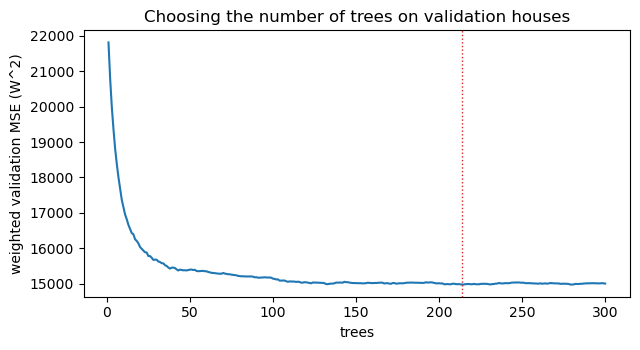

In [40]:
import time
def stack(houses, res=1):
    parts = [sample_rows(h, res) for h in houses]
    return pd.concat([p[0] for p in parts]), pd.concat([p[1] for p in parts]), np.concatenate([p[2] for p in parts])

def fit_gbm(tr, va, grid=GRID, label=""):
    """Pick (tree size, number of trees) by weighted validation MSE, refit on train with that many trees."""
    Xtr, ytr, wtr = tr; Xva, yva, wva = va
    best = None
    for cfg in grid:
        mdl = HistGradientBoostingRegressor(loss="squared_error", learning_rate=LR, max_iter=MAX_ITER, min_samples_leaf=MIN_LEAF,
                                            l2_regularization=1.0, early_stopping=False, random_state=RNG, **cfg).fit(Xtr, ytr, sample_weight=wtr)
        curve = np.array([np.average((np.clip(p, 0, None) - yva.to_numpy()) ** 2, weights=wva) for p in mdl.staged_predict(Xva)])
        it = int(curve.argmin()) + 1
        print(f"  {label}{cfg}: best validation MSE {curve.min():,.0f} at {it} trees (MSE after {MAX_ITER}: {curve[-1]:,.0f})")
        if best is None or curve.min() < best["mse"]:
            best = dict(cfg=cfg, it=it, mse=curve.min(), curve=curve)
    final = HistGradientBoostingRegressor(loss="squared_error", learning_rate=LR, max_iter=best["it"], min_samples_leaf=MIN_LEAF,
                                          l2_regularization=1.0, early_stopping=False, random_state=RNG, **best["cfg"]).fit(Xtr, ytr, sample_weight=wtr)
    return final, best

t0 = time.time()
TR = stack(SPLIT["train"]); VA = stack(SPLIT["val"])
print(f"training rows {len(TR[0]):,} (weighted {TR[2].sum():,.0f}) | validation rows {len(VA[0]):,} (weighted {VA[2].sum():,.0f}) | features {TR[0].shape[1]}")
GBM, BEST = fit_gbm(TR, VA)
print(f"chosen: {BEST['cfg']}, {BEST['it']} trees | {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(np.arange(1, MAX_ITER + 1), BEST["curve"], lw=1.5); ax.axvline(BEST["it"], color="tab:red", ls=":", lw=1)
ax.set_xlabel("trees"); ax.set_ylabel("weighted validation MSE (W^2)"); ax.set_title("Choosing the number of trees on validation houses")
plt.tight_layout(); savefig("task3_validation_curve"); plt.show()

### Baselines and on/off cut-off
*Always off* predicts 0 W. The *usage profile* predicts the mean power for each hour of the week. Model predictions below a cut-off tau are set to 0, with tau chosen on validation to maximise the F1 of "machine on".

In [41]:
def fit_profile(houses, res=1):
    """Mean washing-machine power per (hour, weekday) over the training houses' usable minutes."""
    tot = None
    for h in houses:
        m = coarsen(M[h], res); tl = pd.DatetimeIndex(to_local_clock(m.index))
        ok = (m["valid"] & (m["issues"] == 0) & m["wm"].notna()).to_numpy()
        g = pd.DataFrame({"hr": tl.hour[ok], "dow": tl.dayofweek[ok], "y": m["wm"].to_numpy()[ok]}).groupby(["hr", "dow"])["y"].agg(["sum", "count"])
        tot = g if tot is None else tot.add(g, fill_value=0)
    return (tot["sum"] / tot["count"]).rename("w")

def predict_house(h, model, profile, res=1):
    """Frame of target and every model's prediction for one house (raw, before the tau gate)."""
    m = coarsen(M[h], res); X = make_features(m, res)
    tl = pd.DatetimeIndex(to_local_clock(m.index))
    has = X["a0"].notna().to_numpy()
    p = np.zeros(len(m), "float32")
    if has.any():
        p[has] = np.clip(model.predict(X[has]), 0, None)
    prof = profile.reindex(pd.MultiIndex.from_arrays([tl.hour, tl.dayofweek])).to_numpy("float32")
    return pd.DataFrame({"agg": m["agg"].to_numpy("float32"), "y": m["wm"].to_numpy("float32"), "ok": eligible(m, X),
                         "always_off": np.zeros(len(m), "float32"), "profile": np.nan_to_num(prof), "gbm_raw": p,
                         "date": tl.normalize(), "hour": tl.hour.astype("int8")}, index=m.index)

def f1_on(y, p, thr=ACTIVE_W):
    on, pon = y > thr, p > thr
    tp = (on & pon).sum(); fp = (~on & pon).sum(); fn = (on & ~pon).sum()
    return 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan

def tune_tau(Rv, col):
    """tau that maximises pooled on-state F1 on the validation houses."""
    y = np.concatenate([r["y"].to_numpy()[r["ok"].to_numpy()] for r in Rv.values()])
    p = np.concatenate([r[col].to_numpy()[r["ok"].to_numpy()] for r in Rv.values()])
    sc = {t: f1_on(y, np.where(p >= t, p, 0.0)) for t in TAU_GRID}
    return max(sc, key=sc.get), sc

PROFILE = fit_profile(SPLIT["train"])
R = {}                                          # R[h]: per-minute frame for every val/test house
for h in SPLIT["val"] + SPLIT["test"]:
    R[h] = predict_house(h, GBM, PROFILE)
Rv = {h: R[h] for h in SPLIT["val"]}
TAU = {}
for col in ["profile", "gbm_raw"]:
    TAU[col], sc = tune_tau(Rv, col)
    print(f"{col:>8}: tau = {TAU[col]} W (validation on-state F1 by tau: " + ", ".join(f"{t}:{v:.2f}" for t, v in sc.items()) + ")")
for h, r in R.items():
    r["gbm"] = np.where(r["gbm_raw"] >= TAU["gbm_raw"], r["gbm_raw"], 0.0).astype("float32")
    r["profile"] = np.where(r["profile"] >= TAU["profile"], r["profile"], 0.0).astype("float32")
print("profile baseline: hour-of-week mean power ranges", f"{PROFILE.min():.1f}-{PROFILE.max():.1f} W (it never gets above the on-threshold unless tau is 0)" if PROFILE.max() <= ACTIVE_W else f"{PROFILE.min():.1f}-{PROFILE.max():.1f} W")

 profile: tau = 30 W (validation on-state F1 by tau: 0:0.10, 10:0.10, 20:0.10, 30:0.11, 40:0.06, 60:0.02, 80:0.00, 100:0.00, 150:0.00, 200:0.00)
 gbm_raw: tau = 30 W (validation on-state F1 by tau: 0:0.39, 10:0.39, 20:0.39, 30:0.41, 40:0.39, 60:0.33, 80:0.31, 100:0.30, 150:0.29, 200:0.29)
profile baseline: hour-of-week mean power ranges 1.9-62.3 W


### Metrics
The machine is off ~96% of the time, so plain MAE flatters a model that predicts nothing. I also report MAE on active minutes, RMSE, NDE (1 = no better than always off), SAE (energy bias), precision / recall / F1 of "machine on", and daily-energy error and correlation. All use valid minutes with `Issues` = 0.

In [42]:
def score(y, p, res=1, thr=ACTIVE_W):
    y = np.asarray(y, "float64"); p = np.asarray(p, "float64"); e = p - y
    on, pon = y > thr, p > thr
    tp, fp, fn = (on & pon).sum(), (~on & pon).sum(), (on & ~pon).sum()
    return {"MAE_W": np.abs(e).mean(), "MAE_on_W": np.abs(e[on]).mean() if on.any() else np.nan,
            "RMSE_W": np.sqrt((e ** 2).mean()), "NDE": (e ** 2).sum() / (y ** 2).sum(),
            "SAE_pct": 100 * (p.sum() - y.sum()) / y.sum(),
            "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan}

def daily_frame(r, col, res=1):
    ok = r["ok"].to_numpy()
    d = pd.DataFrame({"d": r["date"].to_numpy()[ok], "y": r["y"].to_numpy()[ok], "p": r[col].to_numpy()[ok]}).groupby("d").agg(n=("y", "size"), y=("y", "sum"), p=("p", "sum"))
    d = d[d["n"] * res >= EVAL_DAY_FRAC * 1440]
    return d[["y", "p"]] * res / 60.0                    # Wh per day

def daily_scores(d):
    if len(d) < 3:
        return {"day_MAE_Wh": np.nan, "day_corr": np.nan, "days": len(d)}
    c = np.corrcoef(d["y"], d["p"])[0, 1] if d["p"].std() > 0 and d["y"].std() > 0 else np.nan
    return {"day_MAE_Wh": (d["p"] - d["y"]).abs().mean(), "day_corr": c, "days": len(d)}

def metric_table(Rs, houses, models=MODELS, res=1):
    rows = []
    for name in models:
        col = name
        for h in houses + ["pooled"]:
            hs = houses if h == "pooled" else [h]
            y = np.concatenate([Rs[k]["y"].to_numpy()[Rs[k]["ok"].to_numpy()] for k in hs])
            p = np.concatenate([Rs[k][col].to_numpy()[Rs[k]["ok"].to_numpy()] for k in hs])
            s = score(y, p, res)
            s.update(daily_scores(pd.concat([daily_frame(Rs[k], col, res) for k in hs])))
            s.update(model=MODEL_LABEL[name], house=h); rows.append(s)
    return pd.DataFrame(rows).set_index(["model", "house"])

COLS = ["MAE_W", "MAE_on_W", "RMSE_W", "NDE", "SAE_pct", "precision", "recall", "F1", "day_MAE_Wh", "day_corr"]
for sp in ["val", "test"]:
    T = metric_table(R, SPLIT[sp])
    print(f"=== {sp.upper()} houses {SPLIT[sp]} | pooled over usable minutes ===")
    print(T.xs("pooled", level="house")[COLS + ["days"]].round(3).to_string())
    T.to_csv(OUT_DIR / "tables" / f"task3_metrics_{sp}.csv")
    if sp == "val": TV = T
    else: TT = T
print("\n=== TEST houses, per house, gradient boosting vs baselines (F1, SAE %, NDE) ===")
pv = TT.reset_index().pivot(index="house", columns="model", values=["F1", "SAE_pct", "NDE"]).round(2)
print(pv.to_string())

=== VAL houses [20, 17, 3] | pooled over usable minutes ===
                       MAE_W  MAE_on_W   RMSE_W    NDE  SAE_pct  precision  recall     F1  day_MAE_Wh  day_corr  days
model                                                                                                                
always off            15.335   435.520  152.495  1.000 -100.000        NaN   0.000  0.000  355.819000       NaN  1192
hour-of-week profile  20.948   423.895  152.077  0.995  -57.848      0.066   0.315  0.109  363.575989    -0.067  1192
gradient boosting     19.453   286.806  121.764  0.638   11.348      0.319   0.587  0.413  219.985001     0.799  1192
=== TEST houses [6, 21, 2, 13] | pooled over usable minutes ===
                       MAE_W  MAE_on_W   RMSE_W    NDE  SAE_pct  precision  recall     F1  day_MAE_Wh  day_corr  days
model                                                                                                                
always off            13.583   378.654  146.149  1

### Simple rule baseline
If net load is above 1 kW for 5+ of the surrounding 15 minutes, predict "washing" at the average active power of the training houses. No tuning.

In [43]:
# Simple rule baseline (aggregate only, no tuning)
act = pd.concat([M[h].loc[M[h]["valid"] & (M[h]["wm"] > ACTIVE_W), "wm"] for h in SPLIT["train"]])
RULE_W = float(act.mean())          # power predicted when the rule fires
for h in SPLIT["val"] + SPLIT["test"]:
    X = make_features(coarsen(M[h], 1), 1)
    fire = (X["hot_15"] >= 5 / 15).to_numpy()
    R[h]["rule"] = np.where(fire, RULE_W, 0.0).astype("float32")
MODEL_LABEL["rule"] = "simple rule (heavy load)"

T4 = metric_table(R, SPLIT["test"], models=["always_off", "profile", "rule", "gbm"])
print(f"Rule: predict {RULE_W:.0f} W when net load > {HOT_W} W in at least 5 of 15 surrounding minutes\n")
print("TEST houses, pooled:")
print(T4.xs("pooled", level="house")[COLS + ["days"]].round(3).to_string())
T4.to_csv(OUT_DIR / "tables" / "task3_metrics_test_with_rule.csv")

pr, pm = T4.loc[("simple rule (heavy load)", "pooled")], T4.loc[("gradient boosting", "pooled")]
print(f"\nModel vs rule: NDE {pm['NDE']:.2f} vs {pr['NDE']:.2f} | F1 {pm['F1']:.2f} vs {pr['F1']:.2f} | daily corr {pm['day_corr']:.2f} vs {pr['day_corr']:.2f}")
print("Model beats the rule on NDE and F1." if (pm["NDE"] < pr["NDE"] and pm["F1"] > pr["F1"])
      else "Model does NOT clearly beat the simple rule. Say so in the write-up.")

Rule: predict 459 W when net load > 1000 W in at least 5 of 15 surrounding minutes

TEST houses, pooled:
                           MAE_W  MAE_on_W   RMSE_W    NDE  SAE_pct  precision  recall     F1  day_MAE_Wh  day_corr  days
model                                                                                                                    
always off                13.583   378.654  146.149  1.000 -100.000        NaN   0.000  0.000  312.023010       NaN  1540
hour-of-week profile      19.151   367.762  145.865  0.996  -52.896      0.064   0.299  0.106  343.690002     0.048  1540
simple rule (heavy load)  50.191   375.672  175.927  1.449  218.585      0.151   0.399  0.219  773.630005     0.257  1540
gradient boosting         17.203   261.500  115.598  0.626    1.320      0.282   0.487  0.357  219.735992     0.751  1540

Model vs rule: NDE 0.63 vs 1.45 | F1 0.36 vs 0.22 | daily corr 0.75 vs 0.26
Model beats the rule on NDE and F1.


The model performs better than all baselines on the 4 test houses for NDE (0.63), F1 (0.36) and daily-energy correlation (0.75). However, its MAE is slightly worse than always-off (17.2 vs 13.6 W). Although the overall energy bias is only +1%, the model underestimates energy per detected wash by about 53%, with false alarms making up the difference.

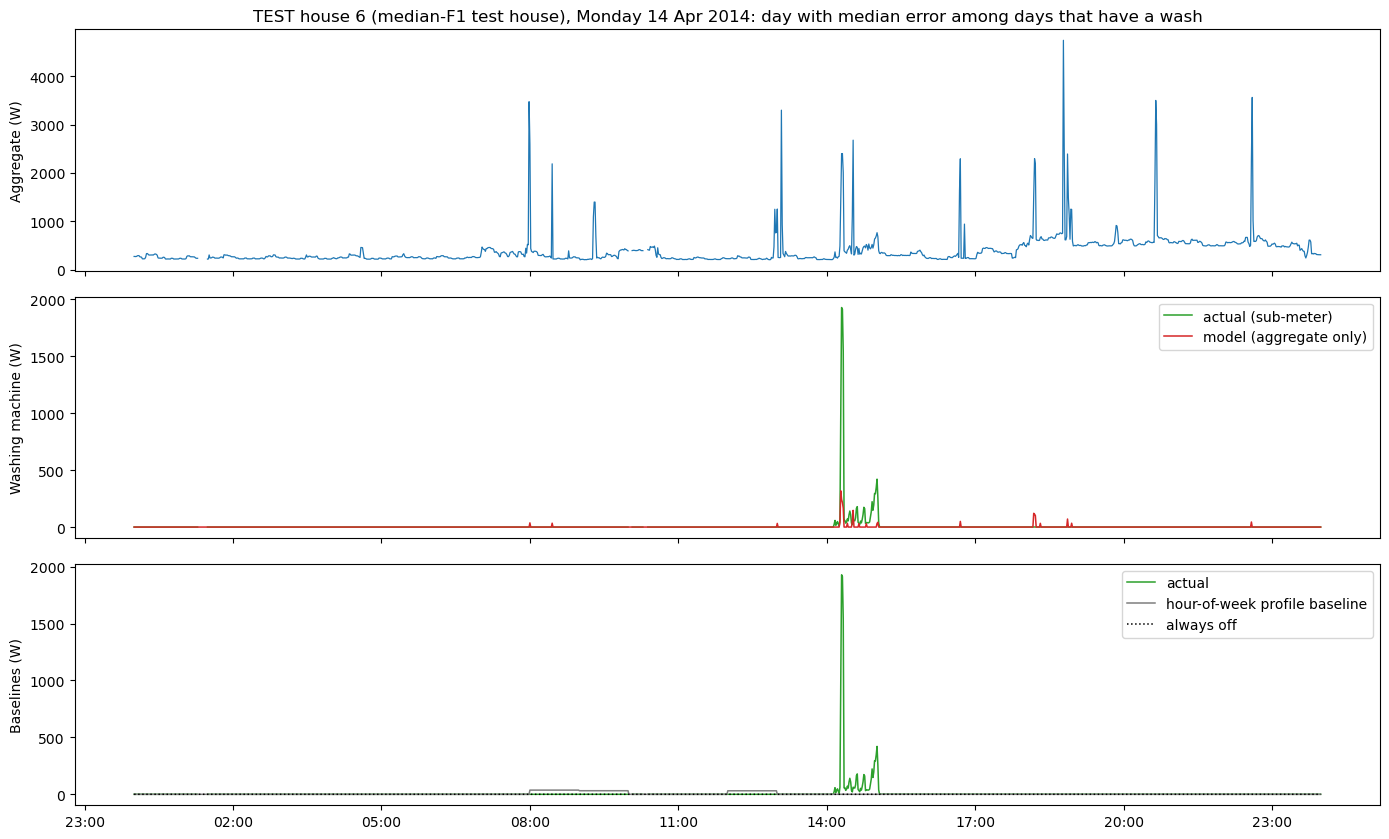

That day: actual energy 190 Wh, model 34 Wh; day NDE 0.77 (always-off = 1.00); on-state F1 0.32.


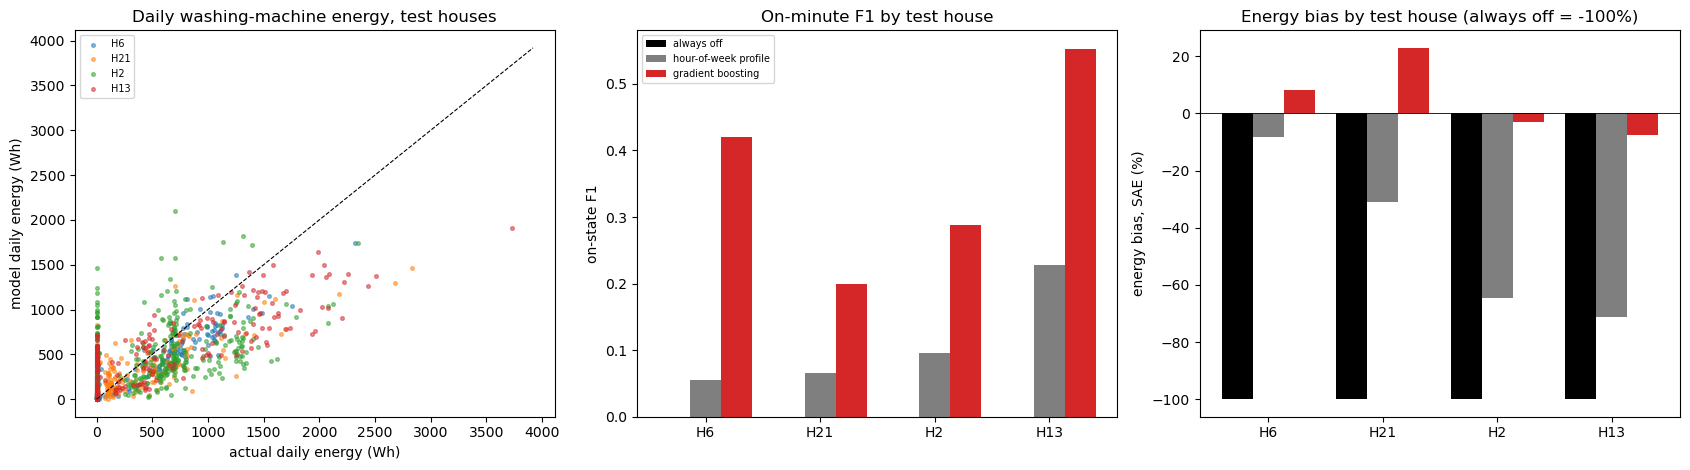

In [44]:
# ---- (a) one clear actual-vs-predicted plot on evaluation (test) data ----
g = TT.xs("gradient boosting", level="model")
g_h = g.drop(index="pooled")
rep_h = g_h["F1"].sort_values().index[len(g_h) // 2]          # the test house with the MEDIAN F1: representative, not the best
r = R[rep_h]; ok = r["ok"].to_numpy()
dd = r.assign(e2=(r["gbm"] - r["y"]) ** 2, y2=r["y"] ** 2)[ok]
byday = dd.groupby("date").agg(n=("y", "size"), e2=("e2", "sum"), y2=("y2", "sum"), ymax=("y", "max"))
byday = byday[(byday["n"] >= EVAL_DAY_FRAC * 1440) & (byday["ymax"] > ACTIVE_W)]
byday["nde"] = byday["e2"] / byday["y2"]
rep_day = (byday["nde"] - byday["nde"].median()).abs().idxmin()
day = r[r["date"] == rep_day]

fig, ax = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True)
ax[0].plot(day.index, day["agg"], lw=0.9, color="tab:blue"); ax[0].set_ylabel("Aggregate (W)")
ax[1].plot(day.index, day["y"], lw=1.1, color="tab:green", label="actual (sub-meter)")
ax[1].plot(day.index, day["gbm"], lw=1.1, color="tab:red", label="model (aggregate only)")
ax[1].set_ylabel("Washing machine (W)"); ax[1].legend(loc="upper right")
ax[2].plot(day.index, day["y"], lw=1.1, color="tab:green", label="actual")
ax[2].plot(day.index, day["profile"], lw=1.1, color="tab:gray", label="hour-of-week profile baseline")
ax[2].plot(day.index, day["always_off"], lw=1.1, color="black", ls=":", label="always off")
ax[2].set_ylabel("Baselines (W)"); ax[2].legend(loc="upper right")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax[2].xaxis.set_major_locator(mdates.HourLocator(interval=3))
ax[0].set_title(f"TEST house {rep_h} (median-F1 test house), {rep_day:%A %d %b %Y}: day with median error among days that have a wash")
plt.tight_layout(); savefig("task3_actual_vs_predicted_day"); plt.show()
dm = score(day["y"][day["ok"]], day["gbm"][day["ok"]])
print(f"That day: actual energy {day['y'][day['ok']].sum() / 60:.0f} Wh, model {day['gbm'][day['ok']].sum() / 60:.0f} Wh; day NDE {byday.loc[rep_day, 'nde']:.2f} (always-off = 1.00); on-state F1 {dm['F1']:.2f}.")

# ---- (b) the same, across all test houses: daily energy and per-house scores ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for h in SPLIT["test"]:
    d = daily_frame(R[h], "gbm"); ax[0].scatter(d["y"], d["p"], s=7, alpha=0.5, label=f"H{h}")
lim = max(ax[0].get_xlim()[1], ax[0].get_ylim()[1]); ax[0].plot([0, lim], [0, lim], "k--", lw=0.8)
ax[0].set_xlabel("actual daily energy (Wh)"); ax[0].set_ylabel("model daily energy (Wh)"); ax[0].set_title("Daily washing-machine energy, test houses"); ax[0].legend(fontsize=7)
hh = [str(h) for h in SPLIT["test"]]
wdt = 0.27
for j, (name, c) in enumerate(zip(MODELS, ["black", "tab:gray", "tab:red"])):
    v = [TT.loc[(MODEL_LABEL[name], h), "F1"] for h in SPLIT["test"]]
    ax[1].bar(np.arange(len(hh)) + (j - 1) * wdt, np.nan_to_num(v), wdt, color=c, label=MODEL_LABEL[name])
ax[1].set_xticks(range(len(hh))); ax[1].set_xticklabels([f"H{h}" for h in hh]); ax[1].set_ylabel("on-state F1"); ax[1].set_title("On-minute F1 by test house"); ax[1].legend(fontsize=7)
for j, (name, c) in enumerate(zip(MODELS, ["black", "tab:gray", "tab:red"])):
    v = [TT.loc[(MODEL_LABEL[name], h), "SAE_pct"] for h in SPLIT["test"]]
    ax[2].bar(np.arange(len(hh)) + (j - 1) * wdt, v, wdt, color=c, label=MODEL_LABEL[name])
ax[2].axhline(0, color="k", lw=0.6); ax[2].set_xticks(range(len(hh))); ax[2].set_xticklabels([f"H{h}" for h in hh])
ax[2].set_ylabel("energy bias, SAE (%)"); ax[2].set_title("Energy bias by test house (always off = -100%)")
plt.tight_layout(); savefig("task3_test_overview"); plt.show()

**Day plot** (a median-error test day): the model puts the wash roughly in the right place but too low (34 vs 190 Wh), F1 0.32. **Scatter:** daily energy follows the diagonal loosely (correlation 0.75). **Bars:** it beats both baselines in every test house, but F1 ranges from 0.20 to 0.55.

### Robustness: test metrics on all valid minutes
The main results use only minutes with `Issues = 0`, a flag based on sub-meter readings unavailable to utilities. I re-evaluated the same model on all valid minutes without changing training or tuning to check whether this filter affects performance.

In [45]:
# Same predictions, scored on every valid minute (target and aggregate present), not only Issues == 0
R_all = {}
for h in SPLIT["test"]:
    m_ = coarsen(M[h], 1); X_ = make_features(m_, 1)
    ok_all = (m_["valid"] & m_["wm"].notna() & X_["a0"].notna()).to_numpy()
    R_all[h] = R[h].assign(ok=ok_all)
n_iss0 = sum(int(R[h]["ok"].sum()) for h in SPLIT["test"]); n_all = sum(int(R_all[h]["ok"].sum()) for h in SPLIT["test"])
print(f"Test minutes scored: {n_iss0:,} with Issues == 0 vs {n_all:,} on all valid minutes (+{100 * (n_all / n_iss0 - 1):.1f}%)")

T_all = metric_table(R_all, SPLIT["test"], models=["always_off", "profile", "rule", "gbm"])
cmp_ = pd.concat({"Issues==0 only": T4.xs("pooled", level="house")[COLS + ["days"]],
                  "all valid minutes": T_all.xs("pooled", level="house")[COLS + ["days"]]}, names=["minutes scored"])
print(cmp_.round(3).to_string())
cmp_.to_csv(OUT_DIR / "tables" / "task3_metrics_test_all_valid_minutes.csv")
g0, g1 = T4.loc[("gradient boosting", "pooled")], T_all.loc[("gradient boosting", "pooled")]
print(f"\nGradient boosting, Issues==0 -> all valid: F1 {g0['F1']:.2f} -> {g1['F1']:.2f} | NDE {g0['NDE']:.2f} -> {g1['NDE']:.2f} | "
      f"SAE {g0['SAE_pct']:+.1f}% -> {g1['SAE_pct']:+.1f}% | daily corr {g0['day_corr']:.2f} -> {g1['day_corr']:.2f}")
best_nde = T_all.xs("pooled", level="house")["NDE"].idxmin()
print("Best NDE on all valid minutes:", best_nde, "| model still beats always-off:", bool(g1["NDE"] < 1.0))

Test minutes scored: 2,380,937 with Issues == 0 vs 2,418,664 on all valid minutes (+1.6%)
                                             MAE_W  MAE_on_W   RMSE_W    NDE  SAE_pct  precision  recall     F1  day_MAE_Wh  day_corr  days
minutes scored    model                                                                                                                    
Issues==0 only    always off                13.583   378.654  146.149  1.000 -100.000        NaN   0.000  0.000  312.023010       NaN  1540
                  hour-of-week profile      19.151   367.762  145.865  0.996  -52.896      0.064   0.299  0.106  343.690002     0.048  1540
                  simple rule (heavy load)  50.191   375.672  175.927  1.449  218.585      0.151   0.399  0.219  773.630005     0.257  1540
                  gradient boosting         17.203   261.500  115.598  0.626    1.320      0.282   0.487  0.357  219.735992     0.751  1540
all valid minutes always off                15.254   409.204  156.830 

### Robustness: error bars on test metrics
The test set contains only 4 houses. I used a day-block bootstrap (1,000 draws) to estimate uncertainty by resampling whole house-days. The intervals capture day-to-day variation within these homes, not differences between homes, so the actual uncertainty may be larger.

In [46]:
# Day-block bootstrap of pooled test metrics (all valid minutes)
def day_stats(r, col, thr=ACTIVE_W):
    ok = r["ok"].to_numpy(); y = r["y"].to_numpy("float64")[ok]; p = r[col].to_numpy("float64")[ok]
    on, pon = y > thr, p > thr
    df = pd.DataFrame({"d": r["date"].to_numpy()[ok], "tp": on & pon, "fp": ~on & pon, "fn": on & ~pon,
                       "e2": (p - y) ** 2, "y2": y ** 2}).astype({"tp": "int64", "fp": "int64", "fn": "int64"})
    return df.groupby("d").sum()

def boot_ci(col, B=1000, seed=RNG):
    S_ = np.concatenate([day_stats(R_all[h], col).to_numpy() for h in SPLIT["test"]])    # columns: tp fp fn e2 y2
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(S_), size=(B, len(S_)))
    T_ = S_[idx].sum(axis=1)
    f1 = 2 * T_[:, 0] / np.maximum(2 * T_[:, 0] + T_[:, 1] + T_[:, 2], 1)
    prec = T_[:, 0] / np.maximum(T_[:, 0] + T_[:, 1], 1)
    nde = T_[:, 3] / T_[:, 4]
    tot = S_.sum(axis=0)
    point = {"F1": 2 * tot[0] / (2 * tot[0] + tot[1] + tot[2]), "precision": tot[0] / (tot[0] + tot[1]), "NDE": tot[3] / tot[4]}
    return {k: (point[k], *np.percentile(v, [2.5, 97.5])) for k, v in [("F1", f1), ("precision", prec), ("NDE", nde)]}, len(S_)

rows = []
for col, lab in [("gbm", "gradient boosting"), ("rule", "simple rule"), ("profile", "hour-of-week profile")]:
    ci, n_days = boot_ci(col)
    for k, (pt, lo, hi) in ci.items():
        rows.append({"model": lab, "metric": k, "point": pt, "ci_low_2.5%": lo, "ci_high_97.5%": hi})
ci_tab = pd.DataFrame(rows).set_index(["model", "metric"])
print(f"{n_days} house-days resampled (test houses {SPLIT['test']})")
print(ci_tab.round(3).to_string())
ci_tab.to_csv(OUT_DIR / "tables" / "task3_test_bootstrap_ci.csv")
nde_hi = ci_tab.loc[("gradient boosting", "NDE"), "ci_high_97.5%"]
print(f"\nModel NDE upper bound {nde_hi:.2f} vs always-off 1.00: " + ("below 1, so the gain over always-off is not just day-to-day noise." if nde_hi < 1 else "reaches 1, so the gain over always-off is not clearly separated from noise."))

1779 house-days resampled (test houses [6, 21, 2, 13])
                                point  ci_low_2.5%  ci_high_97.5%
model                metric                                      
gradient boosting    F1         0.358        0.341          0.375
                     precision  0.285        0.268          0.302
                     NDE        0.669        0.643          0.694
simple rule          F1         0.225        0.211          0.238
                     precision  0.156        0.144          0.167
                     NDE        1.372        1.316          1.434
hour-of-week profile F1         0.108        0.096          0.120
                     precision  0.066        0.058          0.073
                     NDE        0.995        0.994          0.997

Model NDE upper bound 0.69 vs always-off 1.00: below 1, so the gain over always-off is not just day-to-day noise.


### Robustness: model without clock features
The timestamps are uncertain, so I retrained the model without `hour_sin`, `hour_cos` and `dow`, keeping the same settings and threshold-selection rule. This checks whether the model depends on clock features. The hour-of-week baseline remains unchanged.

In [47]:
# Ablation: drop hour_sin, hour_cos, dow; everything else (houses, grid, tau rule, test minutes) unchanged
CLOCK_FEATS = ["hour_sin", "hour_cos", "dow"]
class DropCols:
    """Wrap a fitted model so predict_house() can pass the full feature frame."""
    def __init__(self, mdl, cols): self.mdl, self.cols = mdl, cols
    def predict(self, X): return self.mdl.predict(X.drop(columns=self.cols))

TR_nc = (TR[0].drop(columns=CLOCK_FEATS), TR[1], TR[2]); VA_nc = (VA[0].drop(columns=CLOCK_FEATS), VA[1], VA[2])
GBM_nc, BEST_nc = fit_gbm(TR_nc, VA_nc, label="no-clock ")
R_nc = {h: predict_house(h, DropCols(GBM_nc, CLOCK_FEATS), PROFILE) for h in SPLIT["val"] + SPLIT["test"]}
tau_nc, _ = tune_tau({h: R_nc[h] for h in SPLIT["val"]}, "gbm_raw")
for r_ in R_nc.values():
    r_["gbm"] = np.where(r_["gbm_raw"] >= tau_nc, r_["gbm_raw"], 0.0).astype("float32")
print(f"no-clock model: {BEST_nc['cfg']}, {BEST_nc['it']} trees, tau = {tau_nc} W")

T_nc = metric_table(R_nc, SPLIT["test"], models=["always_off", "gbm"])
a_ = TT.loc[("gradient boosting", "pooled")]; b_ = T_nc.loc[("gradient boosting", "pooled")]
abl = pd.DataFrame({"with clock features": a_[COLS], "without clock features": b_[COLS]}).T
print("TEST houses, pooled (Issues == 0 minutes, same as the main table):")
print(abl.round(3).to_string())
abl.to_csv(OUT_DIR / "tables" / "task3_ablation_no_clock_features.csv")
print(f"\nF1 {a_['F1']:.2f} -> {b_['F1']:.2f}, NDE {a_['NDE']:.2f} -> {b_['NDE']:.2f}, daily corr {a_['day_corr']:.2f} -> {b_['day_corr']:.2f}. "
      + ("Dropping the clock features changes little, so the clock issue does not drive the model results." if abs(a_["F1"] - b_["F1"]) < 0.03 and abs(a_["NDE"] - b_["NDE"]) < 0.05
         else "Scores move noticeably: the model relies on the clock features, so the clock issue matters for Task 3. Say so in the write-up."))

  no-clock {'max_leaf_nodes': 15}: best validation MSE 15,133 at 124 trees (MSE after 300: 15,397)
  no-clock {'max_leaf_nodes': 63}: best validation MSE 15,252 at 28 trees (MSE after 300: 16,846)
no-clock model: {'max_leaf_nodes': 15}, 124 trees, tau = 30 W
TEST houses, pooled (Issues == 0 minutes, same as the main table):
                         MAE_W  MAE_on_W   RMSE_W    NDE  SAE_pct  precision  recall     F1  day_MAE_Wh  day_corr
with clock features     17.203   261.500  115.598  0.626    1.320      0.282   0.487  0.357     219.736     0.751
without clock features  17.923   271.737  118.136  0.653    0.026      0.253   0.417  0.315     228.434     0.729

F1 0.36 -> 0.32, NDE 0.63 -> 0.65, daily corr 0.75 -> 0.73. Scores move noticeably: the model relies on the clock features, so the clock issue matters for Task 3. Say so in the write-up.


### Whole-wash check
The Task 2 cycle rule applied to the predictions. A real wash is *found* if at least half of it is covered by a predicted cycle. A predicted cycle is *correct* if at least half of it overlaps a real wash.

In [48]:
def cycles_from_pred(h, pred):
    mp = pd.DataFrame({"wm": pred.to_numpy("float64"), "valid": M[h]["valid"].to_numpy(), "issues": M[h]["issues"].to_numpy()}, index=M[h].index)
    return detect_cycles(mp)

def cycle_eval(h, col):
    """Per-house cycle matching. Returns (true-cycle table, predicted-cycle table)."""
    n = len(M[h]); tm = np.zeros(n, bool); pm = np.zeros(n, bool)
    et = EV[h][EV[h]["passes"].astype(bool)]
    for s, e in zip(et["start_i"].astype(int), et["end_i"].astype(int)):
        tm[s:e] = True
    ep = cycles_from_pred(h, R[h][col]); ep = ep[ep["passes"].astype(bool)].copy()   # astype: an empty prediction (always off) has an object column
    for s, e in zip(ep["start_i"].astype(int), ep["end_i"].astype(int)):
        pm[s:e] = True
    pred = R[h][col].to_numpy("float64"); y = R[h]["y"].to_numpy("float64")
    oth = (R[h]["agg"].to_numpy("float64") - y)
    t = EV[h][EV[h]["usable"].astype(bool)].copy()
    cov = [pm[int(s):int(e)].mean() for s, e in zip(t["start_i"], t["end_i"])]
    t["pred_cover"] = cov; t["found"] = np.array(cov) >= 0.5
    t["pred_wh"] = [np.nansum(pred[int(s):int(e)]) / 60 for s, e in zip(t["start_i"], t["end_i"])]
    t["other_hot_min"] = [int(np.nansum(oth[int(s):int(e)] > HOT_W)) for s, e in zip(t["start_i"], t["end_i"])]
    t["other_mean_w"] = [float(np.nanmean(oth[int(s):int(e)])) for s, e in zip(t["start_i"], t["end_i"])]
    ep["true_cover"] = [tm[int(s):int(e)].mean() for s, e in zip(ep["start_i"], ep["end_i"])]
    ep["correct"] = ep["true_cover"] >= 0.5
    return t, ep

def cycle_summary(houses, col):
    T, P = [], []
    for h in houses:
        t, p = cycle_eval(h, col); T.append(t.assign(house=h)); P.append(p.assign(house=h))
    T, P = pd.concat(T), pd.concat(P)
    f = T[T["found"]]
    return T, P, {"true_cycles": len(T), "found": int(T["found"].sum()), "recall": T["found"].mean(),
                  "predicted_cycles": len(P), "correct": int(P["correct"].sum()), "precision": P["correct"].mean() if len(P) else np.nan,
                  "median_energy_err_pct_found": 100 * ((f["pred_wh"] - f["energy_wh"]) / f["energy_wh"]).median() if len(f) else np.nan,
                  "median_abs_energy_err_pct_found": 100 * ((f["pred_wh"] - f["energy_wh"]).abs() / f["energy_wh"]).median() if len(f) else np.nan}

CYC_RES = {}
for col in ["always_off", "profile", "gbm"]:
    Tc, Pc, s = cycle_summary(SPLIT["test"], col); CYC_RES[col] = (Tc, Pc); s["model"] = MODEL_LABEL[col]; CYC_RES[col] += (s,)
cyc_tab = pd.DataFrame([CYC_RES[c][2] for c in CYC_RES]).set_index("model")
print("TEST houses, whole-wash detection (usable true cycles; predicted cycles use the Task 2 rule):")
print(cyc_tab.round(3).to_string())
cyc_tab.to_csv(OUT_DIR / "tables" / "task3_cycle_level_test.csv")
Tg, Pg, _ = CYC_RES["gbm"]
byh = pd.DataFrame({"true_cycles": Tg.groupby("house").size(), "recall": Tg.groupby("house")["found"].mean(),
                    "pred_cycles": Pg.groupby("house").size(), "precision": Pg.groupby("house")["correct"].mean()}).round(2)
print("\nPer test house (gradient boosting):"); print(byh.to_string())

TEST houses, whole-wash detection (usable true cycles; predicted cycles use the Task 2 rule):
                      true_cycles  found  recall  predicted_cycles  correct  precision  median_energy_err_pct_found  median_abs_energy_err_pct_found
model                                                                                                                                               
always off                    908      0   0.000                 0        0        NaN                          NaN                              NaN
hour-of-week profile          908      0   0.000                 0        0        NaN                          NaN                              NaN
gradient boosting             908    503   0.554              2412      852      0.353                      -53.169                           53.814

Per test house (gradient boosting):
       true_cycles  recall  pred_cycles  precision
house                                             
2              303    

### Failure analysis
Test houses only. The other appliance channels are used here for explanation only, the model never sees them.

In [49]:
def load_all_1min(h):
    """All nine appliance channels of the cleaned file, 1-minute means, aligned to M[h] (used for explanation only)."""
    cache = CACHE_DIR / f"house{h}_allch_1min.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    path = CLEAN_DIR / f"CLEAN_House{h}.csv"
    raw_hdr, pos = _col_positions(path)
    use = {"Unix": pos["Unix"], **{f"Appliance{k}": pos[f"Appliance{k}"] for k in range(1, 10)}}
    d = pd.read_csv(path, usecols=sorted(use.values()), dtype={raw_hdr[i]: "float32" for k, i in use.items() if k != "Unix"})
    d.columns = sorted(use, key=use.get)
    d.index = pd.to_datetime(d.pop("Unix"), unit="s")
    out = d.sort_index().resample("1min").mean().astype("float32")
    out.columns = [f"{APPLIANCE_LISTS[h][k - 1]} [A{k}]" for k in range(1, 10)]
    out.to_parquet(cache)
    return out

def is_wm_col(h, c):
    return any(c.endswith(f"[{ch.replace('Appliance', 'A')}]") for ch in WM_CHANNELS[h])

def category(c):
    l = c.lower()
    if "dishwasher" in l: return "dishwasher"
    if "tumble" in l or "washer dryer" in l or "washing machine" in l: return "dryer / other washer"
    if "kettle" in l or "microwave" in l or "toaster" in l: return "kettle / microwave / toaster"
    if "heater" in l or "dehumid" in l: return "heater / dehumidifier"
    return "other monitored"

ALLCH = {h: load_all_1min(h).reindex(M[h].index) for h in SPLIT["test"]}
print("test houses explained with all channels:", {h: ALLCH[h].shape for h in ALLCH})

# ---- 1. False alarms: what else was running while the model said "washing" but the machine was off? ----
CATS = ["dishwasher", "dryer / other washer", "kettle / microwave / toaster", "heater / dehumidifier"]
fp_rows, base_rows = [], []
unm_fp = unm_all = n_fp = n_all = 0
for h in SPLIT["test"]:
    A = ALLCH[h]; oc = [c for c in A.columns if not is_wm_col(h, c)]
    r = R[h]; ok = r["ok"].to_numpy()
    fp = ((r["gbm"] > ACTIVE_W) & (r["y"] <= ACTIVE_W)).to_numpy() & ok
    unmon = (r["agg"] - A.sum(axis=1)).to_numpy()            # aggregate minus all nine monitored channels (cooker, shower, oven, lights ...)
    for cat in CATS:
        cols_c = [c for c in oc if category(c) == cat]
        if not cols_c: continue
        on = (A[cols_c] > HOT_W).any(axis=1).to_numpy()
        fp_rows.append({"house": h, "cat": cat, "share_fp": on[fp].mean() if fp.any() else np.nan, "share_all": on[ok].mean(), "n_fp": int(fp.sum())})
    unm_fp += int((unmon[fp] > HOT_W).sum()); unm_all += int((unmon[ok] > HOT_W).sum()); n_fp += int(fp.sum()); n_all += int(ok.sum())
fpt = pd.DataFrame(fp_rows)

agg_fp = fpt.assign(w_fp=fpt["share_fp"] * fpt["n_fp"], w_all=fpt["share_all"]).groupby("cat").apply(
    lambda d: pd.Series({"houses_with_channel": len(d), "pct_of_false_alarm_minutes": 100 * d["w_fp"].sum() / d["n_fp"].sum(),
                         "pct_of_all_minutes": 100 * d["share_all"].mean()}), include_groups=False)

agg_fp["enrichment_x"] = agg_fp["pct_of_false_alarm_minutes"] / agg_fp["pct_of_all_minutes"].replace(0, np.nan)
print(f"False-alarm minutes (model says on, machine off, usable): {n_fp:,} of {n_all:,} usable test minutes ({100 * n_fp / n_all:.2f}%)")
print("\nShare of false-alarm minutes in which another monitored heating-type load (> 1000 W) was running, vs. share of ALL minutes:")
print(agg_fp.round(2).to_string())
print(f"\nUnmonitored load (aggregate minus all nine channels) above {HOT_W} W: {100 * unm_fp / max(n_fp, 1):.1f}% of false-alarm minutes vs {100 * unm_all / n_all:.1f}% of all minutes")

# ---- 2. Missed washes: what was happening in the aggregate? ----
T = Tg.copy()
T["other_cover"] = T["other_hot_min"] / T["dur_min"]
T["other_band"] = pd.cut(T["other_cover"], [-0.01, 0.0, 0.25, 10], labels=["none", "up to 25% of the wash", "over 25% of the wash"])
T["energy_band"] = pd.qcut(T["energy_wh"], 3, labels=["low-energy third", "mid third", "high-energy third"])
print("\nShare of true washes the model finds, by how much OTHER heavy load (>1000 W above the machine) ran during the wash:")
print(T.groupby("other_band", observed=True).agg(washes=("found", "size"), found=("found", "mean")).round(2).to_string())
print("\n... and by how much energy the wash used:")
print(T.groupby("energy_band", observed=True).agg(washes=("found", "size"), found=("found", "mean"), median_wh=("energy_wh", "median")).round(2).to_string())
print("\n... and whether the machine heated water (>= 5 min at >= 1000 W):")
print(T.groupby("heated").agg(washes=("found", "size"), found=("found", "mean"), median_wh=("energy_wh", "median")).round(2).to_string())
hs = summ.loc[SPLIT["test"], ["heated_share", "energy_med", "dur_med"]].join(byh["recall"]).join(TT.xs("gradient boosting", level="model")["F1"])
print("\nPer test house: how often the machine heats vs how well it is found (Task 2 summary):"); print(hs.round(2).to_string())

test houses explained with all channels: {6: (831480, 9), 21: (700748, 9), 2: (889078, 9), 13: (620734, 9)}
False-alarm minutes (model says on, machine off, usable): 105,158 of 2,380,937 usable test minutes (4.42%)

Share of false-alarm minutes in which another monitored heating-type load (> 1000 W) was running, vs. share of ALL minutes:
                              houses_with_channel  pct_of_false_alarm_minutes  pct_of_all_minutes  enrichment_x
cat                                                                                                            
dishwasher                                    4.0                       24.81                1.39         17.79
dryer / other washer                          1.0                        3.79                1.04          3.65
kettle / microwave / toaster                  4.0                        7.40                0.81          9.17

Unmonitored load (aggregate minus all nine channels) above 1000 W: 40.9% of false-alarm minutes vs 

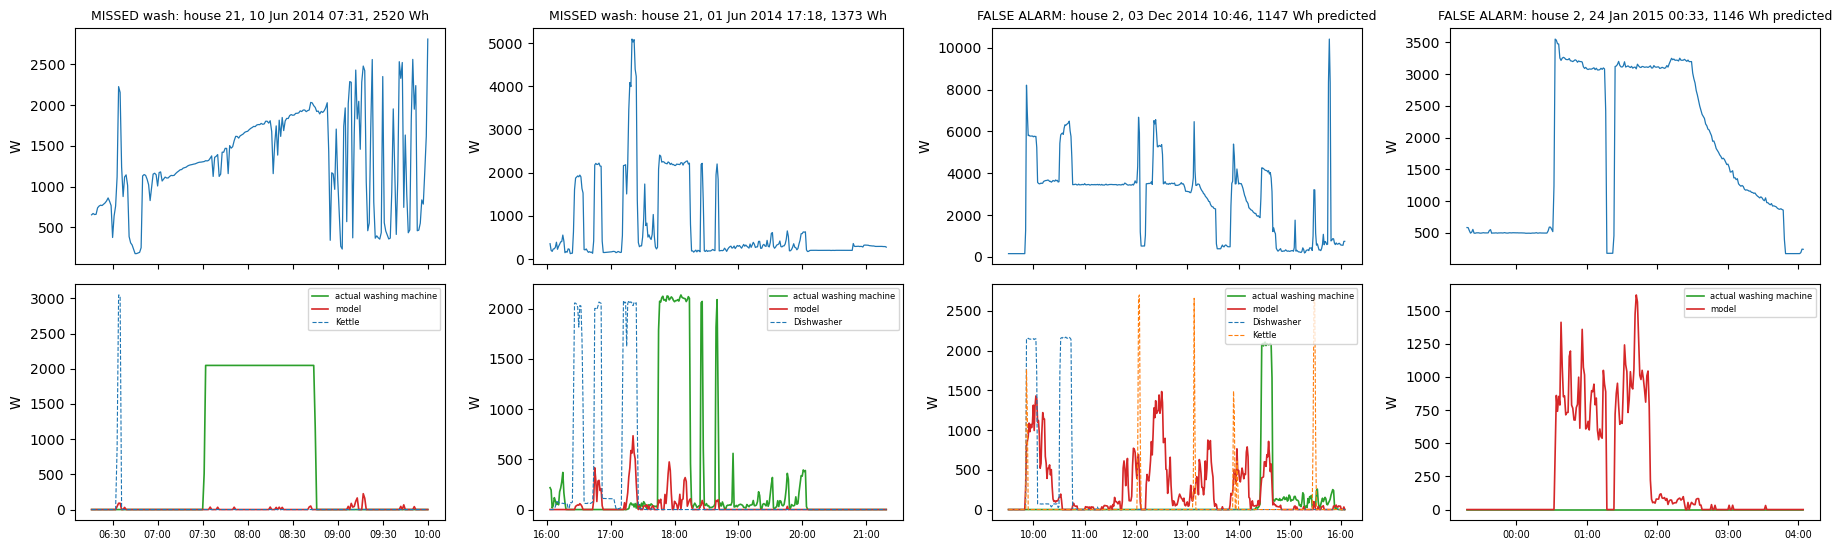

Dashed lines are other monitored heating-type appliances that ran in the window (for explanation only; the model never sees them).


In [50]:
def window(h, s_i, e_i, pad=75):
    lo, hi = max(int(s_i) - pad, 0), min(int(e_i) + pad, len(M[h]))
    return slice(lo, hi)

def case_plot(ax2, h, sl, title):
    r = R[h].iloc[sl]; A = ALLCH[h].iloc[sl]
    ax2[0].plot(r.index, r["agg"], lw=0.9, color="tab:blue", label="aggregate"); ax2[0].set_ylabel("W"); ax2[0].set_title(title, fontsize=9)
    ax2[1].plot(r.index, r["y"], lw=1.2, color="tab:green", label="actual washing machine")
    ax2[1].plot(r.index, r["gbm"], lw=1.2, color="tab:red", label="model")
    oc = [c for c in A.columns if not is_wm_col(h, c) and category(c) != "other monitored" and (A[c] > HOT_W).any()]
    for c in oc[:3]:
        ax2[1].plot(A.index, A[c], lw=0.8, ls="--", label=c.split(" [")[0])
    ax2[1].legend(fontsize=6, loc="upper right"); ax2[1].set_ylabel("W")
    ax2[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax2[1].tick_params(axis="x", labelsize=7)

missed = Tg[~Tg["found"]].sort_values("energy_wh", ascending=False).head(2)
false_ = Pg[~Pg["correct"]].sort_values("energy_wh", ascending=False).head(2)
cases = [("MISSED wash", r_["house"], r_["start_i"], r_["end_i"], f"{r_['energy_wh']:.0f} Wh") for _, r_ in missed.iterrows()] + \
        [("FALSE ALARM", r_["house"], r_["start_i"], r_["end_i"], f"{r_['energy_wh']:.0f} Wh predicted") for _, r_ in false_.iterrows()]
if cases:
    fig, axes = plt.subplots(2, len(cases), figsize=(4.6 * len(cases), 5.6), sharex="col", squeeze=False)
    for j, (kind, h, s_i, e_i, lab) in enumerate(cases):
        sl = window(int(h), s_i, e_i)
        case_plot(axes[:, j], int(h), sl, f"{kind}: house {int(h)}, {M[int(h)].index[int(s_i)]:%d %b %Y %H:%M}, {lab}")
    plt.tight_layout(); savefig("task3_failure_cases"); plt.show()
else:
    print("no missed washes or false alarms to plot")
print("Dashed lines are other monitored heating-type appliances that ran in the window (for explanation only; the model never sees them).")

#### Error analysis
The plot shows the two biggest misses and two biggest false alarms. Dashed lines mark other heavy appliances running at the time.

- **False alarms:** 2,412 predicted cycles vs 908 actual cycles; only 35% of predictions were correct. Recall was higher when other heavy loads ran during a wash (73% vs 27%), suggesting the model partly detects heavy power usage rather than washing itself.
- **Other heating loads:** Dishwashers appeared in 25% of false-alarm minutes vs 1.4% of all minutes. Kettles, microwaves and toasters accounted for 7% vs 0.8%; unmonitored loads above 1 kW, such as cookers and showers, accounted for 41% vs 5.5%.
- **Energy per wash:** Median energy was underestimated by about 53%, even when a wash was detected.
- **Cold/eco washes:** Recall was 24% for washes without a heating burst, compared with 57% for heated washes. Only 42 cold/eco washes were available.
- **Household differences:** F1 ranged from 0.20 (H21) to 0.55 (H13), while recall ranged from 0.31 (H2) to 0.88 (H6).

In [51]:
p = TT.xs("pooled", level="house"); pg, po, pp = p.loc["gradient boosting"], p.loc["always off"], p.loc["hour-of-week profile"]
hv = TT.xs("gradient boosting", level="model").drop(index="pooled")
print("TASK 3 SUMMARY (numbers come from this run)")
print(f"- Train houses {SPLIT['train']}, validation {SPLIT['val']}, test {SPLIT['test']} (all unseen by the model); 1-minute resolution; usable minutes only (valid, Issues = 0).")
print(f"- Model: gradient boosting, {BEST['it']} trees, {BEST['cfg']}; on/off threshold tau = {TAU['gbm_raw']} W chosen on validation.")
print(f"- Test, pooled: NDE {pg['NDE']:.2f} (always off {po['NDE']:.2f}, profile {pp['NDE']:.2f}); on-state F1 {pg['F1']:.2f} (profile {pp['F1']:.2f}, always off {po['F1']:.2f}); "
      f"MAE-on {pg['MAE_on_W']:.0f} W (always off {po['MAE_on_W']:.0f}, profile {pp['MAE_on_W']:.0f}).")
print(f"- Plain MAE: model {pg['MAE_W']:.1f} W vs always off {po['MAE_W']:.1f} W"
      + (" -> always off looks as good or better on plain MAE, which is why MAE alone is not used." if po["MAE_W"] <= pg["MAE_W"] else " -> the model also wins on plain MAE."))
print(f"- Energy bias (SAE) pooled {pg['SAE_pct']:+.1f}% (per house {hv['SAE_pct'].min():+.1f}% to {hv['SAE_pct'].max():+.1f}%); daily energy MAE {pg['day_MAE_Wh']:.0f} Wh vs {po['day_MAE_Wh']:.0f} Wh for always off, correlation {pg['day_corr']:.2f}.")
print(f"- On-state F1 per test house: {hv['F1'].min():.2f} (H{hv['F1'].idxmin()}) to {hv['F1'].max():.2f} (H{hv['F1'].idxmax()}).")
cg = cyc_tab.loc["gradient boosting"]
print(f"- Whole washes: found {cg['found']:.0f} of {cg['true_cycles']:.0f} ({100 * cg['recall']:.0f}%), {100 * cg['precision']:.0f}% of {cg['predicted_cycles']:.0f} predicted cycles are real; "
      f"median absolute error in energy per found wash {cg['median_abs_energy_err_pct_found']:.0f}%.")
best_cat = agg_fp["enrichment_x"].idxmax()
print(f"- Largest false-alarm enrichment: {best_cat} ({agg_fp.loc[best_cat, 'enrichment_x']:.1f}x more likely to be running during false alarms than in general).")
beats = (pg["NDE"] < pp["NDE"]) and (pg["NDE"] < po["NDE"])
print("- Verdict on this run:", "the model beats both baselines on NDE." if beats else "the model does NOT beat both baselines on NDE; do not present it as useful without more work.")

TASK 3 SUMMARY (numbers come from this run)
- Train houses [11, 18, 15, 9, 19, 1, 16, 8, 10, 5, 7], validation [20, 17, 3], test [6, 21, 2, 13] (all unseen by the model); 1-minute resolution; usable minutes only (valid, Issues = 0).
- Model: gradient boosting, 214 trees, {'max_leaf_nodes': 15}; on/off threshold tau = 30 W chosen on validation.
- Test, pooled: NDE 0.63 (always off 1.00, profile 1.00); on-state F1 0.36 (profile 0.11, always off 0.00); MAE-on 261 W (always off 379, profile 368).
- Plain MAE: model 17.2 W vs always off 13.6 W -> always off looks as good or better on plain MAE, which is why MAE alone is not used.
- Energy bias (SAE) pooled +1.3% (per house -7.7% to +22.9%); daily energy MAE 220 Wh vs 312 Wh for always off, correlation 0.75.
- On-state F1 per test house: 0.20 (H21) to 0.55 (H13).
- Whole washes: found 503 of 908 (55%), 35% of 2412 predicted cycles are real; median absolute error in energy per found wash 54%.
- Largest false-alarm enrichment: dishwasher (17.8

## 4. Practical implications

### 4.1 Opportunity: shift evening washes away from peak hours
Use smart-meter data to identify evening washing and encourage households to use delayed start. No new hardware is needed.

The saving per home is small: the median home uses about 12 kWh a year for washing between 16:00 and 19:00 (around 11 W on average). The benefit comes from shifting demand across many homes and engaging customers, rather than reducing individual bills. In India, the relevant window would depend on the local peak, often 18:00–22:00, or the state's time-of-day tariff.

The opportunity is estimated from actual washing cycles in the REFIT homes, not model predictions. A model could help utilities track peak-hour washing over time, but its peak-share error is large (see 4.1(b)), so calibration is needed before operational use.

In [52]:
PEAK = (16, 19)                    # local hours [16, 19)
in_peak = lambda hr: (hr >= PEAK[0]) & (hr < PEAK[1])
yrs = lambda n_days: n_days / 365.25

# ---- (a) How big is the opportunity? True cycles of all Task 2 houses (sub-metered ground truth) ----
rows = []
for h in selected:
    c = CT[CT["house"] == h]
    if len(c) < 20: continue
    wk = c.groupby("dow").size().sum() / (DAYS[h]["usable"].sum() / 7)           # cycles per usable week
    pk = in_peak(c["hour"])
    rows.append({"house": h, "occupants": OCCUPANTS[h], "washes_per_week": wk, "pct_washes_in_peak": 100 * pk.mean(),
                 "pct_wash_energy_in_peak": 100 * c.loc[pk, "energy_kwh"].sum() / c["energy_kwh"].sum(),
                 "peak_kwh_per_year": wk * 52 * c.loc[pk, "energy_kwh"].sum() / len(c)})
opp = pd.DataFrame(rows).set_index("house")
print(f"Houses with 20+ usable washes: {len(opp)}. Peak window {PEAK[0]:02d}:00-{PEAK[1]:02d}:00.")
print(opp.describe().loc[["min", "25%", "50%", "75%", "max"]].round(2).to_string())
top = opp.sort_values("pct_wash_energy_in_peak", ascending=False).head(5)
print(f"\nMedian wash energy inside the peak window: {opp['peak_kwh_per_year'].median():.1f} kWh per household-year "
      f"(top quarter of households: {opp['peak_kwh_per_year'].quantile(.75):.1f}). Shiftable energy is small; what matters is the shape of the evening demand across many homes.")
print("Households with the highest share of wash energy in the peak (the nudge targets):"); print(top.round(1).to_string())
opp.to_csv(OUT_DIR / "tables" / "task4_peak_opportunity.csv")

# ---- (b) Can the model measure it? Peak share of wash ENERGY, model vs sub-meter, on the unseen test houses ----
rows = []
for h in SPLIT["test"]:
    r = R[h]; ok = r["ok"].to_numpy(); pk = in_peak(r["hour"].to_numpy()) & ok
    rows.append({"house": h, "true_pct_in_peak": 100 * r["y"].to_numpy()[pk].sum() / r["y"].to_numpy()[ok].sum(),
                 "model_pct_in_peak": 100 * r["gbm"].to_numpy()[pk].sum() / r["gbm"].to_numpy()[ok].sum()})
mt = pd.DataFrame(rows).set_index("house"); mt["error_pp"] = mt["model_pct_in_peak"] - mt["true_pct_in_peak"]
print("\nTest houses: share of washing-machine energy in the peak window, truth vs model (percentage points):")
print(mt.round(1).to_string())
print(f"Mean absolute error {mt['error_pp'].abs().mean():.1f} pp; spread of the true share across the same houses {mt['true_pct_in_peak'].std():.1f} pp (sd). "
      + (f"Spearman rank agreement {mt[['true_pct_in_peak', 'model_pct_in_peak']].corr(method='spearman').iloc[0, 1]:.2f}." if len(mt) >= 5 else "Too few test houses to judge how well it ranks households."))
mt.to_csv(OUT_DIR / "tables" / "task4_peak_share_model_vs_truth.csv")

Houses with 20+ usable washes: 19. Peak window 16:00-19:00.
     occupants  washes_per_week  pct_washes_in_peak  pct_wash_energy_in_peak  peak_kwh_per_year
min        1.0             1.45                0.58                     0.08               0.05
25%        2.0             3.49                3.09                     2.74               1.65
50%        2.0             4.50               10.00                     9.25              12.31
75%        4.0             5.52               16.71                    16.80              27.82
max        6.0            10.75               34.36                    37.47              75.29

Median wash energy inside the peak window: 12.3 kWh per household-year (top quarter of households: 27.8). Shiftable energy is small; what matters is the shape of the evening demand across many homes.
Households with the highest share of wash energy in the peak (the nudge targets):
       occupants  washes_per_week  pct_washes_in_peak  pct_wash_energy_in_peak  p

Peak washing is uneven: the median home does ~10% of its washes in the window, the top homes (H16, H10, H9) 25-35%, so those are the nudge targets. On the unseen test homes the model overstates the peak share in every house (+2 to +9 pp, mean error 4.7 pp), about as large as the effect we want to detect.

### Robustness: clock (peak window)
A 1–2 hour clock error can shift washes into or out of the peak window. Part (a) repeats the opportunity estimates using all three clock versions. Part (b) compares model and actual peak shares using November–March data only, when timestamps are reliable. All versions use the same households, each with at least 10 November–March washes, so differences reflect clock choice rather than household selection.

In [53]:
# ---- (a) opportunity numbers under each reading of the clock (same houses in every row) ----
def opp_variant(hours, mask, day_ok):
    rows = []
    for h in clock_houses:
        sel = (CT["house"] == h) & mask
        c, hr = CT[sel], hours[sel].to_numpy()
        d = DAYS[h]; nd = int(d["usable"][day_ok(d.index)].sum())
        if len(c) == 0 or nd == 0: continue
        pk = in_peak(hr); wk = len(c) / (nd / 7)
        rows.append({"house": h, "pct_washes_in_peak": 100 * pk.mean(),
                     "pct_wash_energy_in_peak": 100 * c.loc[pk, "energy_kwh"].sum() / c["energy_kwh"].sum(),
                     "peak_kwh_per_year": wk * 52 * c.loc[pk, "energy_kwh"].sum() / len(c)})
    return pd.DataFrame(rows).set_index("house")

all_days = lambda idx: np.ones(len(idx), bool)
variants = {"all year, stamps read as UK local": (hour_stored, all_rows, all_days),
            "all year, stamps read as UTC -> UK": (hour_london, all_rows, all_days),
            "Nov-Mar only (clock-proof)": (hour_stored, CT_winter, is_winter)}
rows = []
for name, (hrs, mk, dk) in variants.items():
    o = opp_variant(hrs, mk, dk)
    rows.append({"version": name, "houses": len(o), "median_pct_washes_in_peak": o["pct_washes_in_peak"].median(),
                 "median_pct_energy_in_peak": o["pct_wash_energy_in_peak"].median(),
                 "median_peak_kwh_per_year": o["peak_kwh_per_year"].median(),
                 "top_quarter_peak_kwh_per_year": o["peak_kwh_per_year"].quantile(.75)})
opp_clock = pd.DataFrame(rows).set_index("version")
print(f"Peak window {PEAK[0]:02d}:00-{PEAK[1]:02d}:00 UK time, houses: {clock_houses}")
print(opp_clock.round(1).to_string())
opp_clock.to_csv(OUT_DIR / "tables" / "task4_peak_opportunity_clock_robustness.csv")
sp = opp_clock["median_pct_washes_in_peak"]
print(f"\nMedian share of washes in the peak window ranges {sp.min():.1f}-{sp.max():.1f}% across the three versions "
      f"(Nov-Mar only: {sp.iloc[2]:.1f}%).")

# ---- (b) model vs sub-meter peak share on the test houses, Nov-Mar only ----
rows = []
for h in SPLIT["test"]:
    r = R[h]; ok = r["ok"].to_numpy() & is_winter(r.index)
    if ok.sum() < 20 * 1440 or r["y"].to_numpy()[ok].sum() <= 0 or r["gbm"].to_numpy()[ok].sum() <= 0: continue
    pk = in_peak(r["hour"].to_numpy()) & ok            # in Nov-Mar the hour is the same under both clock readings
    rows.append({"house": h, "true_pct_in_peak": 100 * r["y"].to_numpy()[pk].sum() / r["y"].to_numpy()[ok].sum(),
                 "model_pct_in_peak": 100 * r["gbm"].to_numpy()[pk].sum() / r["gbm"].to_numpy()[ok].sum()})
mt_w = pd.DataFrame(rows).set_index("house"); mt_w["error_pp"] = mt_w["model_pct_in_peak"] - mt_w["true_pct_in_peak"]
print("\nTest houses, Nov-Mar only: share of washing energy in the peak window, truth vs model (pp):")
print(mt_w.round(1).to_string())
print(f"Mean absolute error {mt_w['error_pp'].abs().mean():.1f} pp (all-year version above: {mt['error_pp'].abs().mean():.1f} pp). "
      f"Model above truth in {(mt_w['error_pp'] > 0).sum()} of {len(mt_w)} houses.")
mt_w.to_csv(OUT_DIR / "tables" / "task4_peak_share_model_vs_truth_nov_mar.csv")

Peak window 16:00-19:00 UK time, houses: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16, 17, 18, 19, 20, 21]
                                    houses  median_pct_washes_in_peak  median_pct_energy_in_peak  median_peak_kwh_per_year  top_quarter_peak_kwh_per_year
version                                                                                                                                                  
all year, stamps read as UK local       19                       10.0                        9.3                      12.3                           27.8
all year, stamps read as UTC -> UK      19                       11.9                        9.8                      12.8                           29.7
Nov-Mar only (clock-proof)              19                       10.3                       10.6                       9.9                           39.4

Median share of washes in the peak window ranges 10.0-11.9% across the three versions (Nov-Mar only: 10.3%).

Test house

**How to read this:** if the Nov-Mar row is close to the two all-year rows, the peak-window numbers do not hinge on the clock. If the all-year rows differ from each other by a lot, the all-year numbers above are only good to the width of that gap and the Nov-Mar row is the one to quote. The block-to-block spread used for the sample-size table (4.1, how I'd measure it) was **not** recomputed on Nov-Mar, because 8-week blocks inside five winter months are too few; treat those sample sizes as rough.

### How I'd measure whether it worked
Run a randomised trial with households that opt in to smart-meter monitoring. The treatment group receives monthly laundry-timing messages and delayed-start prompts; the control group receives no messages. Compare each home's results with its own 8-week baseline.

- **Metric:** Change in the share of washing energy used during peak hours, measured over 8 weeks before and after the intervention. Also track peak-window kW. Guardrails: total washing energy, number of washes and opt-outs.
- **Measurement error:** The model overestimates peak share by about 5 percentage points. Use a small panel with plug meters or laundry diaries to check this bias.
- **Sample size:** Estimate from the variation in each home's peak share between two untreated 8-week periods in REFIT (SD: 9.3 percentage points).

In [54]:
BLOCK_D = 56                                    # 8-week blocks
def block_shares(c, usable_dates):
    """Per house: share of wash energy in the peak, per consecutive 8-week block (blocks with fewer than 10 washes dropped)."""
    out = []
    for h, g in c.groupby("house"):
        d0 = g["date"].min()
        blk = ((g["date"] - d0).dt.days // BLOCK_D)
        for b, gg in g.groupby(blk):
            if len(gg) >= 10:
                out.append({"house": h, "block": int(b), "share": gg.loc[in_peak(gg["hour"]), "energy_kwh"].sum() / gg["energy_kwh"].sum()})
    return pd.DataFrame(out)

bs = block_shares(CT, None)
bs = bs.sort_values(["house", "block"])
bs["delta"] = bs.groupby("house")["share"].diff()
dl = bs["delta"].dropna()
sd_true = dl.std()
print(f"Between consecutive untreated 8-week blocks, a household's peak share of wash energy changes by sd = {100 * sd_true:.1f} pp "
      f"(median |change| {100 * dl.abs().median():.1f} pp, {len(dl)} house-block pairs, {bs['house'].nunique()} houses).")

# same thing with the MODEL's estimate on the test houses (adds the model's own noise)
rows = []
for h in SPLIT["test"]:
    r = R[h]; ok = r["ok"].to_numpy(); d = r["date"].to_numpy()
    df = pd.DataFrame({"blk": ((r["date"] - r["date"][ok].min()).dt.days // BLOCK_D).to_numpy(), "pk": in_peak(r["hour"].to_numpy()), "ok": ok, "y": r["y"].to_numpy(), "p": r["gbm"].to_numpy()})
    df = df[df["ok"]]
    for b, g in df.groupby("blk"):
        if (g["y"] > ACTIVE_W).sum() >= 100 and len(g) >= 0.5 * BLOCK_D * 1440:
            rows.append({"house": h, "block": int(b), "true": g.loc[g["pk"], "y"].sum() / g["y"].sum(), "model": g.loc[g["pk"], "p"].sum() / g["p"].sum()})
tb = pd.DataFrame(rows).sort_values(["house", "block"])
for k in ["true", "model"]:
    tb["d_" + k] = tb.groupby("house")[k].diff()
sd_model = tb["d_model"].dropna().std(); sd_tr = tb["d_true"].dropna().std()
print(f"Test houses only ({len(tb['d_model'].dropna())} pairs): sd of the change {100 * sd_tr:.1f} pp with sub-meter truth, {100 * sd_model:.1f} pp with the model's estimate.")

alpha, power = 0.05, 0.8
z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
sd_use = np.nanmax([sd_true, sd_model]) if np.isfinite(sd_model) else sd_true
print(f"\nHomes needed PER ARM (randomised, before/after change per home compared between arms; two-sided 5%, 80% power), using sd = {100 * sd_use:.1f} pp:")
need = pd.DataFrame({"effect_pp": [3, 5, 10]}); need["homes_per_arm"] = np.ceil(2 * (z * sd_use / (need["effect_pp"] / 100)) ** 2).astype(int)
print(need.to_string(index=False))
print("Caveat: the sd comes from at most 19 UK homes; it is a planning number, not a guarantee. Run a pilot first and re-estimate.")

Between consecutive untreated 8-week blocks, a household's peak share of wash energy changes by sd = 9.3 pp (median |change| 4.9 pp, 154 house-block pairs, 19 houses).
Test houses only (29 pairs): sd of the change 9.9 pp with sub-meter truth, 5.6 pp with the model's estimate.

Homes needed PER ARM (randomised, before/after change per home compared between arms; two-sided 5%, 80% power), using sd = 9.3 pp:
 effect_pp  homes_per_arm
         3            152
         5             55
        10             14
Caveat: the sd comes from at most 19 UK homes; it is a planning number, not a guarantee. Run a pilot first and re-estimate.


A 5 pp shift needs ~55 homes per arm, 3 pp ~150 and 10 pp ~14 (80% power, 5% significance). This is based on 19 UK homes, so a pilot should re-check it.

### 4.2 Limitations
- **Overlapping signatures:** dishwashers, dryers, kettles and heaters look like the washer's heating burst (see failure analysis). Whole-cycle shapes and finer data (1 s, reactive power) would help.
- **Missing data:** 6-25% of minutes per house have no reading, and forward-filled flat lines hide dead sensors. We never train or score on those, so a deployed system must not report "no washing" for a missing day.
- **Household differences:** F1 ranges from 0.20 to 0.55 across only 4 test homes. A few labelled weeks per home would likely help.
- **Clock:** the cleaned timestamps are inconsistent in some months (Task 2), which blurs hour-of-day and peak-window numbers by 1 h or more in summer months. Nov-Mar-only versions of both results are shown next to the all-year ones (see the *Robustness: clock* cells).


### 4.3 What gets harder with 15- or 30-minute data?
Same houses, split and model, only the resolution changes (block means of the 1-minute data, re-tuned on validation).

  15-min {'max_leaf_nodes': 15}: best validation MSE 11,165 at 112 trees (MSE after 300: 11,247)
15-min: 112 trees, tau 30 W, 18 s
  30-min {'max_leaf_nodes': 15}: best validation MSE 8,273 at 72 trees (MSE after 300: 8,542)
30-min: 72 trees, tau 40 W, 8 s
TEST houses, pooled, by resolution (active = block-mean power above 20 W):
                                      NDE  F1_on  SAE_pct  MAE_on_W  day_MAE_Wh  day_corr
resolution_min model                                                                     
1              always off            1.00   0.00  -100.00    378.65      312.02       NaN
               hour-of-week profile  1.00   0.11   -52.90    367.76      343.69      0.05
               gradient boosting     0.63   0.36     1.32    261.50      219.74      0.75
15             always off            1.00   0.00  -100.00    335.89      324.90       NaN
               hour-of-week profile  0.99   0.12   -50.91    323.36      356.49      0.06
               gradient boosting     0

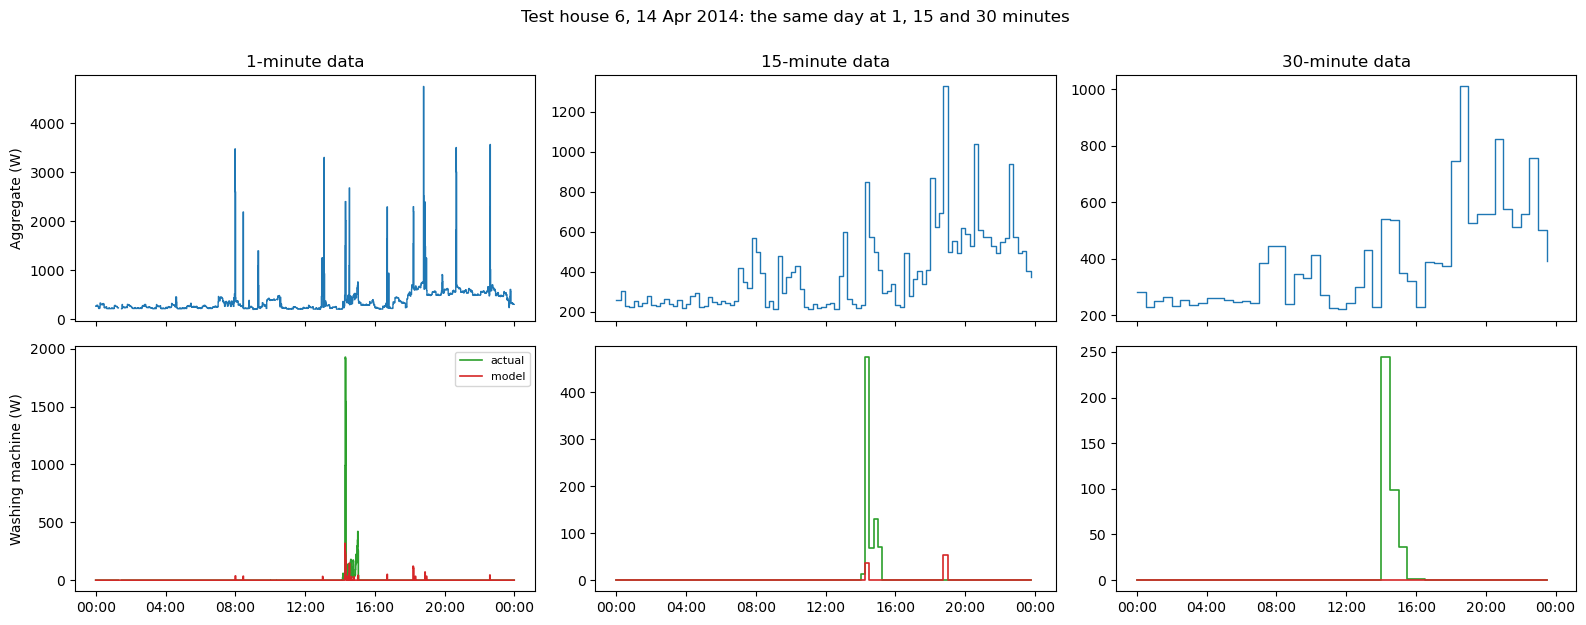

In [55]:
RES_LIST = [1, 15, 30]
RR = {1: R}; RT = {1: TT}
for res in RES_LIST[1:]:
    t0 = time.time()
    tr, va = stack(SPLIT["train"], res), stack(SPLIT["val"], res)
    mdl, best = fit_gbm(tr, va, grid=[BEST["cfg"]], label=f"{res}-min ")
    prof = fit_profile(SPLIT["train"], res)
    Rr = {h: predict_house(h, mdl, prof, res) for h in SPLIT["val"] + SPLIT["test"]}
    taus = {c: tune_tau({h: Rr[h] for h in SPLIT["val"]}, c)[0] for c in ["profile", "gbm_raw"]}
    for r in Rr.values():
        r["gbm"] = np.where(r["gbm_raw"] >= taus["gbm_raw"], r["gbm_raw"], 0.0).astype("float32")
        r["profile"] = np.where(r["profile"] >= taus["profile"], r["profile"], 0.0).astype("float32")
    RR[res], RT[res] = Rr, metric_table(Rr, SPLIT["test"], res=res)
    print(f"{res}-min: {best['it']} trees, tau {taus['gbm_raw']} W, {time.time() - t0:.0f} s")

rows = []
for res in RES_LIST:
    T_ = RT[res].xs("pooled", level="house")
    for name in ["always off", "hour-of-week profile", "gradient boosting"]:
        s = T_.loc[name]; rows.append({"resolution_min": res, "model": name, "NDE": s["NDE"], "F1_on": s["F1"], "SAE_pct": s["SAE_pct"],
                                       "MAE_on_W": s["MAE_on_W"], "day_MAE_Wh": s["day_MAE_Wh"], "day_corr": s["day_corr"]})
rt = pd.DataFrame(rows).set_index(["resolution_min", "model"])
print("TEST houses, pooled, by resolution (active = block-mean power above 20 W):"); print(rt.round(2).to_string())
rt.to_csv(OUT_DIR / "tables" / "task4_resolution_test.csv")

med_dur, med_heat = CS["dur_min"].median(), CS.loc[CS["heated"], "heat_min"].median()
print(f"\nA typical wash lasts {med_dur:.0f} min and its heating bursts about {med_heat:.0f} min (median over usable cycles, Task 2). "
      + " ".join(f"At {r} min: {med_dur / r:.1f} samples per wash, a heating burst is {med_heat / r:.1f} samples long." for r in RES_LIST[1:]))
g = rt.xs("gradient boosting", level="model")
print(f"Model on-state F1 {g.loc[1, 'F1_on']:.2f} -> {g.loc[15, 'F1_on']:.2f} -> {g.loc[30, 'F1_on']:.2f}; NDE {g.loc[1, 'NDE']:.2f} -> {g.loc[15, 'NDE']:.2f} -> {g.loc[30, 'NDE']:.2f}; "
      f"daily-energy correlation {g.loc[1, 'day_corr']:.2f} -> {g.loc[15, 'day_corr']:.2f} -> {g.loc[30, 'day_corr']:.2f} (1 -> 15 -> 30 min).")

# one wash seen at the three resolutions (same test house and day as the plot above)
fig, ax = plt.subplots(2, 3, figsize=(16, 6.2), sharex=True)
for j, res in enumerate(RES_LIST):
    d = RR[res][rep_h]; d = d[d["date"] == rep_day]
    ax[0, j].step(d.index, d["agg"], where="post", lw=1.0, color="tab:blue"); ax[0, j].set_title(f"{res}-minute data")
    ax[1, j].step(d.index, d["y"], where="post", lw=1.2, color="tab:green", label="actual")
    ax[1, j].step(d.index, d["gbm"], where="post", lw=1.2, color="tab:red", label="model")
    ax[1, j].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax[1, j].xaxis.set_major_locator(mdates.HourLocator(interval=4))
ax[0, 0].set_ylabel("Aggregate (W)"); ax[1, 0].set_ylabel("Washing machine (W)"); ax[1, 0].legend(fontsize=8)
plt.suptitle(f"Test house {rep_h}, {rep_day:%d %b %Y}: the same day at 1, 15 and 30 minutes", y=1.0)
plt.tight_layout(); savefig("task4_resolution_comparison"); plt.show()

A wash lasts about 70 minutes and is identified by its pattern: a 13-minute heating burst at around 2 kW, followed by low-power tumbling and a spin. At 15-minute resolution, a wash spans only about five samples and the heating burst lasts less than one. At 30 minutes, the burst blends into the rest of the cycle.

On the test houses, F1 falls from 0.36 to 0.31, NDE rises from 0.63 to 0.77–0.80, daily-energy correlation drops from 0.75 to 0.60–0.66, and SAE shifts from +1% to −11% to −15%.

Coarser resolution makes wash timing less precise and similar-power appliances harder to distinguish. Wash counts and energy per wash become less reliable, while daily totals and time-of-day patterns remain more useful. Weekly totals may also be useful, but were not tested.